In [1]:
#!pip install scikit-learn
#!pip install lime
#!pip install shap
#!pip install keras
#!pip install tensorflow

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D
from matplotlib.colors import TwoSlopeNorm
import seaborn as sns
from scipy import stats
from statsmodels.stats.contingency_tables import mcnemar
from IPython.display import display, HTML

import keras
import tensorflow as tf
from keras import layers

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.inspection import PartialDependenceDisplay
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay)

from lime.lime_tabular import LimeTabularExplainer
import shap

C:\Users\juann\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Entendimiento y preparación de los datos
(1)

In [3]:
df = pd.read_csv("churn.csv")
df.head()

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,418.0,France,Female,46.0,9,0.00,1,1,1,81014.50,1
1,689.0,Germany,Male,67.0,9,157094.78,1,1,1,99490.01,0
2,477.0,Spain,Female,48.0,2,129120.64,1,0,1,26475.79,0
3,573.0,Germany,Female,35.0,9,206868.78,2,0,1,102986.15,0
4,849.0,France,Male,69.0,7,71996.09,1,1,1,139065.94,0


In [4]:
df.shape                        # (número de filas, número de columnas)
df.dtypes                       # tipo de dato de cada columna
df.info()                       # tipos, valores no nulos y memoria en una sola vista
df.describe()                   # estadísticas de las columnas numéricas
df.describe(include="object")   # conteo, valores únicos y moda de las columnas de texto

<class 'pandas.DataFrame'>
RangeIndex: 10045 entries, 0 to 10044
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   credit_score      9795 non-null   float64
 1   country           10045 non-null  str    
 2   gender            10045 non-null  str    
 3   age               9745 non-null   float64
 4   tenure            10045 non-null  int64  
 5   balance           9845 non-null   float64
 6   products_number   10045 non-null  int64  
 7   credit_card       10045 non-null  int64  
 8   active_member     10045 non-null  int64  
 9   estimated_salary  9695 non-null   float64
 10  churn             10045 non-null  int64  
dtypes: float64(4), int64(5), str(2)
memory usage: 970.3 KB


C:\Users\juann\AppData\Local\Temp\ipykernel_38364\2182232813.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")   # conteo, valores únicos y moda de las columnas de texto


,country,gender
count,10045,10045
unique,9,4
top,France,Male
freq,5003,5464


In [5]:
df["country"].unique()

<ArrowStringArray>
[  'France',  'Germany',    'Spain',  'GERMANY',   'FRANCE',    'SPAIN',
   'spain ',  'france ', 'germany ']
Length: 9, dtype: str

In [6]:
df["gender"].unique()   

<ArrowStringArray>
['Female', 'Male', 'F', 'M']
Length: 4, dtype: str

In [7]:
numericas = df.select_dtypes(include="number").columns.tolist()
categoricas = df.select_dtypes(include="object").columns.tolist()
print(f"Numéricas\n{numericas}\n\nCategóricas\n{categoricas}")

Numéricas
['credit_score', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']

Categóricas
['country', 'gender']


C:\Users\juann\AppData\Local\Temp\ipykernel_38364\637222743.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include="object").columns.tolist()


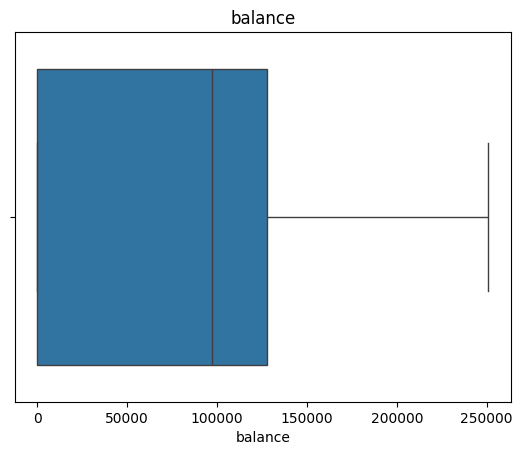

In [8]:
sns.boxplot(x=df["balance"])
plt.title("balance")
plt.show()

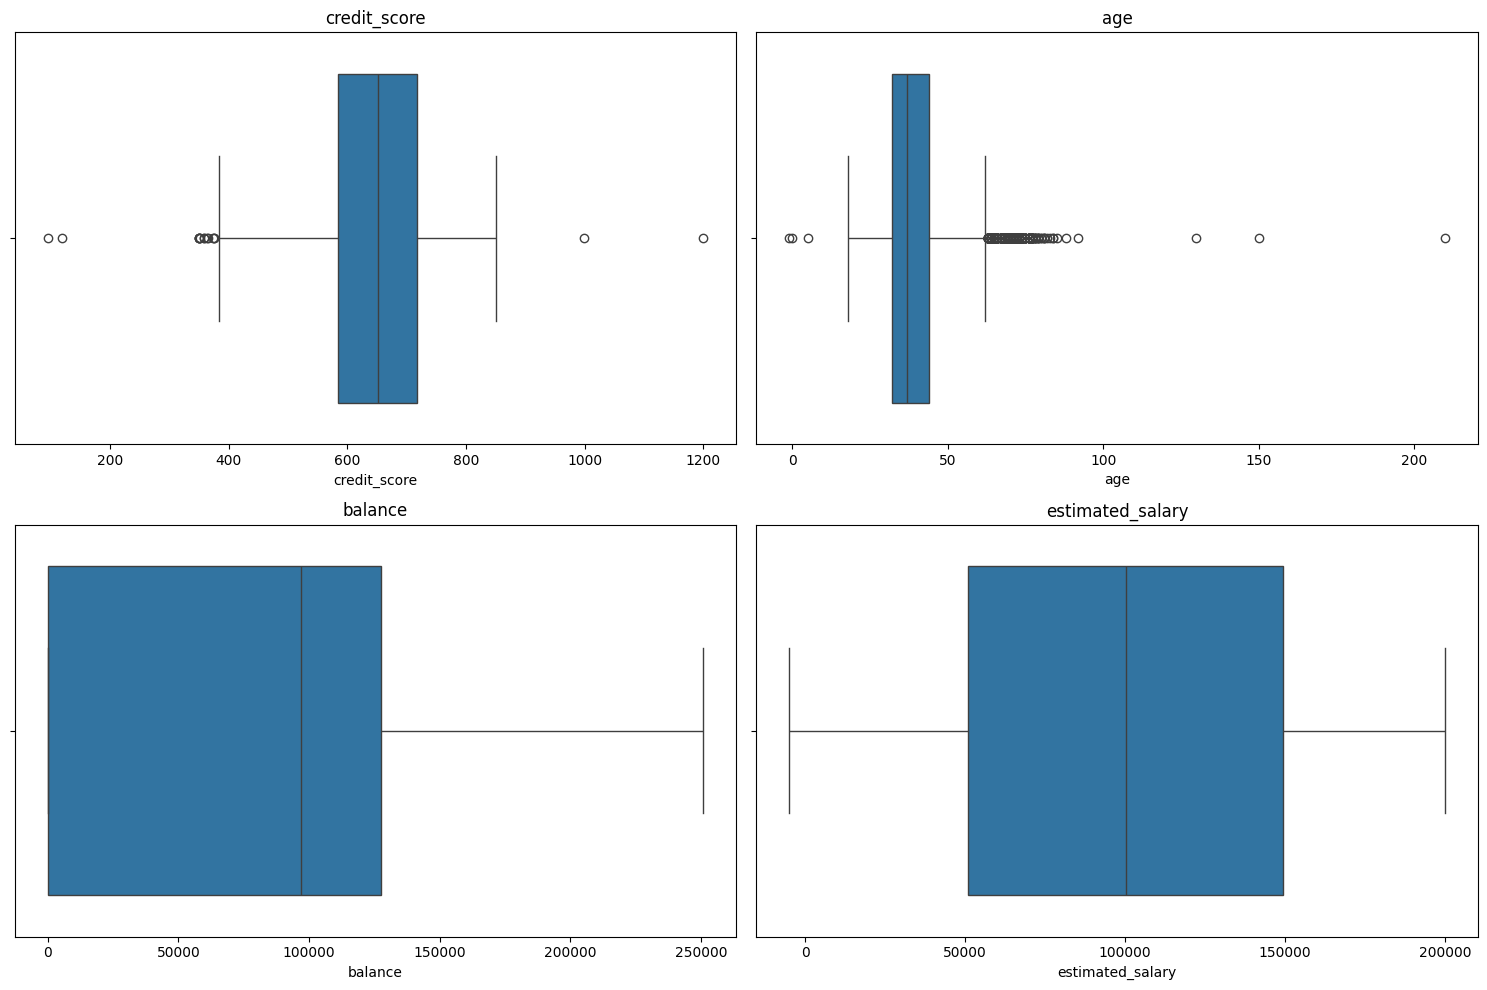

In [9]:
columnas = ['credit_score', 'age','balance','estimated_salary']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten() 

for ax, columna in zip(axes, columnas):
    sns.boxplot(x=df[columna], ax=ax)
    ax.set_title(columna)

plt.tight_layout()
plt.show()

credit_score y age presentan valores atípicos, sobre todo la edad, y además valores por fuera del rango válido del diccionario de datos (puntaje entre 300 y 850 y edad entre 18 y 100), que se tratan en la sección de calidad. En balance, la mitad de los clientes tiene un saldo menor a 97.000 aproximadamente, con una gran concentración en 0 que corresponde al 35,6% de los registros. El salario estimado se reparte de forma pareja en todo su rango.

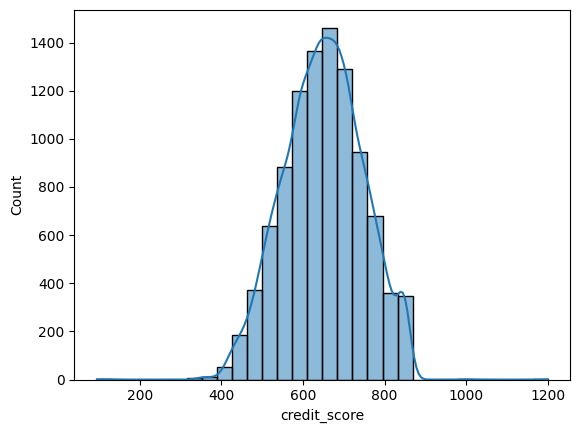

In [10]:
sns.histplot(df["credit_score"], bins=30, kde=True)
plt.show()

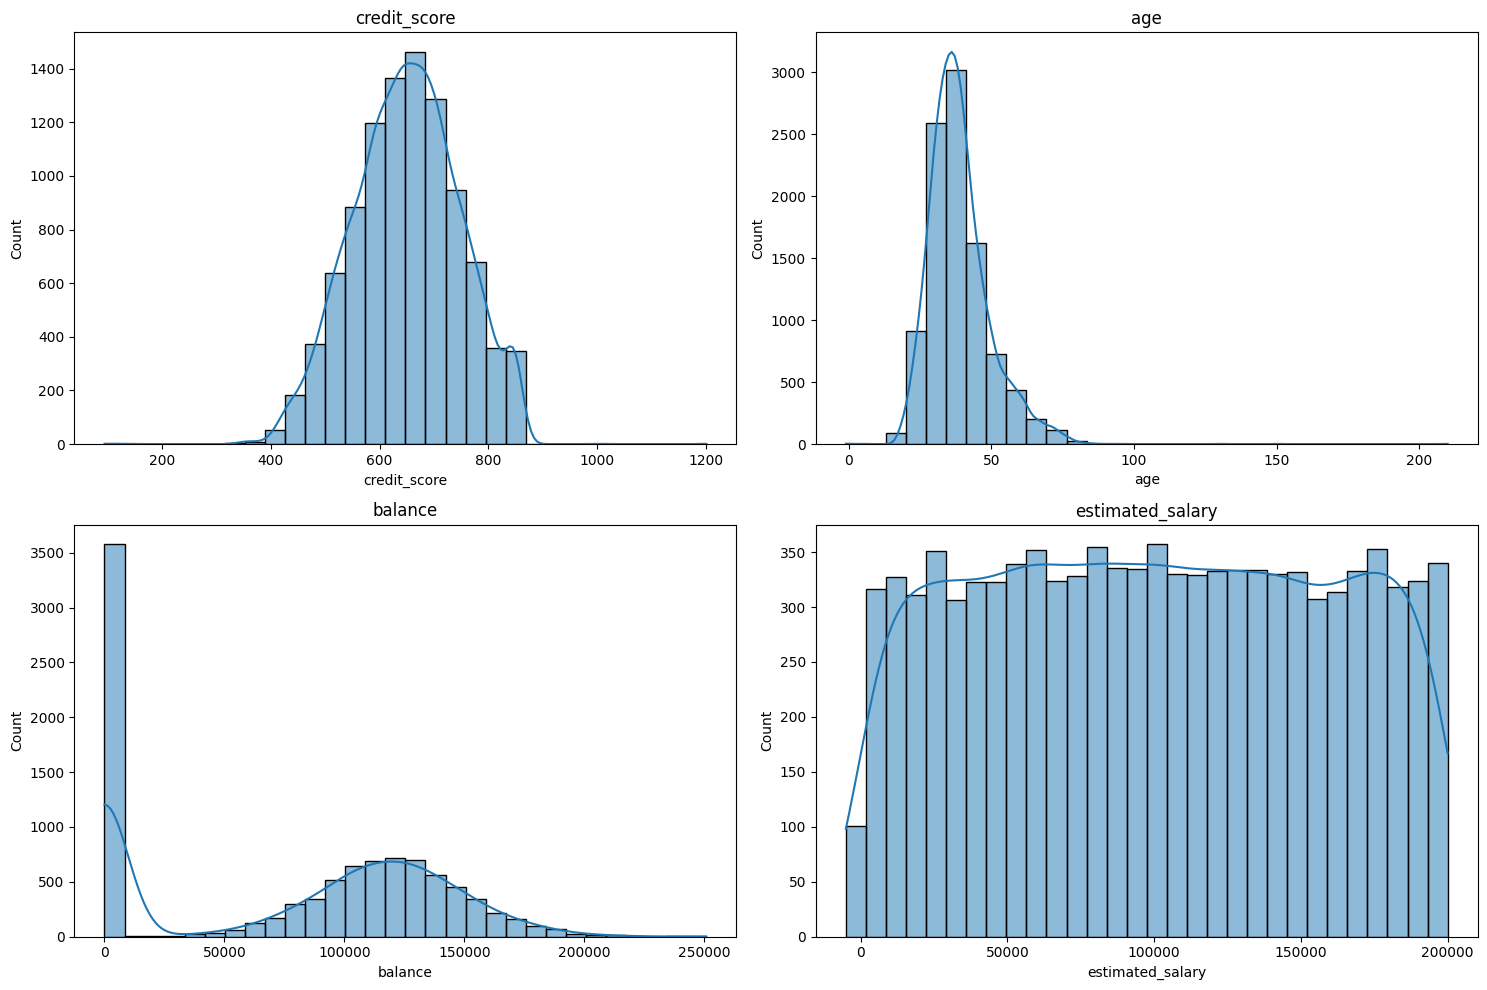

In [11]:
columnas = ['credit_score', 'age','balance','estimated_salary']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten() 
for ax, columna in zip(axes, columnas):
    sns.histplot(df[columna], bins=30, kde=True, ax=ax)
    ax.set_title(columna)
plt.tight_layout()
plt.show()

El puntaje de crédito tiene una distribución aproximadamente simétrica, centrada alrededor de 650. La edad es asimétrica con sesgo a la derecha: la mitad central de los clientes está entre 32 y 44 años y la cola incluye valores imposibles de hasta 210 años. El saldo es bimodal por la masa de cuentas en 0, y entre quienes tienen saldo los valores se concentran alrededor de 120.000. El salario estimado es aproximadamente uniforme, sin una zona de concentración.

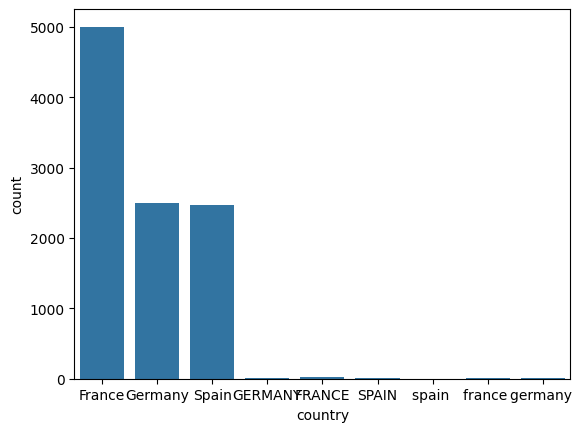

In [12]:
sns.countplot(x="country", data=df)
plt.show()

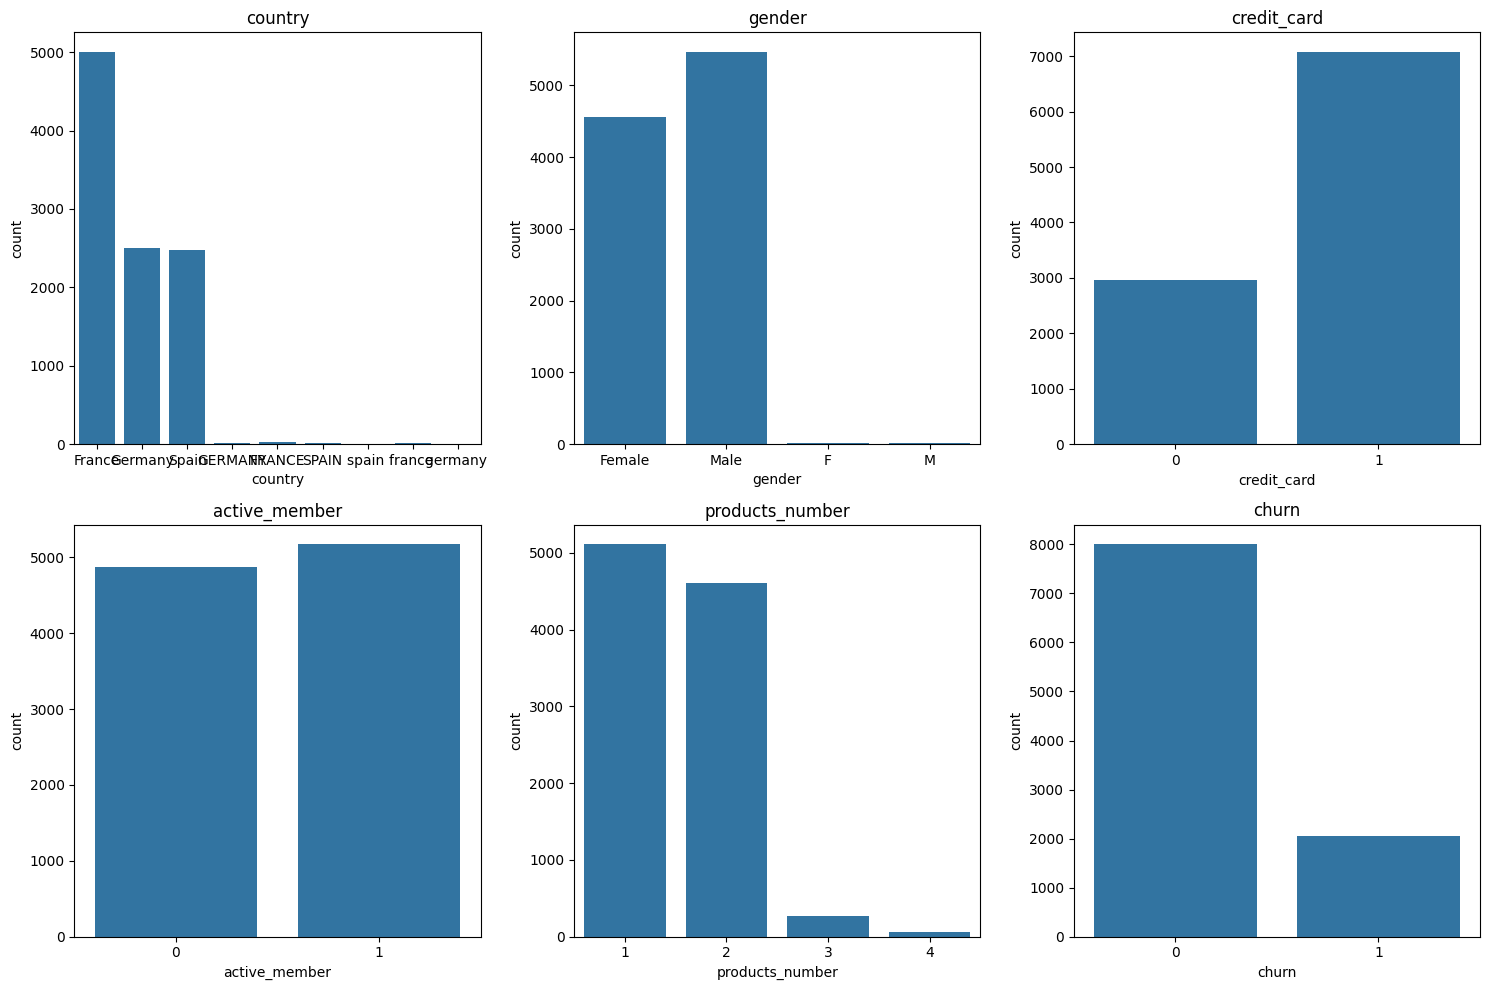

In [13]:
columnas = ['country', 'gender', 'credit_card', 'active_member', 'products_number', 'churn']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten() 

for ax, columna in zip(axes, columnas):
    sns.countplot(x=df[columna], ax=ax)
    ax.set_title(columna)

plt.tight_layout()
plt.show()

Francia concentra la mitad de los clientes (50,2%) y Alemania y España tienen volúmenes similares (25,1% y 24,7%); país y género tienen variantes de escritura que se corrigen en la sección de calidad. Hay algo más de hombres (54,6%) que mujeres. El 70,5% tiene tarjeta de crédito, los clientes activos e inactivos están casi parejos (51,5% frente a 48,5%) y el 96,8% tiene uno o dos productos. El 20,4% abandonó el banco: con este desbalance la exactitud no sirve para evaluar los modelos, porque uno que siempre prediga que el cliente se queda acertaría casi el 80% de las veces.

In [14]:
df["churn"].value_counts()                  # conteo de cada categoría
df["churn"].value_counts(normalize=True)    # proporción de cada categoría (suma 1)

churn
0    0.796416
1    0.203584
Name: proportion, dtype: float64

### Calidad de datos

In [15]:
df.duplicated().sum()            # cantidad de filas repetidas

np.int64(45)

In [16]:
df[df.duplicated(keep=False)]    # muestra todas las copias de cada fila repetida

,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
60,678.0,France,Male,40.0,1,0.00,2,1,1,187343.40,0
207,813.0,France,Female,62.0,10,64667.95,2,0,1,140454.14,0
407,756.0,Germany,Male,44.0,10,137452.09,1,1,0,189543.90,0
439,736.0,Spain,Male,32.0,7,0.00,1,0,1,79082.62,0
560,678.0,France,Male,40.0,1,0.00,2,1,1,187343.40,0
...,...,...,...,...,...,...,...,...,...,...,...
9547,724.0,France,Male,34.0,2,154485.74,2,0,0,78560.64,0
9706,615.0,Germany,Male,24.0,8,108528.07,2,0,0,179488.41,1
9709,678.0,France,Male,54.0,7,128914.97,1,0,0,191746.23,1
9757,610.0,France,Female,31.0,6,107784.65,1,1,1,141137.53,0


In [17]:
#df.duplicated().sum()                    # unicidad: filas repetidas
df.isna().sum()                          # completitud: nulos por columna

credit_score        250
country               0
gender                0
age                 300
tenure                0
balance             200
products_number       0
credit_card           0
active_member         0
estimated_salary    350
churn                 0
dtype: int64

In [18]:
df["country"].unique()

<ArrowStringArray>
[  'France',  'Germany',    'Spain',  'GERMANY',   'FRANCE',    'SPAIN',
   'spain ',  'france ', 'germany ']
Length: 9, dtype: str

In [19]:
df["gender"].unique()

<ArrowStringArray>
['Female', 'Male', 'F', 'M']
Length: 4, dtype: str

In [20]:
df.describe().loc[["min", "max"]].T  

,min,max
credit_score,95.0,1200.00
age,-1.0,210.00
tenure,-2.0,25.00
balance,0.0,250898.09
products_number,1.0,4.00
credit_card,0.0,1.00
active_member,0.0,1.00
estimated_salary,-5000.0,199992.48
churn,0.0,1.00


### Tratamiento

In [21]:
# Eliminacion de duplicados

df = df.drop_duplicates().reset_index(drop=True)
len(df) 

10000

quedan 10000 registros

In [22]:
# Age

(~df["age"].between(18, 100)).sum()                # fuera del rango [minimo, maximo]

np.int64(306)

suma 306 porque 300 son nulos, 3 están por debajo de 18 y 3 por encima de 100

In [23]:
df.loc[~df["age"].between(18, 100), "age"] = np.nan


para este caso en particular los valores fuera del rango se vuelven nulos, dado que el clipping cargaría los extremos, aunque solo sean 3 valores en el máximo y 3 en el mínimo, y no es fácil determinar si un 130 corresponde a un cliente de 100 o a uno de 30.

In [24]:
# Antiguedad en la empresa tenure
(~df["tenure"].between(0, 10)).sum()                # fuera del rango [minimo, maximo]

np.int64(3)

In [25]:
df["tenure"] = df["tenure"].clip(lower=0, upper=10)

para este caso identificamos 3 valores por fuera del rango, uno por debajo del límite inferior y dos por encima del superior. Se decide hacer un clipping con el fin de aproximarlos a los extremos, dado el número de registros y el rango de negocio.

In [26]:
# salario estimado
(df["estimated_salary"] < 0).sum()                                     # valores negativos

np.int64(3)

In [27]:
df["estimated_salary"] = df["estimated_salary"].clip(lower=0)

el salario estimado presenta en el boxplot unos datos por debajo de 0, lo cual no va con la lógica de negocio. Los valores mayores no presentan atípicos, por lo cual no se recomienda hacer tratamiento de máximos. Para esta variable se hace un clipping que acerca los valores negativos (3) a 0.

In [28]:
# Score de credito

(~df["credit_score"].between(300, 850)).sum()

np.int64(254)

In [29]:
df["credit_score"] = df["credit_score"].clip(lower=300, upper=850)

De los 254 registros señalados, 250 son nulos que se imputan más adelante y solo 4 están por fuera del rango del diccionario: 1200 y 999 por encima de 850, y 120 y 95 por debajo de 300. Se recortan al límite del rango, asumiendo que un valor por encima del máximo corresponde al mejor puntaje y uno por debajo del mínimo al peor. Al ser 4 de 10.000 registros, el supuesto no altera la distribución.

In [30]:
# Gender and Country


(~df["country"].isin(['France', 'Germany', 'Spain'])).sum()    # categorías no permitidas


np.int64(65)

In [31]:
df["country"] = df["country"].str.strip()       # sin espacios
df["country"] = df["country"].replace({"FRANCE": "France", "SPAIN": "Spain", "GERMANY": "Germany","france": "France", "spain": "Spain", "germany": "Germany"})  # unificar variantes

In [32]:
(~df["gender"].isin(['Female', 'Male'])).sum()    # géneros no permitidos

np.int64(30)

In [33]:
df["gender"] = df["gender"].str.strip()      # sin espacios
df["gender"] = df["gender"].replace({"M": "Male", "F": "Female"})  # unificar variantes

se corrigen las variables categóricas a la definición que tiene el diccionario de datos

## Tratamiento de outliers

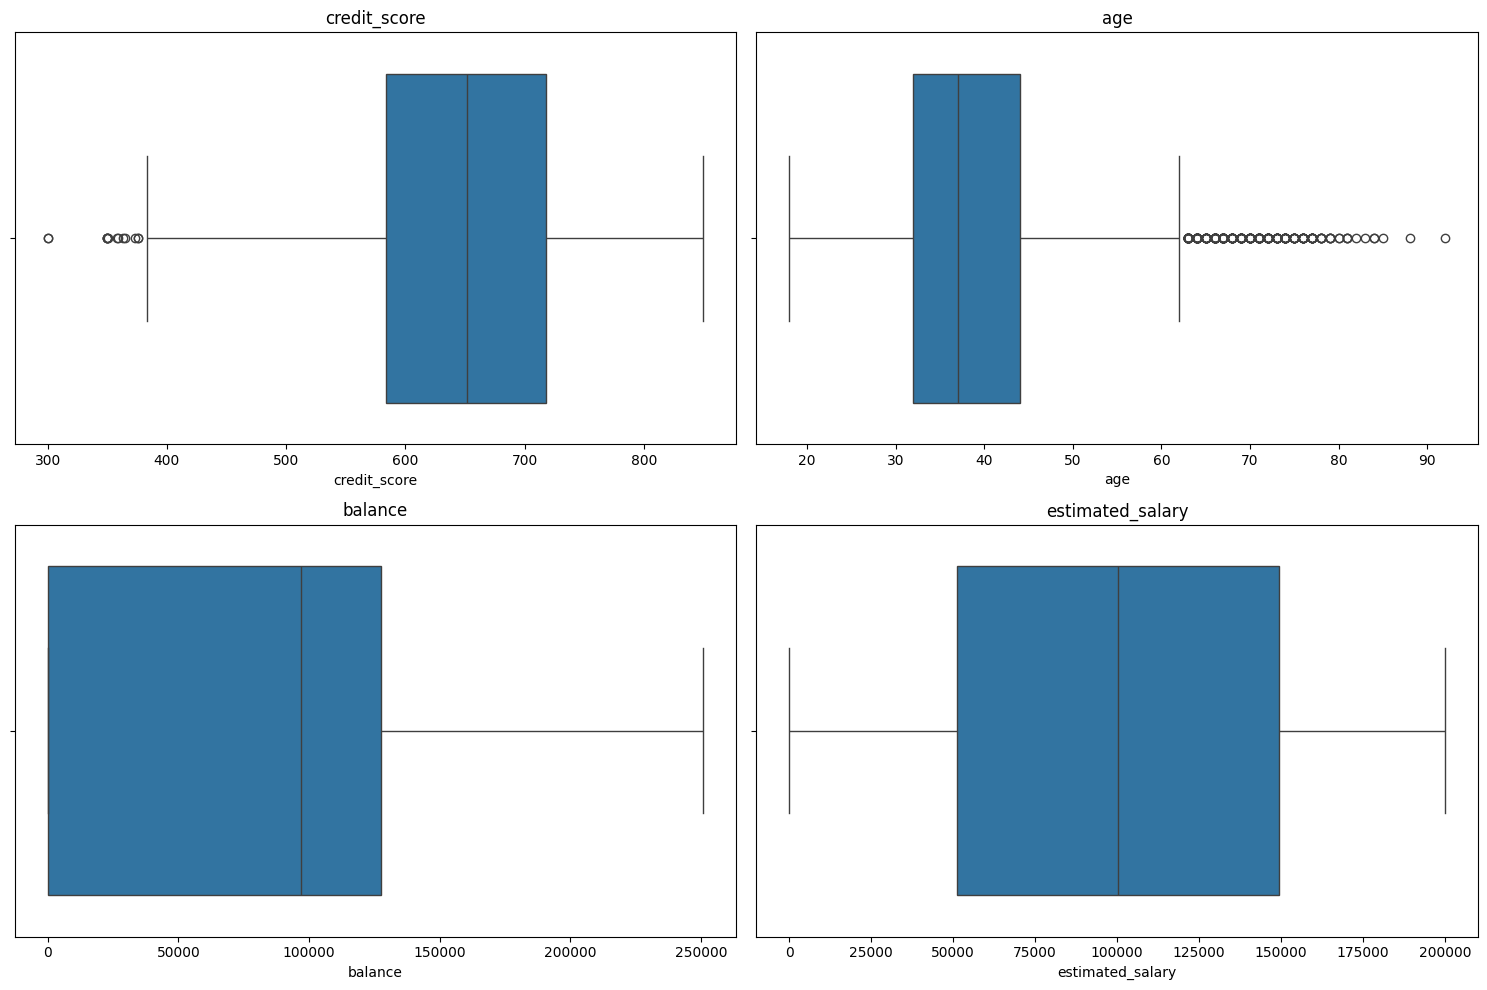

In [34]:
columnas = ['credit_score', 'age','balance','estimated_salary']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten() 

for ax, columna in zip(axes, columnas):
    sns.boxplot(x=df[columna], ax=ax)
    ax.set_title(columna)

plt.tight_layout()
plt.show()

## Cliping

In [35]:
# outliers


q1, q3 = df["credit_score"].quantile([0.25, 0.75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

((df["credit_score"] < inferior) | (df["credit_score"] > superior)).sum()

np.int64(14)

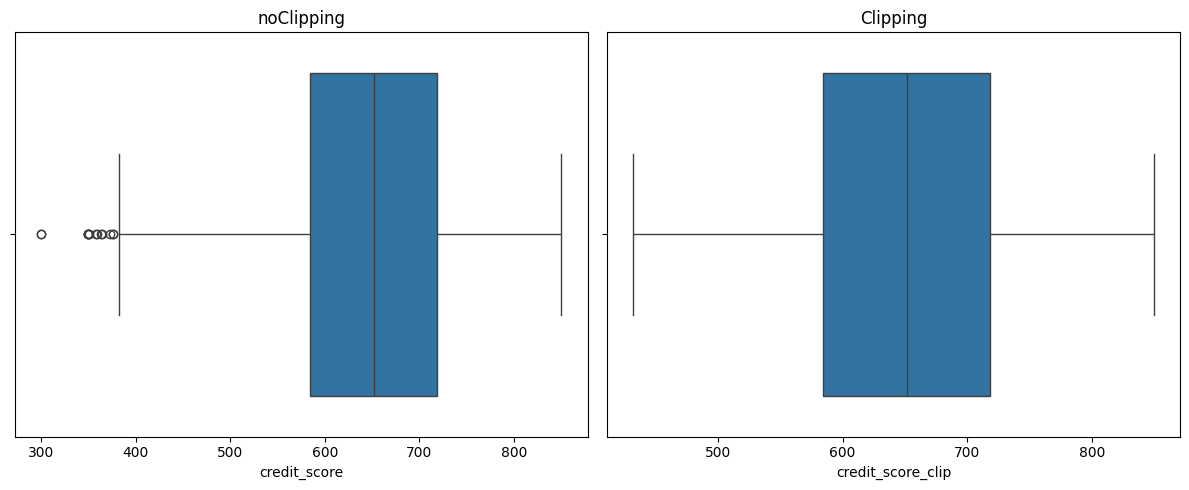

In [36]:
inferior, superior = df["credit_score"].quantile([0.01, 0.99])   # percentiles 1 y 99
df["credit_score_clip"] = df["credit_score"].clip(lower=inferior, upper=superior)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # Importante para crear el grafico en este caso 1 fila 2 columnas

# Gráfico 1: No clipping
sns.boxplot(x=df["credit_score"], ax=axes[0])
axes[0].set_title("noClipping")

# Gráfico 2: clippin
sns.boxplot(x=df["credit_score_clip"], ax=axes[1])
axes[1].set_title("Clipping")

plt.tight_layout()
plt.show()

In [37]:
estadisticas_score = df[['credit_score', 'credit_score_clip']].describe()

estadisticas_score

,credit_score,credit_score_clip
count,9750.000000,9750.000000
mean,650.593026,650.817231
std,96.768001,96.195754
min,300.000000,432.000000
25%,584.000000,584.000000
50%,652.000000,652.000000
75%,718.000000,718.000000
max,850.000000,850.000000


Age

In [38]:
q1, q3 = df["age"].quantile([0.25, 0.75])
iqr = q3 - q1
inferior, superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr

((df["age"] < inferior) | (df["age"] > superior)).sum()

np.int64(344)

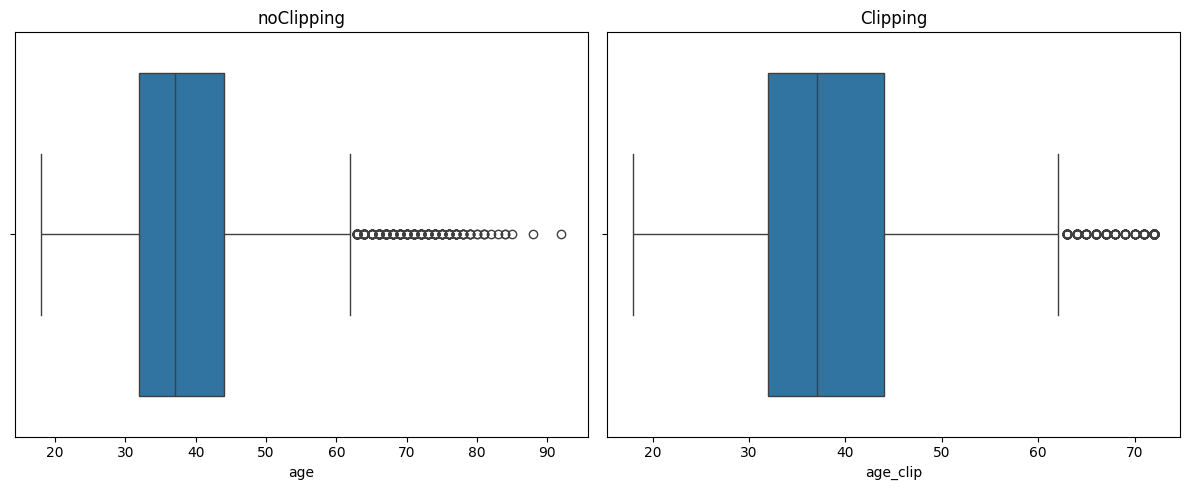

In [39]:
inferior, superior = df["age"].quantile([0.01, 0.99])
df["age_clip"] = df["age"].clip(upper=superior)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))  # Importante para crear el grafico en este caso 1 fila 2 columnas

# Gráfico 1: No clipping
sns.boxplot(x=df["age"], ax=axes[0])
axes[0].set_title("noClipping")

# Gráfico 2: clippin
sns.boxplot(x=df["age_clip"], ax=axes[1])
axes[1].set_title("Clipping")

plt.tight_layout()
plt.show()

In [40]:
# Generar la tabla de estadísticas descriptivas
estadisticas_age = df[['age', 'age_clip']].describe()

estadisticas_age

,age,age_clip
count,9694.000000,9694.000000
mean,38.917681,38.880648
std,10.471936,10.340978
min,18.000000,18.000000
25%,32.000000,32.000000
50%,37.000000,37.000000
75%,44.000000,44.000000
max,92.000000,72.000000


Las edades entre 73 y 92 años y los puntajes entre 350 y 431 corresponden a clientes reales dentro del rango válido, porque los errores ya se trataron con el rango del diccionario. El recorte por percentiles es entonces una decisión de modelado que limita la influencia de los extremos en los modelos sensibles a la escala, como la red neuronal, KNN y la regresión logística, que trabajan con datos estandarizados. Se fija un piso en el percentil 1 para el puntaje (432) y un techo en el percentil 99 para la edad (72), con lo que se modifica menos del 1% de cada variable sin cambiar la mediana ni los cuartiles. La decisión tiene un costo: los 14 clientes con puntaje menor a 383 abandonaron en un 85,7%, y al llevarlos a 432 junto con otros 82 clientes de puntaje bajo, ese grupo queda con una tasa de abandono de 36,5% y la señal se diluye.

## Indicadores de churn por variable

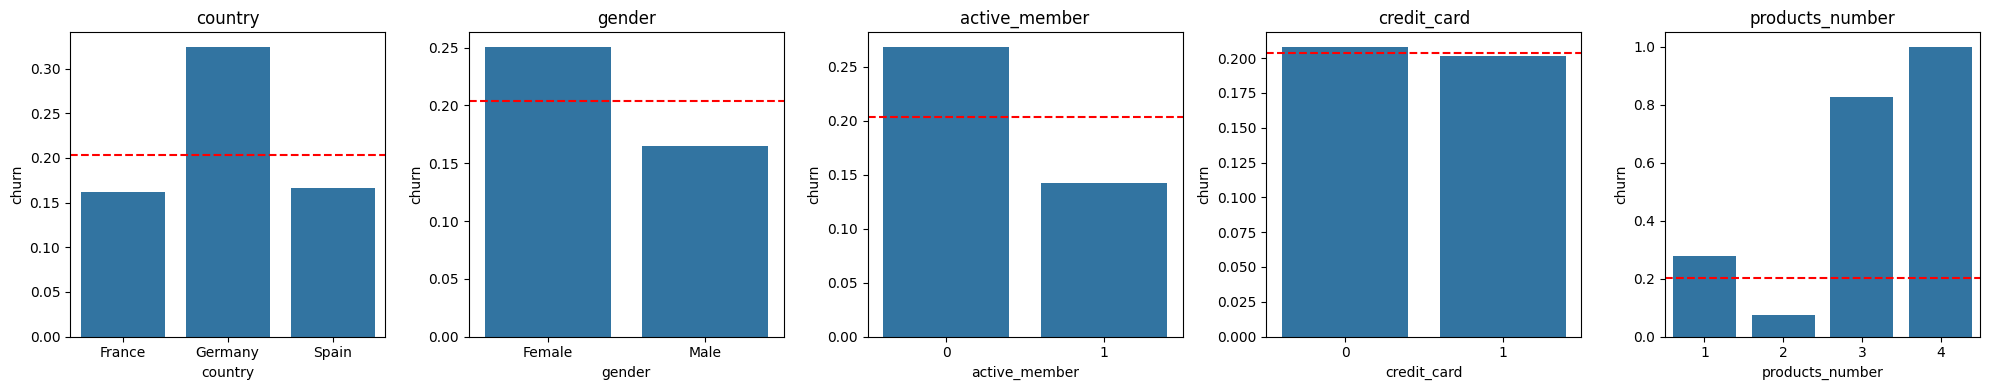

,mean,size
products_number,,
1,0.277144,5084
2,0.075817,4590
3,0.827068,266
4,1.000000,60


In [41]:
columnas = ["country", "gender", "active_member", "credit_card", "products_number"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, columna in zip(axes, columnas):
    sns.barplot(x=df[columna], y=df["churn"], ax=ax, errorbar=None)
    ax.axhline(df["churn"].mean(), color="red", linestyle="--")
    ax.set_title(columna)
plt.tight_layout()
plt.show()

df.groupby("products_number")["churn"].agg(["mean", "size"])

Alemania abandona al 32,4%, el doble que Francia (16,2%) y España (16,7%). Las mujeres abandonan más que los hombres (25,1% frente a 16,5%) y los clientes inactivos casi el doble que los activos (26,9% frente a 14,3%). El número de productos es la variable con el patrón más marcado y no es lineal: con 2 productos el abandono baja a 7,6%, pero con 3 sube a 82,7% y con 4 llega al 100%, aunque son grupos pequeños de 266 y 60 clientes. Tener tarjeta de crédito no cambia el abandono (20,8% frente a 20,2%). Para la campaña, los focos naturales son Alemania, los clientes inactivos y quienes tienen un solo producto o tres o más.

In [42]:
df_P4 = df.copy()

 guia -- Practica 4 -- Actividad 1

## Encoding

In [43]:
#One-HOT

df_P4 = pd.get_dummies(df_P4, columns=["country", "gender"], drop_first=True, dtype=int)

## Caracteristicas derivadas

Original y ampliado

In [44]:
cols_originales = [
    "credit_score_clip", "age_clip", "tenure", "balance", "products_number",
    "credit_card", "active_member", "estimated_salary",
    "country_Germany", "country_Spain", "gender_Male"
]
cols_derivadas = ["balance_cero", "balance_salario", "productos_1", "productos_3mas", "edad_activo"]
cols_ampliadas = cols_originales + cols_derivadas

X_orig = df_P4[cols_originales]
y = df_P4["churn"]

## Nulos

In [45]:
#df.isna().sum()            # cantidad de nulos por columna
df.isna().mean() * 100     # porcentaje de nulos por columna

credit_score         2.50
country              0.00
gender               0.00
age                  3.06
tenure               0.00
balance              2.00
products_number      0.00
credit_card          0.00
active_member        0.00
estimated_salary     3.50
churn                0.00
credit_score_clip    2.50
age_clip             3.06
dtype: float64

# Entrenamiento de modelos de Machine Learning

actividad soportada en la practica dos
(2)

## Division (60/20/20)

Los valores faltantes se imputan con la mediana y no con la media, porque la edad y el saldo tienen distribuciones sesgadas y la mediana representa mejor al cliente típico sin dejarse arrastrar por los extremos. La mediana se calcula únicamente con el conjunto de entrenamiento y luego se aplica igual a validación y prueba, porque en operación el banco solo conoce a los clientes con los que construyó el modelo y no puede usar información de los clientes que todavía va a evaluar. El orden también importa: primero se completan las variables originales y después se calculan las variables derivadas a partir de esos datos ya completos. Si se hiciera al revés, cada derivada recibiría una mediana propia sin relación con el cliente. Por ejemplo, a un cliente inactivo sin edad registrada se le asignaría una edad_activo de 24, cuando por definición esa variable debe ser 0 para cualquier cliente inactivo.

In [46]:
X_temp_orig, X_test_orig, y_temp, y_test = train_test_split(
    X_orig, y, test_size=0.20, random_state=42, stratify=y)

X_train_orig, X_val_orig, y_train, y_val = train_test_split(
    X_temp_orig, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

mediana_orig = X_train_orig.median()
X_train_orig_imp = X_train_orig.fillna(mediana_orig)
X_val_orig_imp = X_val_orig.fillna(mediana_orig)
X_test_orig_imp = X_test_orig.fillna(mediana_orig)

tope_balance_salario = (X_train_orig_imp["balance"] / (X_train_orig_imp["estimated_salary"] + 1)).quantile(0.99)

X_train_amp_imp, X_val_amp_imp, X_test_amp_imp = [
    X.assign(
        balance_cero=(X["balance"] == 0).astype(int),
        balance_salario=(X["balance"] / (X["estimated_salary"] + 1)).clip(upper=tope_balance_salario),
        productos_1=(X["products_number"] == 1).astype(int),
        productos_3mas=(X["products_number"] >= 3).astype(int),
        edad_activo=X["age_clip"] * X["active_member"])
    for X in (X_train_orig_imp, X_val_orig_imp, X_test_orig_imp)]

scaler_orig = StandardScaler()
X_train_orig_esc = pd.DataFrame(scaler_orig.fit_transform(X_train_orig_imp), columns=cols_originales, index=X_train_orig.index)
X_val_orig_esc = pd.DataFrame(scaler_orig.transform(X_val_orig_imp), columns=cols_originales, index=X_val_orig.index)
X_test_orig_esc = pd.DataFrame(scaler_orig.transform(X_test_orig_imp), columns=cols_originales, index=X_test_orig.index)

scaler_amp = StandardScaler()
X_train_amp_esc = pd.DataFrame(scaler_amp.fit_transform(X_train_amp_imp), columns=cols_ampliadas, index=X_train_orig.index)
X_val_amp_esc = pd.DataFrame(scaler_amp.transform(X_val_amp_imp), columns=cols_ampliadas, index=X_val_orig.index)
X_test_amp_esc = pd.DataFrame(scaler_amp.transform(X_test_amp_imp), columns=cols_ampliadas, index=X_test_orig.index)

La razón entre saldo y salario tiene una cola muy larga, porque algunos clientes reportan salarios cercanos a cero y cualquier saldo dividido por un salario tan bajo produce un valor enorme. En entrenamiento su mediana es 0,74, pero alcanza valores de miles y en la base completa supera los 167.000. La estandarización usa la media y la desviación estándar, que se dejan arrastrar por estos pocos casos: la desviación estándar en entrenamiento sube a 128,4 y el 96,9% de los clientes queda a menos de 0,05 desviaciones estándar de la media, es decir, para la red neuronal, la regresión logística y KNN casi todos los clientes se ven iguales y la variable deja de aportar. Por eso se le aplica un techo en el percentil 99 calculado con entrenamiento (35,44), el mismo criterio que ya se usó para la edad y el puntaje de crédito. Con el techo, la desviación estándar baja a 4,71 y la variable vuelve a distinguir a un cliente cuyo saldo equivale a varias veces su salario de uno que casi no tiene saldo. Los árboles de decisión no dependen de la escala, pero los demás modelos y el ensamble sí.

Los cuatro modelos se entrenan y evalúan sobre los mismos clientes, para que las diferencias en las métricas se deban al modelo o a las variables y no a qué clientes cayeron en cada conjunto. El entrenamiento (60%) ajusta los modelos y los parámetros de preparación (medianas, escalado y techo de balance_salario). La validación (20%) sirve para comparar modelos y elegir el umbral de la campaña. La prueba (20%) mide el resultado final con clientes que no influyeron en ninguna decisión.

## Configuracion 1

In [47]:
# =========================================================
# 1. FUNCIÓN PARA CONSTRUIR LA ARQUITECTURA DE LA RED B
# =========================================================

def construir_red_b(input_dim):

    keras.utils.set_random_seed(42)  # Reproducibilidad

    model = keras.Sequential([
        keras.Input(shape=(input_dim,)),
        layers.Dense(16, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(8, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


# =========================================================
# MODELO 1A: CONJUNTO ORIGINAL (11 VARIABLES)
# =========================================================

modelo_1A = construir_red_b(
    input_dim=X_train_orig_esc.shape[1]
)

historia_1A = modelo_1A.fit(
    X_train_orig_esc,
    y_train,
    validation_data=(X_val_orig_esc, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)


# =========================================================
# MODELO 1B: CONJUNTO AMPLIADO (16 VARIABLES)
# =========================================================

modelo_1B = construir_red_b(
    input_dim=X_train_amp_esc.shape[1]
)

historia_1B = modelo_1B.fit(
    X_train_amp_esc,
    y_train,
    validation_data=(X_val_amp_esc, y_val),
    epochs=100,
    batch_size=32,
    verbose=0
)


# =========================================================
# COMPARACIÓN DE MODELOS EN VALIDACIÓN
# =========================================================

# Predicciones del Modelo 1A
y_prob_1A = modelo_1A.predict(
    X_val_orig_esc,
    verbose=0
).ravel()

y_pred_1A = (y_prob_1A >= 0.5).astype(int)


# Predicciones del Modelo 1B
y_prob_1B = modelo_1B.predict(
    X_val_amp_esc,
    verbose=0
).ravel()

y_pred_1B = (y_prob_1B >= 0.5).astype(int)


# =========================================================
# TABLA COMPARATIVA DE RESULTADOS
# =========================================================

res_config1 = pd.DataFrame([

    {
        "Modelo": "Modelo 1A (Original)",
        "Variables": X_train_orig_esc.shape[1],
        "Exactitud": accuracy_score(y_val, y_pred_1A),
        "Precisión": precision_score(y_val, y_pred_1A),
        "Recall": recall_score(y_val, y_pred_1A),
        "F1-score": f1_score(y_val, y_pred_1A),
        "AUC": roc_auc_score(y_val, y_prob_1A)
    },

    {
        "Modelo": "Modelo 1B (Ampliado)",
        "Variables": X_train_amp_esc.shape[1],
        "Exactitud": accuracy_score(y_val, y_pred_1B),
        "Precisión": precision_score(y_val, y_pred_1B),
        "Recall": recall_score(y_val, y_pred_1B),
        "F1-score": f1_score(y_val, y_pred_1B),
        "AUC": roc_auc_score(y_val, y_prob_1B)
    }

])


# =========================================================
# MOSTRAR RESULTADOS
# =========================================================

print("\n===== COMPARACIÓN DE LA CONFIGURACIÓN 1 =====\n")

print(res_config1.round(4).to_string(index=False))


===== COMPARACIÓN DE LA CONFIGURACIÓN 1 =====

              Modelo  Variables  Exactitud  Precisión  Recall  F1-score    AUC
Modelo 1A (Original)         11     0.8595     0.7838  0.4275    0.5533 0.8487
Modelo 1B (Ampliado)         16     0.8580     0.7943  0.4079    0.5390 0.8472


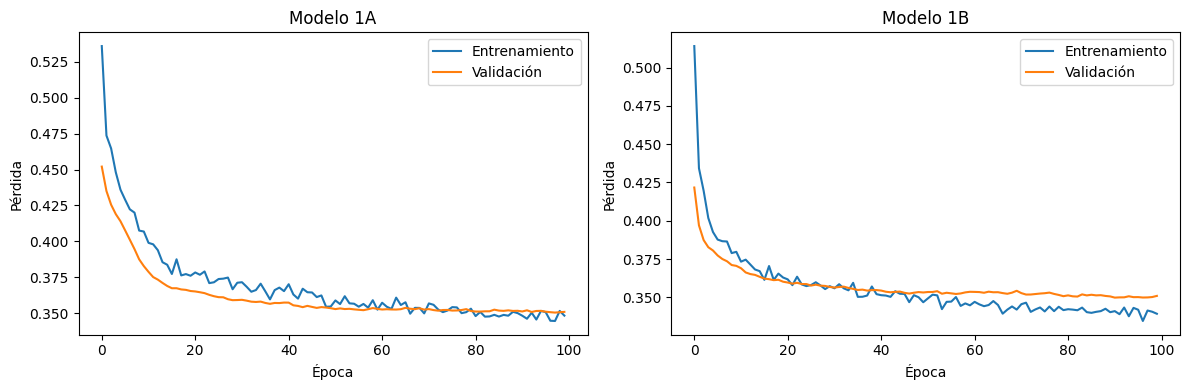

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, historia) in zip(axes, [("Modelo 1A", historia_1A), ("Modelo 1B", historia_1B)]):
    ax.plot(historia.history["loss"], label="Entrenamiento")
    ax.plot(historia.history["val_loss"], label="Validación")
    ax.set_title(nombre)
    ax.set_xlabel("Época")
    ax.set_ylabel("Pérdida")
    ax.legend()
plt.tight_layout()
plt.show()

Las curvas de pérdida respaldan el uso de 100 épocas. En la red 1A la pérdida de validación cae rápido al inicio (0,3654 en la época 20), sigue bajando despacio hasta 0,3534 en la época 50 y termina en 0,3509, muy cerca de su mínimo (0,3504 en la época 98). La pérdida de entrenamiento termina en 0,3483, casi igual a la de validación, así que la red no está memorizando a los clientes con los que aprende. La mayor parte de la mejora ocurre antes de la época 50 y después la ganancia es marginal, por lo que entrenar más no aportaría y las 100 épocas no generan sobreajuste. En la red 1B la validación también se estabiliza alrededor de 0,351, pero la pérdida de entrenamiento sigue bajando hasta 0,3393: la red ampliada se ajusta cada vez más a los clientes de entrenamiento sin ganar nada en validación, lo que es coherente con que las variables derivadas no mejoren su desempeño.

El Modelo 1B agrega a la red las cinco variables derivadas, con lo que pasa de 11 a 16 variables de entrada y de 337 a 417 parámetros entrenables. En validación el resultado prácticamente no cambia. El F1 baja de 0,5533 a 0,5390, una diferencia de 1,43 puntos que queda por debajo del umbral de relevancia práctica de 2 puntos usado en el resto del análisis. La precisión sube levemente (de 0,7838 a 0,7943) y el recall baja (de 0,4275 a 0,4079), es decir, la red ampliada marca a menos clientes y deja escapar a algunos más de los que sí se iban. Para el banco esto es un intercambio menor: cada contacto se paga y la oferta solo retiene al 30% de quienes iban a irse, así que una precisión un poco mayor abarata la campaña, pero cada abandono no detectado es un cliente que se pierde sin oportunidad de retenerlo. Con diferencias de este tamaño ninguna de las dos lecturas cambia la decisión. La exactitud y el AUC son casi iguales (0,8595 frente a 0,8580 y 0,8487 frente a 0,8472). La lectura es que las variables derivadas no le aportan a la red información que no pueda aprender por sí misma de las variables originales, como el efecto no lineal del número de productos, así que se prefiere el modelo más simple, 1A.

## Configuracion 2

In [49]:
busquedas = {
    "Árbol": GridSearchCV(
        DecisionTreeClassifier(class_weight="balanced", random_state=42),
        {"max_depth": [3, 5, 7, 9, 12], "min_samples_leaf": [10, 20, 50, 100]},
        cv=5, scoring="f1", n_jobs=-1),
    "Regresión logística": GridSearchCV(
        LogisticRegression(max_iter=1000, random_state=42),
        {"C": [0.01, 0.1, 1, 10]},
        cv=5, scoring="f1", n_jobs=-1),
    "KNN": GridSearchCV(
        KNeighborsClassifier(),
        {"n_neighbors": [3, 5, 11, 21, 41], "weights": ["uniform", "distance"]},
        cv=5, scoring="f1", n_jobs=-1)}

for nombre, busqueda in busquedas.items():
    busqueda.fit(X_train_amp_esc, y_train)
    print(nombre)
    display(pd.DataFrame(busqueda.cv_results_)
            .sort_values("mean_test_score", ascending=False)[["params", "mean_test_score", "std_test_score"]]
            .head(4).round(4))

# Modelo 2A: árbol de decisión (Actividad 3)
modelo_2A = DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, class_weight="balanced", random_state=42)
modelo_2A.fit(X_train_amp_esc, y_train)

# Modelo 2B: ensamble por votación (Actividad 4)
modelo_2B = VotingClassifier(estimators=[
    ("logistica", LogisticRegression(C=1, max_iter=1000, random_state=42)),
    ("arbol", DecisionTreeClassifier(max_depth=7, min_samples_leaf=20, class_weight="balanced", random_state=42)),
    ("knn", busquedas["KNN"].best_estimator_)], voting="soft")
modelo_2B.fit(X_train_amp_esc, y_train)

# =========================================================
# 3. PREDICCIONES Y EVALUACIÓN EN VALIDACIÓN
# =========================================================
y_pred_2A = modelo_2A.predict(X_val_amp_esc)
y_prob_2A = modelo_2A.predict_proba(X_val_amp_esc)[:, 1]

y_pred_2B = modelo_2B.predict(X_val_amp_esc)
y_prob_2B = modelo_2B.predict_proba(X_val_amp_esc)[:, 1]

# 4. Tabla comparativa
res_config2 = pd.DataFrame([
    {
        "Modelo": "Modelo 2A (Árbol Optimizado)",
        "Exactitud": accuracy_score(y_val, y_pred_2A),
        "Precisión": precision_score(y_val, y_pred_2A),
        "Recall": recall_score(y_val, y_pred_2A),
        "F1-score": f1_score(y_val, y_pred_2A),
        "AUC": roc_auc_score(y_val, y_prob_2A)
    },
    {
        "Modelo": "Modelo 2B (Ensamble Votación)",
        "Exactitud": accuracy_score(y_val, y_pred_2B),
        "Precisión": precision_score(y_val, y_pred_2B),
        "Recall": recall_score(y_val, y_pred_2B),
        "F1-score": f1_score(y_val, y_pred_2B),
        "AUC": roc_auc_score(y_val, y_prob_2B)
    }
])

print("--- RESULTADOS CONFIGURACIÓN 2 (CONJUNTO AMPLIADO) ---")
display(res_config2.round(4))

Árbol


,params,mean_test_score,std_test_score
8,"{'max_depth': 7, 'min_samples_leaf': 10}",0.5843,0.0091
9,"{'max_depth': 7, 'min_samples_leaf': 20}",0.5836,0.0121
13,"{'max_depth': 9, 'min_samples_leaf': 20}",0.5767,0.0121
17,"{'max_depth': 12, 'min_samples_leaf': 20}",0.5700,0.0129


Regresión logística


,params,mean_test_score,std_test_score
3,{'C': 10},0.5492,0.0347
2,{'C': 1},0.5475,0.0352
1,{'C': 0.1},0.5354,0.0310
0,{'C': 0.01},0.4831,0.0428


KNN


,params,mean_test_score,std_test_score
2,"{'n_neighbors': 5, 'weights': 'uniform'}",0.5130,0.0374
3,"{'n_neighbors': 5, 'weights': 'distance'}",0.5057,0.0371
5,"{'n_neighbors': 11, 'weights': 'distance'}",0.5024,0.0335
1,"{'n_neighbors': 3, 'weights': 'distance'}",0.5019,0.0238


--- RESULTADOS CONFIGURACIÓN 2 (CONJUNTO AMPLIADO) ---


,Modelo,Exactitud,Precisión,Recall,F1-score,AUC
0,Modelo 2A (Árbol Optimizado),0.7640,0.4480,0.6880,0.5426,0.8229
1,Modelo 2B (Ensamble Votación),0.8515,0.6797,0.5111,0.5835,0.8307


Los hiperparámetros de los tres modelos se buscaron con validación cruzada de 5 particiones sobre el conjunto de entrenamiento, optimizando el F1. Se usa el F1 porque en esta etapa todavía no se ha fijado el costo por contacto de la campaña, y es un criterio neutral que no favorece ni la precisión ni el recall; el ajuste a la economía de la campaña se hace después, moviendo el umbral de decisión. En el árbol, la mejor combinación fue profundidad 7 con mínimo 10 clientes por hoja (F1 de 0,5843), prácticamente igual a profundidad 7 con 20 por hoja (0,5836). En la regresión logística, C igual a 10 (0,5492) quedó casi empatado con C igual a 1 (0,5475). En ambos casos la diferencia es mucho menor que la variación entre particiones de la validación cruzada. Cuando dos opciones quedan a menos de 0,01 de F1, se elige la más conservadora, porque una hoja con más clientes y una regularización más fuerte generalizan mejor a clientes nuevos; por eso se usan 20 clientes por hoja y C igual a 1. En KNN, la mejor opción fue 5 vecinos con pesos uniformes (0,5130), y esa es la que entra al ensamble.

El Modelo 2A es un árbol de decisión con profundidad máxima de 7 niveles, mínimo 20 clientes por hoja y pesos balanceados para darle más importancia a la clase minoritaria. El Modelo 2B combina una regresión logística, un árbol con los mismos hiperparámetros y un KNN de 5 vecinos mediante votación suave, es decir, promediando las probabilidades de los tres. El ensamble gana con claridad: su F1 es 0,5835 frente a 0,5426 del árbol, 4,09 puntos más, y su AUC es 0,8307 frente a 0,8229. Los dos modelos se equivocan de forma distinta. El árbol detecta más clientes que se van (recall de 0,6880 frente a 0,5111), pero a costa de muchas falsas alarmas: solo el 44,8% de los clientes que marca realmente abandona, mientras que en el ensamble esa proporción sube a 68%. En este negocio esa diferencia pesa, porque se paga por cada cliente contactado, abandone o no, y la oferta solo retiene al 30% de los que sí se iban; con el árbol, más de la mitad de los contactos de la campaña se gastaría en clientes que no pensaban irse. El recall más alto del árbol solo compensaría si el costo por contacto fuera muy bajo frente al valor del cliente, y ese balance se evalúa con cifras en la sección de generación de valor. La diferencia de exactitud (76,4% frente a 85,15%) no sirve para esta comparación, porque el árbol balanceado sacrifica exactitud a propósito para encontrar más casos de abandono y porque en una base donde 8 de cada 10 clientes se quedan, acertar mucho no significa detectar a los que se van.

## Comparacion

In [50]:
# Consolidación de los 4 modelos evaluados en validación
modelos_evaluacion = [
    ("Modelo 1A (Red Neuronal - Original)", y_pred_1A, "Configuración 1"),
    ("Modelo 1B (Red Neuronal - Ampliado)", y_pred_1B, "Configuración 1"),
    ("Modelo 2A (Árbol Optimizado - Ampliado)", y_pred_2A, "Configuración 2"),
    ("Modelo 2B (Ensamble Votación - Ampliado)", y_pred_2B, "Configuración 2"),
]

res_punto6 = []
for nombre, pred, config in modelos_evaluacion:
    res_punto6.append({
        "Configuración": config,
        "Modelo": nombre,
        "Precisión": precision_score(y_val, pred),
        "Recall": recall_score(y_val, pred),
        "F1-score": f1_score(y_val, pred)
    })

df_punto6 = pd.DataFrame(res_punto6)
print("--- COMPARACIÓN EN VALIDACIÓN (4 MODELOS) ---")
display(df_punto6.round(4))

--- COMPARACIÓN EN VALIDACIÓN (4 MODELOS) ---


,Configuración,Modelo,Precisión,Recall,F1-score
0,Configuración 1,Modelo 1A (Red Neuronal - Original),0.7838,0.4275,0.5533
1,Configuración 1,Modelo 1B (Red Neuronal - Ampliado),0.7943,0.4079,0.5390
2,Configuración 2,Modelo 2A (Árbol Optimizado - Ampliado),0.4480,0.6880,0.5426
3,Configuración 2,Modelo 2B (Ensamble Votación - Ampliado),0.6797,0.5111,0.5835


Con el umbral estándar de 0,5, el mejor modelo en validación es el ensamble 2B, con un F1 de 0,5835, seguido de la red 1A (0,5533), el árbol 2A (0,5426) y la red ampliada 1B (0,5390). El cambio de tipo de modelo pesa más que el cambio de variables: pasar del árbol al ensamble mejora el F1 en 4,09 puntos, mientras que agregar las variables derivadas a la red lo mueve apenas 1,43 puntos. Cada modelo tiene una fortaleza distinta. La red ampliada es la más precisa (de cada 100 clientes que marca, 79 sí se iban), el árbol es el que más casos detecta (69 de cada 100 que se van) y la red original es la que mejor ordena a los clientes por riesgo, con el AUC más alto (0,8487). Para el banco, la exactitud dice poco y el F1 es solo un resumen mientras no se fija el costo por contacto. La decisión final se toma con el valor esperado de la campaña, donde la precisión define si cada contacto se paga y el recall define cuánto valor se recupera, y donde el umbral de 0,5 se puede mover según el costo; por eso un modelo que ordena bien a los clientes, como 1A, puede volverse más rentable que uno con mejor F1. Estas diferencias vienen de una sola partición de validación, por lo que en la siguiente sección se comprueba si son estadísticamente significativas.

# Análisis Cuantitativo de Resultados
(3)

## Métricas en prueba y su valor para el banco

In [51]:
EFECTIVIDAD = 0.30

probabilidades_test = {
    "Modelo 1A (Red Original)": modelo_1A.predict(X_test_orig_esc, verbose=0).ravel(),
    "Modelo 1B (Red Ampliada)": modelo_1B.predict(X_test_amp_esc, verbose=0).ravel(),
    "Modelo 2A (Árbol)": modelo_2A.predict_proba(X_test_amp_esc)[:, 1],
    "Modelo 2B (Ensamble)": modelo_2B.predict_proba(X_test_amp_esc)[:, 1]}

filas = []
for nombre, prob in probabilidades_test.items():
    pred = (prob >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append({"Modelo": nombre, "Contactados": tp + fp, "VP": tp, "FP": fp, "FN": fn,
                  "Precisión": tp / (tp + fp), "Recall": tp / (tp + fn),
                  "Exactitud": (tp + tn) / len(y_test), "AUC": roc_auc_score(y_test, prob),
                  "Retenidos esperados": EFECTIVIDAD * tp,
                  "Costo máx. por contacto (% del valor)": EFECTIVIDAD * tp / (tp + fp) * 100})
pd.DataFrame(filas).round(4)

,Modelo,Contactados,VP,FP,FN,Precisión,Recall,Exactitud,AUC,Retenidos esperados,Costo máx. por contacto (% del valor)
0,Modelo 1A (Red Original),210,165,45,242,0.7857,0.4054,0.8565,0.8556,49.5,23.5714
1,Modelo 1B (Red Ampliada),216,159,57,248,0.7361,0.3907,0.8475,0.8443,47.7,22.0833
2,Modelo 2A (Árbol),652,300,352,107,0.4601,0.7371,0.7705,0.8298,90.0,13.8037
3,Modelo 2B (Ensamble),302,210,92,197,0.6954,0.5160,0.8555,0.8396,63.0,20.8609


En el conjunto de prueba, con 2.000 clientes de los cuales 407 abandonan, cada métrica responde una pregunta distinta para el banco. La precisión dice qué proporción de los clientes contactados realmente se iba a ir, y como la campaña se paga por cada contacto, es la que define si el dinero de la campaña se aprovecha. El recall dice qué proporción de los clientes que se van alcanza a ser contactada, y define cuánto valor se puede recuperar. El AUC mide qué tan bien el modelo ordena a los clientes de mayor a menor riesgo, que es lo que importa si el banco quiere priorizar una lista. La exactitud aporta poco, porque un modelo que dijera que nadie se va acertaría en casi el 80% de los casos. Con el umbral de 0,5, el árbol 2A contacta a 652 clientes para alcanzar a 300 de los que se iban, el ensamble 2B contacta a 302 para alcanzar a 210 y la red 1A contacta a 210 para alcanzar a 165. Como la oferta solo convence al 30%, una campaña con el ensamble retendría en promedio a 63 clientes y una con el árbol a 90, pero el árbol necesita 350 contactos adicionales para retener 27 clientes más, lo que solo conviene si el costo de cada contacto es menor al 7,7% del valor de un cliente retenido. La última columna resume este razonamiento para cada modelo: es el costo máximo por contacto, como porcentaje del valor del cliente, con el que la campaña todavía no pierde dinero. La red 1A tolera hasta 23,6%, el ensamble 20,9% y el árbol solo 13,8%.

## Bootstraping

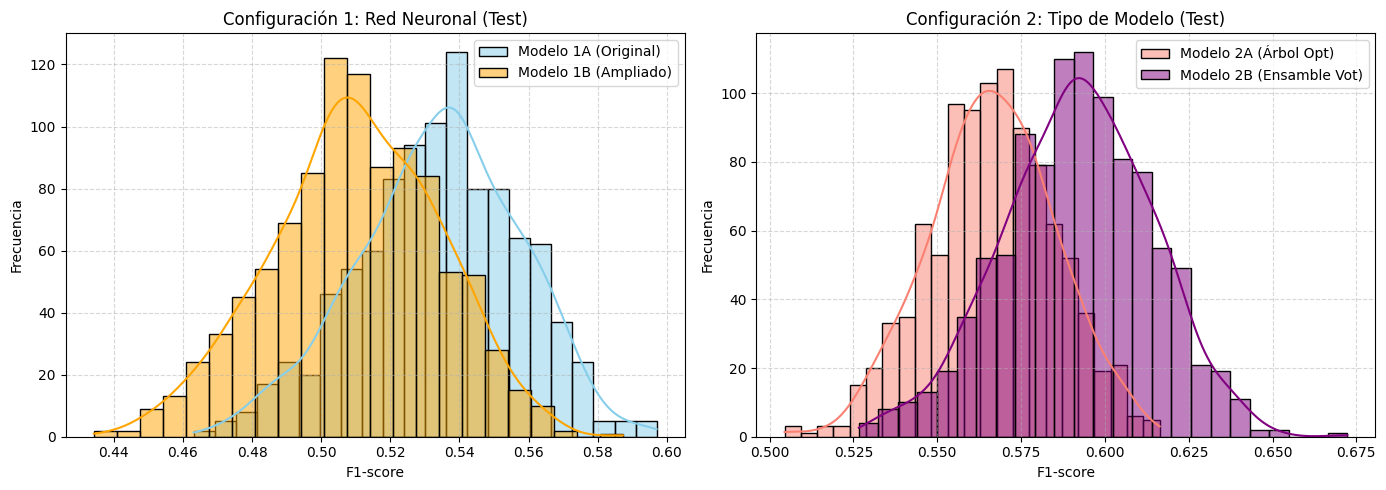

--- INTERVALOS DE CONFIANZA DEL 95% (TEST) ---
Modelo 1A (Red Original):  F1 Medio = 0.5340 | IC 95% = [0.4856, 0.5753]
Modelo 1B (Red Ampliada):  F1 Medio = 0.5098 | IC 95% = [0.4605, 0.5550]
Modelo 2A (Árbol Opt):    F1 Medio = 0.5664 | IC 95% = [0.5289, 0.6036]
Modelo 2B (Ensamble Vot): F1 Medio = 0.5918 | IC 95% = [0.5463, 0.6338]


In [52]:
# 1. Obtener predicciones fijas sobre el conjunto de PRUEBA (X_test / y_test)
# Configuración 1 (Red Neuronal)
y_prob_1A_test = modelo_1A.predict(X_test_orig_esc, verbose=0).ravel()
y_pred_1A_test = (y_prob_1A_test >= 0.5).astype(int)

y_prob_1B_test = modelo_1B.predict(X_test_amp_esc, verbose=0).ravel()
y_pred_1B_test = (y_prob_1B_test >= 0.5).astype(int)

# Configuración 2 (Árbol Optimizado y Ensamble Votación)
y_pred_2A_test = modelo_2A.predict(X_test_amp_esc)
y_pred_2B_test = modelo_2B.predict(X_test_amp_esc)

# 2. Conversión de arreglos según la guía
y_real = np.asarray(y_test)
n = len(y_real)
B = 1000

pred_1A = np.asarray(y_pred_1A_test)
pred_1B = np.asarray(y_pred_1B_test)
pred_2A = np.asarray(y_pred_2A_test)
pred_2B = np.asarray(y_pred_2B_test)

# 3. Inicialización del generador aleatorio con semilla (default_rng)
rng = np.random.default_rng(42)

f1_1A_boot, f1_1B_boot = [], []
f1_2A_boot, f1_2B_boot = [], []

# 4. Muestreo Bootstrap (B = 1000 réplicas con reemplazo)
for _ in range(B):
    indices = rng.integers(0, n, n)
    y_sub = y_real[indices]
    
    f1_1A_boot.append(f1_score(y_sub, pred_1A[indices]))
    f1_1B_boot.append(f1_score(y_sub, pred_1B[indices]))
    f1_2A_boot.append(f1_score(y_sub, pred_2A[indices]))
    f1_2B_boot.append(f1_score(y_sub, pred_2B[indices]))

f1_1A_boot = np.array(f1_1A_boot)
f1_1B_boot = np.array(f1_1B_boot)
f1_2A_boot = np.array(f1_2A_boot)
f1_2B_boot = np.array(f1_2B_boot)

# 5. Visualización de Histogramas por Configuración
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Configuración 1: Red Neuronal (Original vs Ampliado)
sns.histplot(f1_1A_boot, color="skyblue", label="Modelo 1A (Original)", kde=True, ax=axes[0], alpha=0.5)
sns.histplot(f1_1B_boot, color="orange", label="Modelo 1B (Ampliado)", kde=True, ax=axes[0], alpha=0.5)
axes[0].set_title("Configuración 1: Red Neuronal (Test)")
axes[0].set_xlabel("F1-score")
axes[0].set_ylabel("Frecuencia")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Configuración 2: Árbol vs Ensamble por Votación
sns.histplot(f1_2A_boot, color="salmon", label="Modelo 2A (Árbol Opt)", kde=True, ax=axes[1], alpha=0.5)
sns.histplot(f1_2B_boot, color="purple", label="Modelo 2B (Ensamble Vot)", kde=True, ax=axes[1], alpha=0.5)
axes[1].set_title("Configuración 2: Tipo de Modelo (Test)")
axes[1].set_xlabel("F1-score")
axes[1].set_ylabel("Frecuencia")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Resumen de Intervalos de Confianza al 95%
print("--- INTERVALOS DE CONFIANZA DEL 95% (TEST) ---")
print(f"Modelo 1A (Red Original):  F1 Medio = {f1_1A_boot.mean():.4f} | IC 95% = [{np.percentile(f1_1A_boot, 2.5):.4f}, {np.percentile(f1_1A_boot, 97.5):.4f}]")
print(f"Modelo 1B (Red Ampliada):  F1 Medio = {f1_1B_boot.mean():.4f} | IC 95% = [{np.percentile(f1_1B_boot, 2.5):.4f}, {np.percentile(f1_1B_boot, 97.5):.4f}]")
print(f"Modelo 2A (Árbol Opt):    F1 Medio = {f1_2A_boot.mean():.4f} | IC 95% = [{np.percentile(f1_2A_boot, 2.5):.4f}, {np.percentile(f1_2A_boot, 97.5):.4f}]")
print(f"Modelo 2B (Ensamble Vot): F1 Medio = {f1_2B_boot.mean():.4f} | IC 95% = [{np.percentile(f1_2B_boot, 2.5):.4f}, {np.percentile(f1_2B_boot, 97.5):.4f}]")

Los intervalos de confianza se calculan sobre el conjunto de prueba, porque es el único que no se usó para elegir variables, hiperparámetros ni modelos; calcularlos sobre validación daría una estimación optimista, ya que ese conjunto influyó en las decisiones. Las métricas se remuestrean a partir de las predicciones ya hechas, sin volver a entrenar, porque lo que se quiere medir es cuánto podría variar el desempeño frente a otros grupos de clientes, no cuánto cambia el modelo al entrenarlo de nuevo. En la red, la versión original tiene un F1 promedio de 0,5340 y la ampliada de 0,5098; sus distribuciones se cruzan entre 0,4856 y 0,5550, aunque la de la red ampliada está corrida hacia la izquierda. En la configuración 2, el ensamble promedia 0,5918 y el árbol 0,5664, con un cruce entre 0,5463 y 0,6036. En ambos casos el modelo que ganó en validación vuelve a quedar arriba en prueba, pero el cruce de las distribuciones indica que la ventaja todavía debe comprobarse con una prueba directa sobre la diferencia.

## IC95

--- INTERVALOS DE CONFIANZA 95% (MÉTODO DE PERCENTILES) ---


,Configuración,Modelo,F1 Test,IC 2.5%,IC 97.5%
0,Configuración 1,Modelo 1A (Red Original),0.5348,0.4856,0.5753
1,Configuración 1,Modelo 1B (Red Ampliada),0.5104,0.4605,0.5550
2,Configuración 2,Modelo 2A (Árbol Opt),0.5666,0.5289,0.6036
3,Configuración 2,Modelo 2B (Ensamble Vot),0.5924,0.5463,0.6338


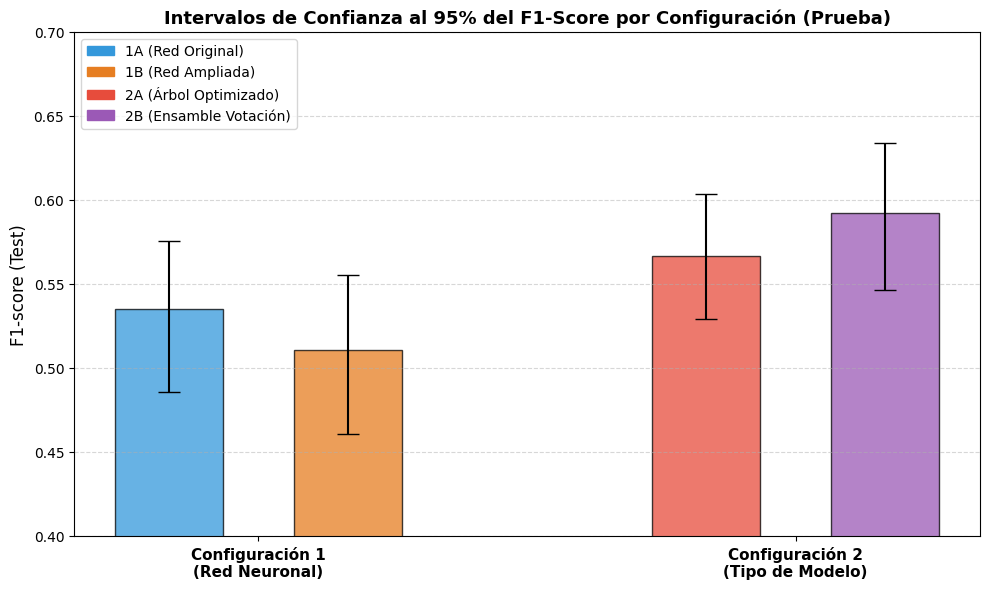

In [53]:
# 1. Cálculo del intervalo de confianza al 95% con el método de percentiles (guía)
ic_1A = np.percentile(f1_1A_boot, [2.5, 97.5])
ic_1B = np.percentile(f1_1B_boot, [2.5, 97.5])
ic_2A = np.percentile(f1_2A_boot, [2.5, 97.5])
ic_2B = np.percentile(f1_2B_boot, [2.5, 97.5])

# Métricas puntuales en el conjunto de prueba completo
f1_test_1A = f1_score(y_test, pred_1A)
f1_test_1B = f1_score(y_test, pred_1B)
f1_test_2A = f1_score(y_test, pred_2A)
f1_test_2B = f1_score(y_test, pred_2B)

# 2. Resumen en DataFrame
tabla_ic = pd.DataFrame([
    {"Configuración": "Configuración 1", "Modelo": "Modelo 1A (Red Original)", "F1 Test": f1_test_1A, "IC 2.5%": ic_1A[0], "IC 97.5%": ic_1A[1]},
    {"Configuración": "Configuración 1", "Modelo": "Modelo 1B (Red Ampliada)", "F1 Test": f1_test_1B, "IC 2.5%": ic_1B[0], "IC 97.5%": ic_1B[1]},
    {"Configuración": "Configuración 2", "Modelo": "Modelo 2A (Árbol Opt)", "F1 Test": f1_test_2A, "IC 2.5%": ic_2A[0], "IC 97.5%": ic_2A[1]},
    {"Configuración": "Configuración 2", "Modelo": "Modelo 2B (Ensamble Vot)", "F1 Test": f1_test_2B, "IC 2.5%": ic_2B[0], "IC 97.5%": ic_2B[1]}
])

print("--- INTERVALOS DE CONFIANZA 95% (MÉTODO DE PERCENTILES) ---")
display(tabla_ic.round(4))

# 3. Gráfica de Barras de Error agrupadas por Configuración
fig, ax = plt.subplots(figsize=(10, 6))

f1_vals = [f1_test_1A, f1_test_1B, f1_test_2A, f1_test_2B]

# Calcular magnitudes de error asimétrico [f1 - limite_inf, limite_sup - f1]
yerr_lower = [f1_test_1A - ic_1A[0], f1_test_1B - ic_1B[0], f1_test_2A - ic_2A[0], f1_test_2B - ic_2B[0]]
yerr_upper = [ic_1A[1] - f1_test_1A, ic_1B[1] - f1_test_1B, ic_2A[1] - f1_test_2A, ic_2B[1] - f1_test_2B]
yerr = [yerr_lower, yerr_upper]

colores = ['#3498db', '#e67e22', '#e74c3c', '#9b59b6']
posiciones = [0, 1, 3, 4]  # Separación entre Configuraciones

bars = ax.bar(posiciones, f1_vals, yerr=yerr, capsize=8, color=colores, alpha=0.75, edgecolor='black', width=0.6)

# Etiquetas y formato
ax.set_xticks([0.5, 3.5])
ax.set_xticklabels(['Configuración 1\n(Red Neuronal)', 'Configuración 2\n(Tipo de Modelo)'], fontsize=11, fontweight='bold')
ax.set_ylabel('F1-score (Test)', fontsize=12)
ax.set_title('Intervalos de Confianza al 95% del F1-Score por Configuración (Prueba)', fontsize=13, fontweight='bold')
ax.set_ylim(0.40, 0.70)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Leyenda
etiquetas_modelos = ['1A (Red Original)', '1B (Red Ampliada)', '2A (Árbol Optimizado)', '2B (Ensamble Votación)']
parches = [mpatches.Patch(color=colores[i], label=etiquetas_modelos[i]) for i in range(4)]
ax.legend(handles=parches, loc='upper left')

plt.tight_layout()
plt.show()

Con el F1 de prueba como estimación puntual, la red original obtiene 0,5348, con un intervalo entre 0,4856 y 0,5753, y la ampliada 0,5104, entre 0,4605 y 0,5550. El árbol obtiene 0,5666, entre 0,5289 y 0,6036, y el ensamble 0,5924, entre 0,5463 y 0,6338. En las dos configuraciones los intervalos se superponen, así que con esta comparación no se puede afirmar que un modelo sea mejor que el otro. Esto tampoco demuestra que sean equivalentes: comparar intervalos por separado es una prueba muy exigente, y como los cuatro modelos se evaluaron sobre los mismos clientes, la forma correcta de decidir es construir el intervalo de la diferencia entre ellos, lo que se hace más adelante con la prueba pareada.

## Contraste

In [54]:
# Métricas puntuales en prueba
f1_test_1A = f1_score(y_test, pred_1A)
f1_test_1B = f1_score(y_test, pred_1B)
f1_test_2A = f1_score(y_test, pred_2A)
f1_test_2B = f1_score(y_test, pred_2B)

# Tabla consolidada del Punto 9
tabla_contraste = pd.DataFrame([
    {
        "Configuración": "Configuración 1",
        "Modelo": "Modelo 1A (Red Original)",
        "F1 Validación": f1_score(y_val, y_pred_1A),
        "F1 Prueba": f1_test_1A,
        "IC 95% Prueba": f"[{ic_1A[0]:.4f}, {ic_1A[1]:.4f}]",
        "¿F1 Val en IC Prueba?": "Sí" if ic_1A[0] <= f1_score(y_val, y_pred_1A) <= ic_1A[1] else "No"
    },
    {
        "Configuración": "Configuración 1",
        "Modelo": "Modelo 1B (Red Ampliada)",
        "F1 Validación": f1_score(y_val, y_pred_1B),
        "F1 Prueba": f1_test_1B,
        "IC 95% Prueba": f"[{ic_1B[0]:.4f}, {ic_1B[1]:.4f}]",
        "¿F1 Val en IC Prueba?": "Sí" if ic_1B[0] <= f1_score(y_val, y_pred_1B) <= ic_1B[1] else "No"
    },
    {
        "Configuración": "Configuración 2",
        "Modelo": "Modelo 2A (Árbol Opt)",
        "F1 Validación": f1_score(y_val, y_pred_2A),
        "F1 Prueba": f1_test_2A,
        "IC 95% Prueba": f"[{ic_2A[0]:.4f}, {ic_2A[1]:.4f}]",
        "¿F1 Val en IC Prueba?": "Sí" if ic_2A[0] <= f1_score(y_val, y_pred_2A) <= ic_2A[1] else "No"
    },
    {
        "Configuración": "Configuración 2",
        "Modelo": "Modelo 2B (Ensamble Vot)",
        "F1 Validación": f1_score(y_val, y_pred_2B),
        "F1 Prueba": f1_test_2B,
        "IC 95% Prueba": f"[{ic_2B[0]:.4f}, {ic_2B[1]:.4f}]",
        "¿F1 Val en IC Prueba?": "Sí" if ic_2B[0] <= f1_score(y_val, y_pred_2B) <= ic_2B[1] else "No"
    }
])

print("--- CONTRASTE DE MÉTRICAS: VALIDACIÓN VS. PRUEBA ---")
display(tabla_contraste.round(4))

--- CONTRASTE DE MÉTRICAS: VALIDACIÓN VS. PRUEBA ---


,Configuración,Modelo,F1 Validación,F1 Prueba,IC 95% Prueba,¿F1 Val en IC Prueba?
0,Configuración 1,Modelo 1A (Red Original),0.5533,0.5348,"[0.4856, 0.5753]",Sí
1,Configuración 1,Modelo 1B (Red Ampliada),0.5390,0.5104,"[0.4605, 0.5550]",Sí
2,Configuración 2,Modelo 2A (Árbol Opt),0.5426,0.5666,"[0.5289, 0.6036]",Sí
3,Configuración 2,Modelo 2B (Ensamble Vot),0.5835,0.5924,"[0.5463, 0.6338]",Sí


El F1 de validación de los cuatro modelos queda dentro del intervalo de confianza calculado en prueba: 0,5533 para la red original, 0,5390 para la ampliada, 0,5426 para el árbol y 0,5835 para el ensamble. Es decir, el desempeño que se observó al elegir los modelos se sostiene con clientes que ninguno había visto, y no hay señales de sobreajuste. El orden también se mantiene: el ensamble es el mejor en F1 en ambos conjuntos y la red original supera a la ampliada en ambos.

## Sig. Intervalos

Para el banco, el intervalo de 0,5463 a 0,6338 del ensamble es el rango de F1 que razonablemente puede esperar al aplicar el modelo a nuevos clientes con un perfil similar al de esta base. La lectura correcta es que, si el procedimiento se repitiera con muchas muestras de clientes, el 95% de los intervalos construidos así contendría el desempeño real; no es una garantía sobre un resultado particular. El ancho del intervalo depende sobre todo de cuántos clientes que abandonan hay en la muestra de prueba, que son solo 407 de 2.000: con el doble de clientes, el intervalo sería aproximadamente un 29% más angosto, porque su ancho se reduce con la raíz cuadrada del tamaño de la muestra. Por último, comparar dos valores puntuales de F1 tiene tres limitaciones para el negocio: ignora la variabilidad de la muestra, trata igual una falsa alarma que un abandono no detectado aunque cuestan distinto, y depende del umbral de 0,5, que el banco puede mover según el costo de la campaña.

## Diferencia significativa

In [55]:
UMBRAL = 0.02

def calcular_metricas_dict(y_true, y_pred):
    return {
        'Precisión': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-score': f1_score(y_true, y_pred)
    }

def generar_filas_config(y_true, pred_A, pred_B, config_nombre, conjunto_nombre, label_A, label_B):
    mA = calcular_metricas_dict(y_true, pred_A)
    mB = calcular_metricas_dict(y_true, pred_B)
    
    filas = []
    for metrica in ['F1-score', 'Precisión', 'Recall']:
        val_A = mA[metrica]
        val_B = mB[metrica]
        diff = val_B - val_A
        filas.append({
            'Conjunto': conjunto_nombre,
            'Configuración': config_nombre,
            'Métrica': metrica,
            'Modelo A': val_A,
            'Modelo B': val_B,
            'Diferencia (B - A)': diff,
            '¿|Diff| >= 0.02?': abs(diff) >= UMBRAL
        })
    return filas

# 1. Filas para Validación (reutilizando tus variables del Punto 6)
filas_val_c1 = generar_filas_config(y_val, y_pred_1A, y_pred_1B, 'Configuración 1 (Neuronal)', 'Validación', '1A', '1B')
filas_val_c2 = generar_filas_config(y_val, y_pred_2A, y_pred_2B, 'Configuración 2 (Tipo Modelo)', 'Validación', '2A', '2B')

# 2. Filas para Prueba (reutilizando tus variables del Bootstrapping)
filas_test_c1 = generar_filas_config(y_test, pred_1A, pred_1B, 'Configuración 1 (Neuronal)', 'Prueba', '1A', '1B')
filas_test_c2 = generar_filas_config(y_test, pred_2A, pred_2B, 'Configuración 2 (Tipo Modelo)', 'Prueba', '2A', '2B')

# 3. Consolidador final
df_resultado_p1 = pd.DataFrame(filas_val_c1 + filas_val_c2 + filas_test_c1 + filas_test_c2)

print("--- COMPARACIÓN DE MÉTRICAS Y EVALUACIÓN DE UMBRAL RELEVANTE (0.02) ---")
display(df_resultado_p1.round(4))

--- COMPARACIÓN DE MÉTRICAS Y EVALUACIÓN DE UMBRAL RELEVANTE (0.02) ---


,Conjunto,Configuración,Métrica,Modelo A,Modelo B,Diferencia (B - A),¿|Diff| >= 0.02?
0,Validación,Configuración 1 (Neuronal),F1-score,0.5533,0.5390,-0.0143,False
1,Validación,Configuración 1 (Neuronal),Precisión,0.7838,0.7943,0.0105,False
2,Validación,Configuración 1 (Neuronal),Recall,0.4275,0.4079,-0.0197,False
3,Validación,Configuración 2 (Tipo Modelo),F1-score,0.5426,0.5835,0.0408,True
4,Validación,Configuración 2 (Tipo Modelo),Precisión,0.4480,0.6797,0.2317,True
5,Validación,Configuración 2 (Tipo Modelo),Recall,0.6880,0.5111,-0.1769,True
6,Prueba,Configuración 1 (Neuronal),F1-score,0.5348,0.5104,-0.0244,True
7,Prueba,Configuración 1 (Neuronal),Precisión,0.7857,0.7361,-0.0496,True
8,Prueba,Configuración 1 (Neuronal),Recall,0.4054,0.3907,-0.0147,False
9,Prueba,Configuración 2 (Tipo Modelo),F1-score,0.5666,0.5924,0.0258,True


Se usa un umbral de relevancia práctica de 2 puntos: una diferencia menor no justifica cambiar de modelo, aunque sea estadísticamente significativa, porque no alcanza a mover el resultado de la campaña. En la red, agregar las variables derivadas no supera ese umbral en ninguna métrica de validación, pero en prueba la red ampliada queda 2,44 puntos por debajo en F1 y 4,96 puntos por debajo en precisión, lo que refuerza la elección de la red original. En la configuración 2, todas las diferencias son relevantes en ambos conjuntos, pero van en direcciones opuestas: en prueba el ensamble tiene 23,52 puntos más de precisión y el árbol 22,11 puntos más de recall, mientras que la ventaja del ensamble en F1 es de solo 2,58 puntos. Por eso una mejora en F1 no se traduce automáticamente en más ganancia: lo que decide es si los clientes adicionales que detecta el árbol valen más que el costo de los 350 contactos adicionales que exige, y eso depende del costo por contacto y del valor del cliente, no de la métrica.

## Pruebas A/B

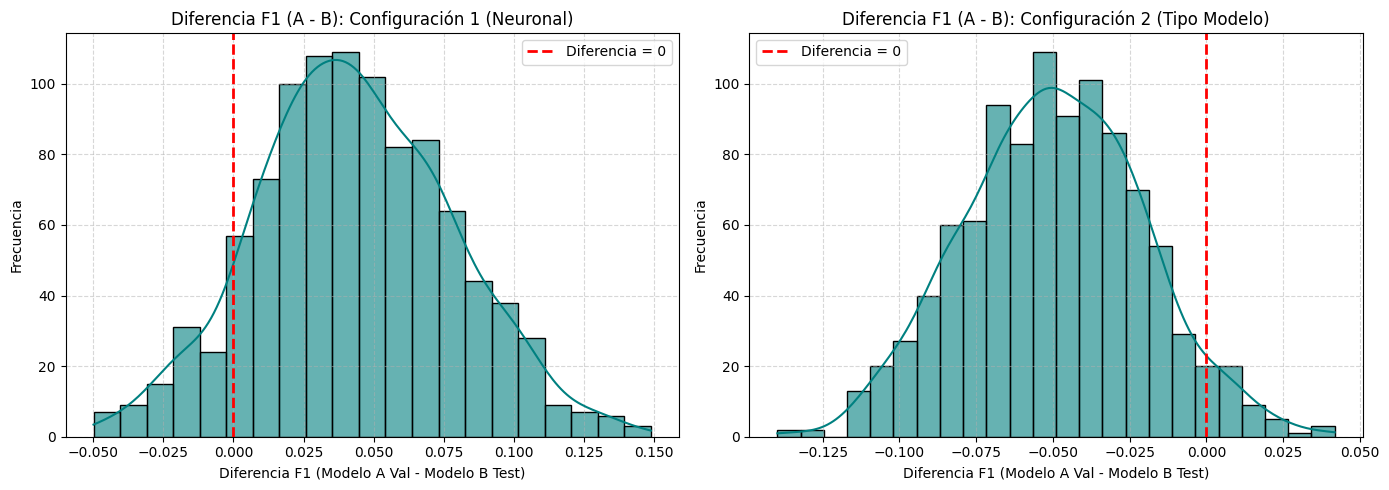

--- TABLA PRUEBA A/B BOOTSTRAP INDEPENDIENTE (PARTES A y B) ---


,Configuración,Métrica,Diferencia Observada (A - B),IC 95% Diferencia,Valor p (Bootstrap)
0,Configuración 1 (Neuronal),F1-score,0.0428,"[-0.0234, 0.1107]",0.186
1,Configuración 1 (Neuronal),Precisión,0.0477,"[-0.0292, 0.1252]",0.240
2,Configuración 1 (Neuronal),Recall,0.0369,"[-0.0326, 0.1053]",0.264
3,Configuración 2 (Tipo Modelo),F1-score,-0.0497,"[-0.1051, 0.0078]",0.098
4,Configuración 2 (Tipo Modelo),Precisión,-0.2474,"[-0.3095, -0.1818]",0.000
5,Configuración 2 (Tipo Modelo),Recall,0.1720,"[0.1048, 0.2422]",0.000



--- TABLA PRUEBA T DE WELCH POR CLIENTE (PARTE C) ---


,Configuración,Métrica,Estadístico t,Valor p (Welch)
0,Configuración 1 (Neuronal),Exactitud,1.0730,0.2833
1,Configuración 1 (Neuronal),Recall,1.0688,0.2855
2,Configuración 1 (Neuronal),Precisión,1.1665,0.2441
3,Configuración 2 (Tipo Modelo),Exactitud,-7.4207,0.0000
4,Configuración 2 (Tipo Modelo),Recall,5.0853,0.0000
5,Configuración 2 (Tipo Modelo),Precisión,-7.4581,0.0000


In [56]:
# 1. Asegurar arreglos NumPy de clases reales y predicciones
y_val_arr = np.asarray(y_val)
y_test_arr = np.asarray(y_test)

n_val = len(y_val_arr)
n_test = len(y_test_arr)

# Mapeo de predicciones por configuración (Modelo A en Val, Modelo B en Test)
configuraciones = {
    'Configuración 1 (Neuronal)': {
        'pred_A_val': np.asarray(y_pred_1A),      # Modelo 1A en val
        'pred_B_test': np.asarray(pred_1B)       # Modelo 1B en test
    },
    'Configuración 2 (Tipo Modelo)': {
        'pred_A_val': np.asarray(y_pred_2A),      # Modelo 2A en val
        'pred_B_test': np.asarray(pred_2B)       # Modelo 2B en test
    }
}

# 2. Bootstrapping con Grupos Independientes (B = 1000, Semilla 42)
rng = np.random.default_rng(42)
B = 1000

res_boot_ab = []
diff_f1_dict = {}

for config_nombre, preds in configuraciones.items():
    pA_val = preds['pred_A_val']
    pB_test = preds['pred_B_test']
    
    diff_f1, diff_prec, diff_rec = [], [], []
    
    for _ in range(B):
        # Remuestreo independiente
        idx_val = rng.integers(0, n_val, n_val)
        idx_test = rng.integers(0, n_test, n_test)
        
        y_v_sub, pA_sub = y_val_arr[idx_val], pA_val[idx_val]
        y_t_sub, pB_sub = y_test_arr[idx_test], pB_test[idx_test]
        
        # Métricas Modelo A (Val)
        f1_A = f1_score(y_v_sub, pA_sub)
        prec_A = precision_score(y_v_sub, pA_sub, zero_division=0)
        rec_A = recall_score(y_v_sub, pA_sub, zero_division=0)
        
        # Métricas Modelo B (Test)
        f1_B = f1_score(y_t_sub, pB_sub)
        prec_B = precision_score(y_t_sub, pB_sub, zero_division=0)
        rec_B = recall_score(y_t_sub, pB_sub, zero_division=0)
        
        # Diferencias A - B
        diff_f1.append(f1_A - f1_B)
        diff_prec.append(prec_A - prec_B)
        diff_rec.append(rec_A - rec_B)
        
    diff_f1 = np.array(diff_f1)
    diff_prec = np.array(diff_prec)
    diff_rec = np.array(diff_rec)
    
    diff_f1_dict[config_nombre] = diff_f1
    
    # Calcular métricas observadas globales (sin bootstrap)
    f1_obs_A, f1_obs_B = f1_score(y_val_arr, pA_val), f1_score(y_test_arr, pB_test)
    prec_obs_A, prec_obs_B = precision_score(y_val_arr, pA_val), precision_score(y_test_arr, pB_test)
    rec_obs_A, rec_obs_B = recall_score(y_val_arr, pA_val), recall_score(y_test_arr, pB_test)
    
    metricas_eval = [
        ('F1-score', f1_obs_A - f1_obs_B, diff_f1),
        ('Precisión', prec_obs_A - prec_obs_B, diff_prec),
        ('Recall', rec_obs_A - rec_obs_B, diff_rec)
    ]
    
    for nombre_m, diff_obs, diff_array in metricas_eval:
        ic_lower = np.percentile(diff_array, 2.5)
        ic_upper = np.percentile(diff_array, 97.5)
        # Valor p empírico de dos colas
        p_val_boot = 2 * min(np.mean(diff_array <= 0), np.mean(diff_array >= 0))
        p_val_boot = min(p_val_boot, 1.0)
        
        res_boot_ab.append({
            'Configuración': config_nombre,
            'Métrica': nombre_m,
            'Diferencia Observada (A - B)': diff_obs,
            'IC 95% Diferencia': f"[{ic_lower:.4f}, {ic_upper:.4f}]",
            'Valor p (Bootstrap)': p_val_boot
        })

df_res_boot_ab = pd.DataFrame(res_boot_ab)

# 3. Graficar Histogramas de la Diferencia de F1 (A - B)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (config_nombre, diff_f1_vals) in enumerate(diff_f1_dict.items()):
    sns.histplot(diff_f1_vals, kde=True, ax=axes[i], color='teal', alpha=0.6)
    axes[i].axvline(0, color='red', linestyle='--', linewidth=2, label='Diferencia = 0')
    axes[i].set_title(f"Diferencia F1 (A - B): {config_nombre}")
    axes[i].set_xlabel("Diferencia F1 (Modelo A Val - Modelo B Test)")
    axes[i].set_ylabel("Frecuencia")
    axes[i].legend()
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("--- TABLA PRUEBA A/B BOOTSTRAP INDEPENDIENTE (PARTES A y B) ---")
display(df_res_boot_ab.round(4))

# 4. Parte C: Prueba t-estudiante de Welch (stats.ttest_ind sobre valores por cliente)
res_welch = []

for config_nombre, preds in configuraciones.items():
    pA_val = preds['pred_A_val']
    pB_test = preds['pred_B_test']
    
    # Exactitud por cliente (1 si acierta, 0 si falla)
    acc_val = (y_val_arr == pA_val).astype(int)
    acc_test = (y_test_arr == pB_test).astype(int)
    t_stat_acc, p_val_acc = stats.ttest_ind(acc_val, acc_test, equal_var=False)
    
    # Recall por cliente (solo en instancias donde y = 1)
    rec_val = pA_val[y_val_arr == 1]
    rec_test = pB_test[y_test_arr == 1]
    t_stat_rec, p_val_rec = stats.ttest_ind(rec_val, rec_test, equal_var=False)
    
    # Precisión por cliente (solo en instancias donde pred == 1)
    prec_val = y_val_arr[pA_val == 1]
    prec_test = y_test_arr[pB_test == 1]
    t_stat_prec, p_val_prec = stats.ttest_ind(prec_val, prec_test, equal_var=False)
    
    res_welch.extend([
        {'Configuración': config_nombre, 'Métrica': 'Exactitud', 'Estadístico t': t_stat_acc, 'Valor p (Welch)': p_val_acc},
        {'Configuración': config_nombre, 'Métrica': 'Recall', 'Estadístico t': t_stat_rec, 'Valor p (Welch)': p_val_rec},
        {'Configuración': config_nombre, 'Métrica': 'Precisión', 'Estadístico t': t_stat_prec, 'Valor p (Welch)': p_val_prec}
    ])

df_res_welch = pd.DataFrame(res_welch)
print("\n--- TABLA PRUEBA T DE WELCH POR CLIENTE (PARTE C) ---")
display(df_res_welch.round(4))

Este diseño sigue el ejercicio de la práctica y compara el modelo A evaluado en validación con el modelo B evaluado en prueba. Son grupos independientes porque la partición asigna cada cliente a un solo conjunto. En la red, ningún intervalo de la diferencia excluye el cero (en F1 va de −0,0234 a 0,1107, con un valor p de 0,186), y la prueba t de Welch tampoco encuentra diferencias en exactitud, recall ni precisión. En la configuración 2, la diferencia de F1 tampoco es significativa (intervalo entre −0,1051 y 0,0078, valor p de 0,098), pero sí lo son la precisión, a favor del ensamble, y el recall, a favor del árbol, con valores p cercanos a cero tanto por bootstrapping como por Welch. El valor p del bootstrapping y el intervalo llegan siempre a la misma conclusión. El F1 solo se puede comparar por bootstrapping, porque no es un promedio de un valor que se pueda medir cliente por cliente, que es lo que necesita la prueba t. La limitación de este diseño es que cambia al mismo tiempo el modelo y los clientes evaluados, así que una diferencia puede deberse a cualquiera de los dos; por eso la comparación que sustenta la decisión es la pareada.

## Numero de replicas

In [57]:
# 1. Preparación de datos y predicciones
y_val_arr = np.asarray(y_val)
y_test_arr = np.asarray(y_test)

n_val = len(y_val_arr)
n_test = len(y_test_arr)

configuraciones = {
    'Configuración 1 (Neuronal)': {
        'pred_A_val': np.asarray(y_pred_1A),
        'pred_B_test': np.asarray(pred_1B)
    },
    'Configuración 2 (Tipo Modelo)': {
        'pred_A_val': np.asarray(y_pred_2A),
        'pred_B_test': np.asarray(pred_2B)
    }
}

# 2. Evaluación para distintos valores de B (200, 1000, 5000)
replicas_list = [200, 1000, 5000]
resultados_replicas = []

for config_nombre, preds in configuraciones.items():
    pA_val = preds['pred_A_val']
    pB_test = preds['pred_B_test']
    
    for B_val in replicas_list:
        rng = np.random.default_rng(42)  # Semilla para comparabilidad
        
        f1_A_list = []
        f1_B_list = []
        
        for _ in range(B_val):
            idx_val = rng.integers(0, n_val, n_val)
            idx_test = rng.integers(0, n_test, n_test)
            
            f1_A_list.append(f1_score(y_val_arr[idx_val], pA_val[idx_val]))
            f1_B_list.append(f1_score(y_test_arr[idx_test], pB_test[idx_test]))
            
        f1_A_arr = np.array(f1_A_list)
        f1_B_arr = np.array(f1_B_list)
        diff_arr = f1_A_arr - f1_B_arr
        
        # IC 95% Bootstrap
        ic_lower = np.percentile(diff_arr, 2.5)
        ic_upper = np.percentile(diff_arr, 97.5)
        
        # Valor p por Bootstrap
        p_val_boot = 2 * min(np.mean(diff_arr <= 0), np.mean(diff_arr >= 0))
        p_val_boot = min(p_val_boot, 1.0)
        
        # PRUEBA T SOBRE RÉPLICAS (Solo para observar el problema)
        t_stat, p_val_ttest_replicas = stats.ttest_ind(f1_A_arr, f1_B_arr, equal_var=False)
        
        resultados_replicas.append({
            'Configuración': config_nombre,
            'Réplicas (B)': B_val,
            'Diferencia Promedio F1': diff_arr.mean(),
            'IC 95% Bootstrap': f"[{ic_lower:.4f}, {ic_upper:.4f}]",
            'Valor p (Bootstrap)': p_val_boot,
            'Valor p (Prueba t sobre Réplicas)': p_val_ttest_replicas
        })

df_res_replicas = pd.DataFrame(resultados_replicas)

print("--- EFECTO DEL NÚMERO DE RÉPLICAS (B) EN BOOTSTRAP Y PRUEBA T SOBRE RÉPLICAS ---")
display(df_res_replicas.round(6))

--- EFECTO DEL NÚMERO DE RÉPLICAS (B) EN BOOTSTRAP Y PRUEBA T SOBRE RÉPLICAS ---


,Configuración,Réplicas (B),Diferencia Promedio F1,IC 95% Bootstrap,Valor p (Bootstrap),Valor p (Prueba t sobre Réplicas)
0,Configuración 1 (Neuronal),200,0.041691,"[-0.0283, 0.1127]",0.2400,0.0
1,Configuración 1 (Neuronal),1000,0.043180,"[-0.0234, 0.1107]",0.1860,0.0
2,Configuración 1 (Neuronal),5000,0.043391,"[-0.0243, 0.1103]",0.2064,0.0
3,Configuración 2 (Tipo Modelo),200,-0.052122,"[-0.1096, 0.0108]",0.1200,0.0
4,Configuración 2 (Tipo Modelo),1000,-0.049473,"[-0.1078, 0.0108]",0.1120,0.0
5,Configuración 2 (Tipo Modelo),5000,-0.049374,"[-0.1055, 0.0083]",0.0984,0.0


Al aumentar las réplicas de 200 a 5.000, el intervalo y el valor p del bootstrapping casi no cambian: en la red el valor p se mueve entre 0,186 y 0,240, y en la configuración 2 entre 0,098 y 0,120, siempre por encima de 0,05. Más réplicas solo afinan la estimación, porque la evidencia sigue siendo la misma: los 2.000 clientes de validación y los 2.000 de prueba. En cambio, una prueba t aplicada sobre las réplicas da un valor p de cero en todos los casos, porque trata cada réplica como si fuera un cliente nuevo e infla artificialmente el tamaño de la muestra. Esa significancia es falsa y no debe usarse para tomar decisiones.

## A/B Pareada

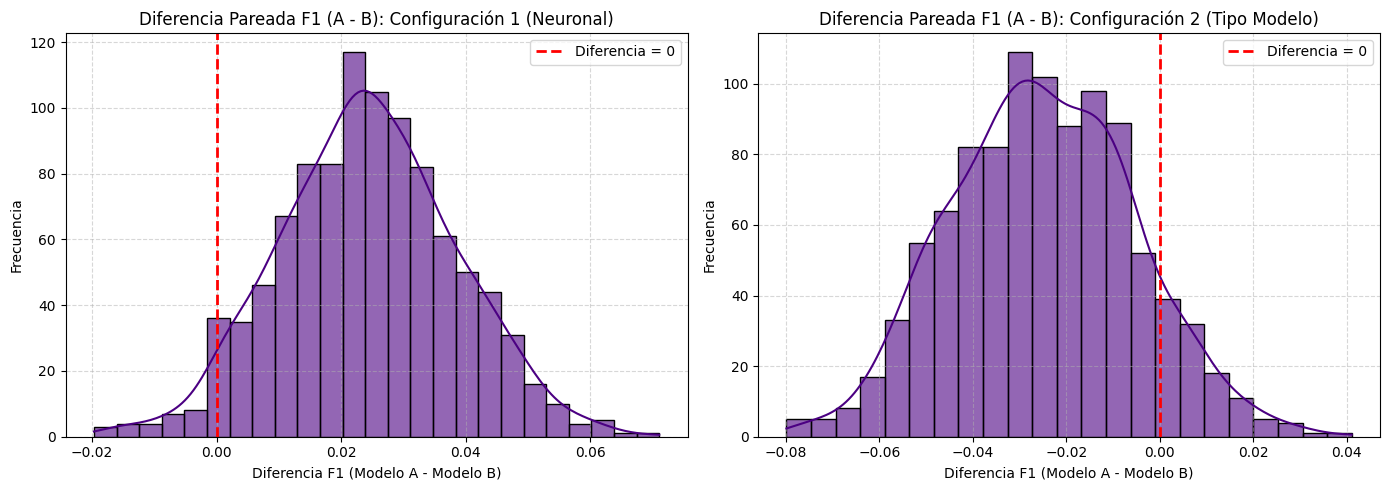

--- TABLA PRUEBA A/B BOOTSTRAP PAREADO (PARTE A y B) ---


,Configuración,Métrica,Diferencia Observada (A - B),IC 95% Diferencia Pareada,Valor p (Bootstrap Pareado)
0,Configuración 1 (Neuronal),F1-score,0.0244,"[-0.0019, 0.0518]",0.076
1,Configuración 1 (Neuronal),Precisión,0.0496,"[0.0136, 0.0888]",0.008
2,Configuración 1 (Neuronal),Recall,0.0147,"[-0.0125, 0.0422]",0.342
3,Configuración 2 (Tipo Modelo),F1-score,-0.0258,"[-0.0610, 0.0133]",0.212
4,Configuración 2 (Tipo Modelo),Precisión,-0.2352,"[-0.2749, -0.1933]",0.000
5,Configuración 2 (Tipo Modelo),Recall,0.2211,"[0.1789, 0.2638]",0.000



--- TABLA PRUEBA T PAREADA POR CLIENTE (PARTE C) ---


,Configuración,Métrica,Estadístico t,Valor p (t pareada)
0,Configuración 1 (Neuronal),Exactitud,2.4082,0.0161
1,Configuración 1 (Neuronal),Recall,1.0608,0.2894
2,Configuración 2 (Tipo Modelo),Exactitud,-9.1963,0.0000
3,Configuración 2 (Tipo Modelo),Recall,10.5863,0.0000


In [58]:
# 1. Asegurar arreglos NumPy de clase real y predicciones en prueba
y_test_arr = np.asarray(y_test)
n_test = len(y_test_arr)

configuraciones_test = {
    'Configuración 1 (Neuronal)': {
        'pred_A': np.asarray(pred_1A),
        'pred_B': np.asarray(pred_1B)
    },
    'Configuración 2 (Tipo Modelo)': {
        'pred_A': np.asarray(pred_2A),
        'pred_B': np.asarray(pred_2B)
    }
}

# 2. Bootstrapping Pareado (B = 1000, Semilla 42)
rng = np.random.default_rng(42)
B = 1000

res_boot_pareado = []
diff_f1_pareado_dict = {}

for config_nombre, preds in configuraciones_test.items():
    pA = preds['pred_A']
    pB = preds['pred_B']
    
    diff_f1, diff_prec, diff_rec = [], [], []
    
    for _ in range(B):
        # Muestra pareada (mismos índices para ambos modelos)
        idx = rng.integers(0, n_test, n_test)
        y_sub, pA_sub, pB_sub = y_test_arr[idx], pA[idx], pB[idx]
        
        # Métricas Modelo A
        f1_A = f1_score(y_sub, pA_sub, zero_division=0)
        prec_A = precision_score(y_sub, pA_sub, zero_division=0)
        rec_A = recall_score(y_sub, pA_sub, zero_division=0)
        
        # Métricas Modelo B
        f1_B = f1_score(y_sub, pB_sub, zero_division=0)
        prec_B = precision_score(y_sub, pB_sub, zero_division=0)
        rec_B = recall_score(y_sub, pB_sub, zero_division=0)
        
        # Diferencia pareada (A - B)
        diff_f1.append(f1_A - f1_B)
        diff_prec.append(prec_A - prec_B)
        diff_rec.append(rec_A - rec_B)
        
    diff_f1 = np.array(diff_f1)
    diff_prec = np.array(diff_prec)
    diff_rec = np.array(diff_rec)
    
    diff_f1_pareado_dict[config_nombre] = diff_f1
    
    # Diferencias observadas sobre el conjunto completo de prueba
    f1_obs_A, f1_obs_B = f1_score(y_test_arr, pA), f1_score(y_test_arr, pB)
    prec_obs_A, prec_obs_B = precision_score(y_test_arr, pA), precision_score(y_test_arr, pB)
    rec_obs_A, rec_obs_B = recall_score(y_test_arr, pA), recall_score(y_test_arr, pB)
    
    metricas_eval = [
        ('F1-score', f1_obs_A - f1_obs_B, diff_f1),
        ('Precisión', prec_obs_A - prec_obs_B, diff_prec),
        ('Recall', rec_obs_A - rec_obs_B, diff_rec)
    ]
    
    for nombre_m, diff_obs, diff_array in metricas_eval:
        ic_lower = np.percentile(diff_array, 2.5)
        ic_upper = np.percentile(diff_array, 97.5)
        
        p_val_boot = 2 * min(np.mean(diff_array <= 0), np.mean(diff_array >= 0))
        p_val_boot = min(p_val_boot, 1.0)
        
        res_boot_pareado.append({
            'Configuración': config_nombre,
            'Métrica': nombre_m,
            'Diferencia Observada (A - B)': diff_obs,
            'IC 95% Diferencia Pareada': f"[{ic_lower:.4f}, {ic_upper:.4f}]",
            'Valor p (Bootstrap Pareado)': p_val_boot
        })

df_res_boot_pareado = pd.DataFrame(res_boot_pareado)

# 3. Graficar Histogramas de la Diferencia Pareada de F1 (A - B)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, (config_nombre, diff_f1_vals) in enumerate(diff_f1_pareado_dict.items()):
    sns.histplot(diff_f1_vals, kde=True, ax=axes[i], color='indigo', alpha=0.6)
    axes[i].axvline(0, color='red', linestyle='--', linewidth=2, label='Diferencia = 0')
    axes[i].set_title(f"Diferencia Pareada F1 (A - B): {config_nombre}")
    axes[i].set_xlabel("Diferencia F1 (Modelo A - Modelo B)")
    axes[i].set_ylabel("Frecuencia")
    axes[i].legend()
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print("--- TABLA PRUEBA A/B BOOTSTRAP PAREADO (PARTE A y B) ---")
display(df_res_boot_pareado.round(4))

# 4. Parte C: Prueba t Pareada (stats.ttest_rel sobre valores por cliente)
res_ttest_rel = []

for config_nombre, preds in configuraciones_test.items():
    pA = preds['pred_A']
    pB = preds['pred_B']
    
    # Exactitud por cliente
    acc_A = (y_test_arr == pA).astype(int)
    acc_B = (y_test_arr == pB).astype(int)
    t_stat_acc, p_val_acc = stats.ttest_rel(acc_A, acc_B)
    
    # Recall por cliente (filtrado por verdaderos positivos y = 1)
    positivos = (y_test_arr == 1)
    rec_A = pA[positivos]
    rec_B = pB[positivos]
    t_stat_rec, p_val_rec = stats.ttest_rel(rec_A, rec_B)
    
    res_ttest_rel.extend([
        {'Configuración': config_nombre, 'Métrica': 'Exactitud', 'Estadístico t': t_stat_acc, 'Valor p (t pareada)': p_val_acc},
        {'Configuración': config_nombre, 'Métrica': 'Recall', 'Estadístico t': t_stat_rec, 'Valor p (t pareada)': p_val_rec}
    ])

df_res_ttest_rel = pd.DataFrame(res_ttest_rel)
print("\n--- TABLA PRUEBA T PAREADA POR CLIENTE (PARTE C) ---")
display(df_res_ttest_rel.round(4))

La comparación pareada es la adecuada porque los dos modelos se evalúan sobre exactamente los mismos 2.000 clientes de prueba, así que la diferencia ya no se mezcla con diferencias entre grupos de clientes. Por eso sus intervalos son mucho más angostos: en el F1 de la red, el ancho baja de 0,1341 en el diseño independiente a 0,0537. En la red, la versión original es significativamente más precisa que la ampliada (4,96 puntos, valor p de 0,008), mientras que las diferencias en F1 (valor p de 0,076) y en recall (0,342) no son significativas. En la configuración 2, el F1 tampoco permite separar los modelos (valor p de 0,212), pero el ensamble es 23,52 puntos más preciso y el árbol detecta 22,11 puntos más de los clientes que se van, ambas diferencias con valor p cercano a cero. La prueba t pareada por cliente confirma la diferencia de recall en la configuración 2 y no la encuentra en la red (valor p de 0,289); en exactitud sí detecta una diferencia en la red (valor p de 0,016), pero menor a un punto, por debajo del umbral de relevancia. La precisión y el F1 se comparan solo por bootstrapping, porque cada modelo marca como positivos a clientes distintos y no hay pares cliente a cliente que comparar.

## McNemar 

In [59]:
# 1. Datos y predicciones del conjunto de prueba
y_test_arr = np.asarray(y_test)

configuraciones_mcnemar = {
    'Configuración 1 (Neuronal - 1A vs 1B)': {
        'pred_A': np.asarray(pred_1A),
        'pred_B': np.asarray(pred_1B)
    },
    'Configuración 2 (Tipo Modelo - 2A vs 2B)': {
        'pred_A': np.asarray(pred_2A),
        'pred_B': np.asarray(pred_2B)
    }
}

resultados_mcnemar = []

for config_nombre, preds in configuraciones_mcnemar.items():
    pA = preds['pred_A']
    pB = preds['pred_B']
    
    # --- EVALUACIÓN GLOBAL (EXACTITUD) ---
    acierta_A_all = (pA == y_test_arr)
    acierta_B_all = (pB == y_test_arr)
    
    tabla_all = pd.crosstab(
        acierta_A_all, acierta_B_all, 
        rownames=['A acierta'], colnames=['B acierta']
    )
    
    n10_all = tabla_all.loc[True, False] if (True in tabla_all.index and False in tabla_all.columns) else 0
    n01_all = tabla_all.loc[False, True] if (False in tabla_all.index and True in tabla_all.columns) else 0
    
    # Regla exactitud: si suma de desacuerdos < 25 se usa versión exacta
    exact_all = (n10_all + n01_all) < 25
    res_all = mcnemar(tabla_all.to_numpy(), exact=exact_all, correction=True)
    
    resultados_mcnemar.append({
        'Configuración': config_nombre,
        'Métrica Evaluada': 'Exactitud (Todos)',
        'Solo A Acierta (n10)': n10_all,
        'Solo B Acierta (n01)': n01_all,
        'Estadístico / Chi2': res_all.statistic,
        'Valor p (McNemar)': res_all.pvalue
    })
    
    print(f"\n==========================================")
    print(f"TABLA DE CONTINGENCIA - EXACTITUD: {config_nombre}")
    print(f"==========================================")
    display(tabla_all)

    # --- EVALUACIÓN EN CHURN == 1 (RECALL) ---
    mask_pos = (y_test_arr == 1)
    acierta_A_rec = (pA[mask_pos] == 1)
    acierta_B_rec = (pB[mask_pos] == 1)
    
    tabla_rec = pd.crosstab(
        acierta_A_rec, acierta_B_rec, 
        rownames=['A acierta (y=1)'], colnames=['B acierta (y=1)']
    )
    
    n10_rec = tabla_rec.loc[True, False] if (True in tabla_rec.index and False in tabla_rec.columns) else 0
    n01_rec = tabla_rec.loc[False, True] if (False in tabla_rec.index and True in tabla_rec.columns) else 0
    
    exact_rec = (n10_rec + n01_rec) < 25
    res_rec = mcnemar(tabla_rec.to_numpy(), exact=exact_rec, correction=True)
    
    resultados_mcnemar.append({
        'Configuración': config_nombre,
        'Métrica Evaluada': 'Recall (Churn = 1)',
        'Solo A Acierta (n10)': n10_rec,
        'Solo B Acierta (n01)': n01_rec,
        'Estadístico / Chi2': res_rec.statistic,
        'Valor p (McNemar)': res_rec.pvalue
    })
    
    print(f"\n==========================================")
    print(f"TABLA DE CONTINGENCIA - RECALL (Churn=1): {config_nombre}")
    print(f"==========================================")
    display(tabla_rec)

df_res_mcnemar = pd.DataFrame(resultados_mcnemar)
print("\n--- RESUMEN CONSOLIDADO PRUEBA DE MCNEMAR ---")
display(df_res_mcnemar.round(4))


TABLA DE CONTINGENCIA - EXACTITUD: Configuración 1 (Neuronal - 1A vs 1B)


B acierta,False,True
A acierta,,
False,268,19
True,37,1676



TABLA DE CONTINGENCIA - RECALL (Churn=1): Configuración 1 (Neuronal - 1A vs 1B)


B acierta (y=1),False,True
A acierta (y=1),,
False,229,13
True,19,146



TABLA DE CONTINGENCIA - EXACTITUD: Configuración 2 (Tipo Modelo - 2A vs 2B)


B acierta,False,True
A acierta,,
False,196,263
True,93,1448



TABLA DE CONTINGENCIA - RECALL (Churn=1): Configuración 2 (Tipo Modelo - 2A vs 2B)


B acierta (y=1),False,True
A acierta (y=1),,
False,106,1
True,91,209



--- RESUMEN CONSOLIDADO PRUEBA DE MCNEMAR ---


,Configuración,Métrica Evaluada,Solo A Acierta (n10),Solo B Acierta (n01),Estadístico / Chi2,Valor p (McNemar)
0,Configuración 1 (Neuronal - 1A vs 1B),Exactitud (Todos),37,19,5.1607,0.0231
1,Configuración 1 (Neuronal - 1A vs 1B),Recall (Churn = 1),19,13,0.7812,0.3768
2,Configuración 2 (Tipo Modelo - 2A vs 2B),Exactitud (Todos),93,263,80.2275,0.0000
3,Configuración 2 (Tipo Modelo - 2A vs 2B),Recall (Churn = 1),91,1,86.0978,0.0000


McNemar se concentra en los clientes donde los modelos no coinciden. En la red, la versión original acierta sola en 37 clientes y la ampliada en 19, una diferencia significativa en exactitud (valor p de 0,023), pero menor a un punto porcentual sobre 2.000 clientes. Entre los clientes que sí abandonan, la original detecta sola a 19 y la ampliada a 13, sin diferencia significativa (valor p de 0,377). En la configuración 2, el ensamble acierta solo en 263 clientes frente a 93 del árbol, pero entre los que abandonan el árbol detecta a 91 que el ensamble no ve, mientras que el ensamble detecta solo a 1 que el árbol no ve; ambas diferencias son significativas. Con todos los clientes la prueba compara la exactitud, y con los que abandonan compara el recall. Sus conclusiones coinciden con la prueba t pareada en todos los casos.


## Conclusion

In [60]:
UMBRAL = 0.02
B = 1000
rng = np.random.default_rng(42)

y_val_arr = np.asarray(y_val)
y_test_arr = np.asarray(y_test)
n_val = len(y_val_arr)
n_test = len(y_test_arr)

# Predicciones por configuración
configs = {
    'Configuración 1 (Neuronal - 1A vs 1B)': {
        'pred_A_val': np.asarray(y_pred_1A),
        'pred_B_val': np.asarray(y_pred_1B),
        'pred_A_test': np.asarray(pred_1A),
        'pred_B_test': np.asarray(pred_1B)
    },
    'Configuración 2 (Tipo Modelo - 2A vs 2B)': {
        'pred_A_val': np.asarray(y_pred_2A),
        'pred_B_val': np.asarray(y_pred_2B),
        'pred_A_test': np.asarray(pred_2A),
        'pred_B_test': np.asarray(pred_2B)
    }
}

# Función auxiliar para invocar métricas de forma segura sin pasar zero_division a accuracy_score
def eval_metric(func, y_true, y_pred):
    if func == accuracy_score:
        return func(y_true, y_pred)
    return func(y_true, y_pred, zero_division=0)

# 1. Función para superposición de ICs individuales en prueba
def obtener_ic_individuales(y_true, pA, pB, B=1000):
    metricas = ['F1', 'Precisión', 'Recall', 'Exactitud']
    funcs = {
        'F1': f1_score,
        'Precisión': precision_score,
        'Recall': recall_score,
        'Exactitud': accuracy_score
    }
    
    boot_A = {m: [] for m in metricas}
    boot_B = {m: [] for m in metricas}
    
    for _ in range(B):
        idx = rng.integers(0, len(y_true), len(y_true))
        y_sub, pA_sub, pB_sub = y_true[idx], pA[idx], pB[idx]
        for m, f in funcs.items():
            boot_A[m].append(eval_metric(f, y_sub, pA_sub))
            boot_B[m].append(eval_metric(f, y_sub, pB_sub))
            
    res = {}
    for m in metricas:
        ic_A = (np.percentile(boot_A[m], 2.5), np.percentile(boot_A[m], 97.5))
        ic_B = (np.percentile(boot_B[m], 2.5), np.percentile(boot_B[m], 97.5))
        # Superposición si max(L_A, L_B) <= min(U_A, U_B)
        superposicion = max(ic_A[0], ic_B[0]) <= min(ic_A[1], ic_B[1])
        sig = not superposicion
        
        diff_obs = abs(eval_metric(funcs[m], y_true, pB) - eval_metric(funcs[m], y_true, pA))
        relevante = diff_obs >= UMBRAL
        res[m] = f"Sig: {'Sí' if sig else 'No'} | Relev: {'Sí' if relevante else 'No'}"
    return res

# 2. Generación de tablas por configuración
for name, p in configs.items():
    pA_v, pB_v = p['pred_A_val'], p['pred_B_val']
    pA_t, pB_t = p['pred_A_test'], p['pred_B_test']
    
    # 2.1 Superposición IC Prueba
    col_superpos = obtener_ic_individuales(y_test_arr, pA_t, pB_t, B)
    
    # 2.2 A/B Independiente (Val A vs Test B)
    f1_obs_A, f1_obs_B = f1_score(y_val_arr, pA_v), f1_score(y_test_arr, pB_t)
    prec_obs_A, prec_obs_B = precision_score(y_val_arr, pA_v), precision_score(y_test_arr, pB_t)
    rec_obs_A, rec_obs_B = recall_score(y_val_arr, pA_v), recall_score(y_test_arr, pB_t)
    acc_obs_A, acc_obs_B = accuracy_score(y_val_arr, pA_v), accuracy_score(y_test_arr, pB_t)
    
    diff_f1_ind, diff_prec_ind, diff_rec_ind, diff_acc_ind = [], [], [], []
    for _ in range(B):
        iv, it = rng.integers(0, n_val, n_val), rng.integers(0, n_test, n_test)
        diff_f1_ind.append(f1_score(y_val_arr[iv], pA_v[iv], zero_division=0) - f1_score(y_test_arr[it], pB_t[it], zero_division=0))
        diff_prec_ind.append(precision_score(y_val_arr[iv], pA_v[iv], zero_division=0) - precision_score(y_test_arr[it], pB_t[it], zero_division=0))
        diff_rec_ind.append(recall_score(y_val_arr[iv], pA_v[iv], zero_division=0) - recall_score(y_test_arr[it], pB_t[it], zero_division=0))
        diff_acc_ind.append(accuracy_score(y_val_arr[iv], pA_v[iv]) - accuracy_score(y_test_arr[it], pB_t[it]))
        
    def eval_indep(diff_arr, diff_obs):
        ic_l, ic_u = np.percentile(diff_arr, 2.5), np.percentile(diff_arr, 97.5)
        sig = not (ic_l <= 0 <= ic_u)
        rel = abs(diff_obs) >= UMBRAL
        return f"Sig: {'Sí' if sig else 'No'} | Relev: {'Sí' if rel else 'No'}"

    col_indep = {
        'F1': eval_indep(diff_f1_ind, f1_obs_B - f1_obs_A),
        'Precisión': eval_indep(diff_prec_ind, prec_obs_B - prec_obs_A),
        'Recall': eval_indep(diff_rec_ind, rec_obs_B - rec_obs_A),
        'Exactitud': eval_indep(diff_acc_ind, acc_obs_B - acc_obs_A)
    }

    # 2.3 A/B Pareada en Prueba
    diff_f1_par, diff_prec_par, diff_rec_par, diff_acc_par = [], [], [], []
    for _ in range(B):
        it = rng.integers(0, n_test, n_test)
        diff_f1_par.append(f1_score(y_test_arr[it], pB_t[it], zero_division=0) - f1_score(y_test_arr[it], pA_t[it], zero_division=0))
        diff_prec_par.append(precision_score(y_test_arr[it], pB_t[it], zero_division=0) - precision_score(y_test_arr[it], pA_t[it], zero_division=0))
        diff_rec_par.append(recall_score(y_test_arr[it], pB_t[it], zero_division=0) - recall_score(y_test_arr[it], pA_t[it], zero_division=0))
        diff_acc_par.append(accuracy_score(y_test_arr[it], pB_t[it]) - accuracy_score(y_test_arr[it], pA_t[it]))

    col_pareado = {
        'F1': eval_indep(diff_f1_par, f1_score(y_test_arr, pB_t) - f1_score(y_test_arr, pA_t)),
        'Precisión': eval_indep(diff_prec_par, precision_score(y_test_arr, pB_t) - precision_score(y_test_arr, pA_t)),
        'Recall': eval_indep(diff_rec_par, recall_score(y_test_arr, pB_t) - recall_score(y_test_arr, pA_t)),
        'Exactitud': eval_indep(diff_acc_par, accuracy_score(y_test_arr, pB_t) - accuracy_score(y_test_arr, pA_t))
    }

    # 2.4 McNemar en Prueba
    ac_A, ac_B = (pA_t == y_test_arr), (pB_t == y_test_arr)
    t_acc = pd.crosstab(ac_A, ac_B)
    res_acc = mcnemar(t_acc.to_numpy(), exact=False, correction=True)
    sig_mcn_acc = res_acc.pvalue < 0.05
    rel_acc = abs(accuracy_score(y_test_arr, pB_t) - accuracy_score(y_test_arr, pA_t)) >= UMBRAL

    mask_pos = (y_test_arr == 1)
    ac_A_rec, ac_B_rec = (pA_t[mask_pos] == 1), (pB_t[mask_pos] == 1)
    t_rec = pd.crosstab(ac_A_rec, ac_B_rec)
    res_rec = mcnemar(t_rec.to_numpy(), exact=False, correction=True)
    sig_mcn_rec = res_rec.pvalue < 0.05
    rel_rec = abs(recall_score(y_test_arr, pB_t) - recall_score(y_test_arr, pA_t)) >= UMBRAL

    col_mcnemar = {
        'F1': 'No aplica',
        'Precisión': 'No aplica',
        'Recall': f"Sig: {'Sí' if sig_mcn_rec else 'No'} | Relev: {'Sí' if rel_rec else 'No'}",
        'Exactitud': f"Sig: {'Sí' if sig_mcn_acc else 'No'} | Relev: {'Sí' if rel_acc else 'No'}"
    }

    df_config = pd.DataFrame({
        'Superposición IC (Prueba)': col_superpos,
        'A/B Independiente (Val vs Test)': col_indep,
        'A/B Pareada (Prueba)': col_pareado,
        'McNemar (Prueba)': col_mcnemar
    })
    
    print(f"\n==================================================")
    print(f"TABLA RESUMEN DE MATRICES: {name}")
    print(f"==================================================")
    display(df_config)


TABLA RESUMEN DE MATRICES: Configuración 1 (Neuronal - 1A vs 1B)


,Superposición IC (Prueba),A/B Independiente (Val vs Test),A/B Pareada (Prueba),McNemar (Prueba)
F1,Sig: No | Relev: Sí,Sig: No | Relev: Sí,Sig: No | Relev: Sí,No aplica
Precisión,Sig: No | Relev: Sí,Sig: No | Relev: Sí,Sig: Sí | Relev: Sí,No aplica
Recall,Sig: No | Relev: No,Sig: No | Relev: Sí,Sig: No | Relev: No,Sig: No | Relev: No
Exactitud,Sig: No | Relev: No,Sig: No | Relev: No,Sig: Sí | Relev: No,Sig: Sí | Relev: No



TABLA RESUMEN DE MATRICES: Configuración 2 (Tipo Modelo - 2A vs 2B)


,Superposición IC (Prueba),A/B Independiente (Val vs Test),A/B Pareada (Prueba),McNemar (Prueba)
F1,Sig: No | Relev: Sí,Sig: No | Relev: Sí,Sig: No | Relev: Sí,No aplica
Precisión,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí,No aplica
Recall,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí
Exactitud,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí,Sig: Sí | Relev: Sí


Las cuatro formas de comparar coinciden en lo esencial. En la configuración 2, todas encuentran diferencias significativas y relevantes en precisión, recall y exactitud, y ninguna encuentra una diferencia significativa en F1. En la red, ninguna encuentra diferencias significativas en F1 ni en recall; la prueba pareada es la única que detecta la mayor precisión de la red original, y junto con McNemar detecta una diferencia de exactitud que no alcanza a ser relevante. Que la superposición de intervalos y el diseño independiente no detecten lo que sí detecta la prueba pareada no es una contradicción: comparar dos intervalos por separado es mucho más exigente que construir el intervalo de la diferencia, y el diseño pareado elimina la variación entre grupos de clientes.

El cambio de tipo de modelo tuvo un efecto mucho más claro que la ingeniería de características. Agregar variables derivadas a la red no mejora nada y le resta precisión, así que en la configuración 1 se elige la red original 1A. En la configuración 2 la elección no puede hacerse por F1, porque estadísticamente los dos modelos empatan; lo que los separa es el tipo de error. El ensamble 2B es la opción más prudente para una campaña que se paga por contacto, porque 7 de cada 10 clientes que marca sí se iban, frente a menos de la mitad en el árbol, y el árbol solo sería preferible si contactar a un cliente costara menos del 7,7% de lo que vale retenerlo. Entre los cuatro, la red 1A es la más precisa en prueba (78,6%) y la que mejor ordena el riesgo (AUC de 0,8556), por lo que pasa junto con el ensamble a la evaluación económica, donde se elige el modelo y el umbral según el valor esperado de la campaña.

# Análisis Cualitativo y Explicabilidad
(4)

## ICE mejor ensamble

In [61]:
# =========================================================
# 1. DEFINICIÓN DE COLUMNAS Y FUNCIÓN DE PREDICCIÓN
# =========================================================

cols_originales = [
    "credit_score_clip", "age_clip", "tenure", "balance", "products_number",
    "credit_card", "active_member", "estimated_salary",
    "country_Germany", "country_Spain", "gender_Male"
]
cols_derivadas = ["balance_cero", "balance_salario", "productos_1", "productos_3mas", "edad_activo"]
cols_ampliadas = cols_originales + cols_derivadas

def predecir_abandono(X):
    if not isinstance(X, pd.DataFrame):
        X = pd.DataFrame(X, columns=cols_originales)
    X = X[cols_originales].fillna(mediana_orig)
    X = X.assign(
        balance_cero=(X["balance"] == 0).astype(int),
        balance_salario=(X["balance"] / (X["estimated_salary"] + 1)).clip(upper=tope_balance_salario),
        productos_1=(X["products_number"] == 1).astype(int),
        productos_3mas=(X["products_number"] >= 3).astype(int),
        edad_activo=X["age_clip"] * X["active_member"])
    X_amp_esc = pd.DataFrame(scaler_amp.transform(X[cols_ampliadas]), columns=cols_ampliadas, index=X.index)
    return modelo_2B.predict_proba(X_amp_esc)[:, 1]

# =========================================================
# 2. CLASE WRAPPER COMPATIBLE CON SCIKIT-LEARN (ICE / PDP)
# =========================================================

class ClasificadorDesdeFuncion(ClassifierMixin, BaseEstimator):
    def __init__(self, funcion=None):
        self.funcion = funcion

    def fit(self, X, y=None):
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        p = self.funcion(X)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.funcion(X) >= 0.5).astype(int)

# =========================================================
# 3. VERIFICACIÓN DE COMPROBACIÓN
# =========================================================

clasificador_ensamble = ClasificadorDesdeFuncion(predecir_abandono).fit(X_train_orig)

pred_directa = modelo_2B.predict_proba(X_test_amp_esc)[:, 1]
pred_funcion = clasificador_ensamble.predict_proba(X_test_orig)[:, 1]

print(f"¿Las predicciones concuerdan exactamente?: {np.allclose(pred_directa, pred_funcion)}")

¿Las predicciones concuerdan exactamente?: True


Para interpretar el ensamble con las variables originales del cliente, se construye una función que recibe esas variables, completa los faltantes con la mediana de entrenamiento, calcula las cinco variables derivadas con el mismo techo de balance_salario y aplica el escalador ya ajustado, para devolver la probabilidad de abandono del modelo 2B. Dentro de la función se usa transform y no fit, porque las medianas, medias y desviaciones deben ser las aprendidas en entrenamiento; recalcularlas con los clientes que se están explicando cambiaría la escala con la que el modelo aprendió. La comprobación muestra que las predicciones de la función coinciden exactamente con las del modelo. Las explicaciones se hacen sobre las variables originales y no sobre las derivadas, porque una derivada como edad_activo no se puede mover sin mover también la edad o la actividad, y explicarla por separado daría efectos que no corresponden a ningún cliente posible.

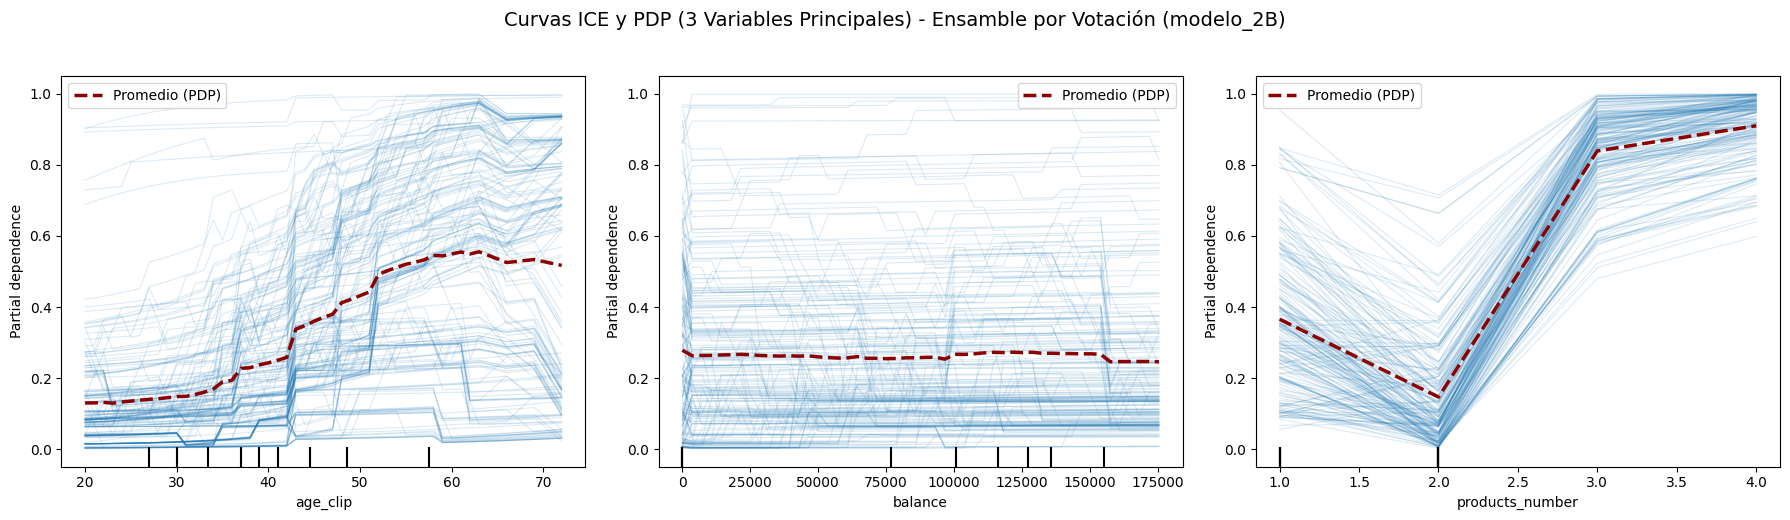

In [62]:
# 1. Muestra aleatoria convertida a tipo FLOAT para evitar el ValueError de enteros
X_sample_ens = X_test_orig[cols_originales].sample(n=200, random_state=42).astype(float).copy()

# 2. Selección de las 3 características principales
features_ice_ens = ["age_clip", "balance", "products_number"]

# 3. Crear figura con 3 subplots
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

# 4. Generar curvas ICE + PDP para las 3 variables
PartialDependenceDisplay.from_estimator(
    estimator=clasificador_ensamble,
    X=X_sample_ens,
    features=features_ice_ens,
    kind='both',                # Muestra ICE (líneas finas) y PDP (línea gruesa promedio)
    response_method='predict_proba',
    grid_resolution=50,
    ax=ax,
    ice_lines_kw={"alpha": 0.15, "color": "tab:blue", "linewidth": 0.8},
    pd_line_kw={"color": "darkred", "linewidth": 2.5, "label": "Promedio (PDP)"}
)

plt.suptitle("Curvas ICE y PDP (3 Variables Principales) - Ensamble por Votación (modelo_2B)", y=1.03, fontsize=14)
plt.tight_layout()
plt.show()

La edad es la variable con el efecto más marcado. Entre los 20 y los 30 años la probabilidad promedio de abandono está entre 13% y 15%; desde los 35 empieza a subir, con un salto entre los 42 y 43 años (de 26% a 34%), y llega a cerca de 55% entre los 60 y los 63 años, donde se estabiliza. El número de productos tiene un efecto no lineal: con un producto la probabilidad promedio es 36,6%, con dos baja a 14,7%, y con tres y cuatro sube a 83,9% y 91,0%. Este último salto debe leerse con cuidado, porque en la base solo 326 clientes tienen tres o más productos y la curva se construye asignándole tres o cuatro productos a clientes que en realidad tienen uno o dos; muestra lo que el modelo aprendió de un grupo pequeño, no que vender un tercer producto vaya a provocar el abandono. El saldo, en cambio, casi no mueve la predicción: la curva promedio se mantiene entre 24,6% y 27,9% en todo el rango, frente a una variación de más de 40 puntos en la edad. Para el negocio, el segundo producto es el punto de mayor fidelización y los clientes desde los 40 años merecen más atención.

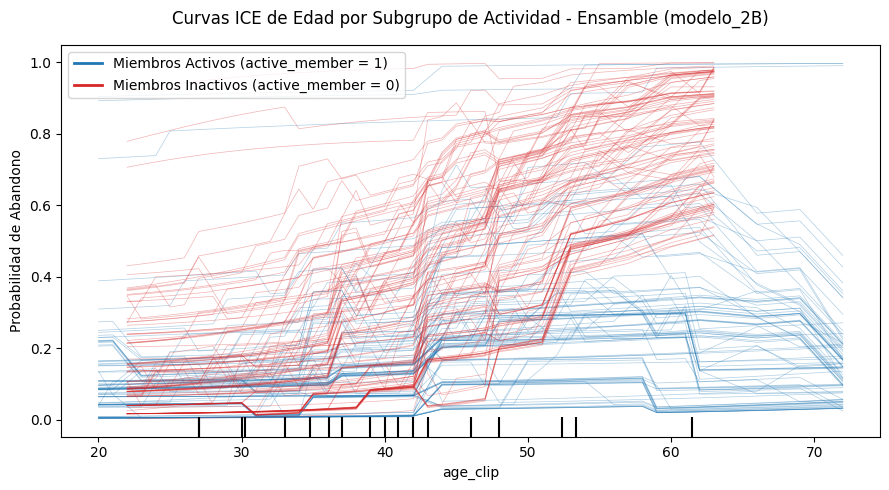

In [63]:
# 1. Definir muestra convertida a tipo FLOAT para evitar errores de tipo numérico
X_muestra_ens = (
    X_test_orig[cols_originales]
    .sample(n=200, random_state=42)
    .astype(float)
    .copy()
)
columna = "age_clip"

# 2. Separar subgrupos (Miembros activos vs. inactivos)
grupo_activo = X_muestra_ens["active_member"] == 1

# 3. Rejilla explícita mediante custom_values entre percentiles 5% y 95%
rejilla_edad = {
    columna: np.linspace(
        X_muestra_ens[columna].quantile(0.05),
        X_muestra_ens[columna].quantile(0.95),
        50,
    )
}

# 4. Crear figura y eje único
fig, ax = plt.subplots(figsize=(9, 5))

# 5. Trazado 1: Miembros activos en azul (pasando [ax] en lista para compartir eje)
PartialDependenceDisplay.from_estimator(
    estimator=clasificador_ensamble,
    X=X_muestra_ens[grupo_activo],
    features=[columna],
    kind="individual",
    custom_values=rejilla_edad,
    response_method="predict_proba",
    ax=[ax],
    ice_lines_kw={"color": "tab:blue", "alpha": 0.35},
)

# 6. Trazado 2: Miembros inactivos en rojo sobre el mismo eje
PartialDependenceDisplay.from_estimator(
    estimator=clasificador_ensamble,
    X=X_muestra_ens[~grupo_activo],
    features=[columna],
    kind="individual",
    custom_values=rejilla_edad,
    response_method="predict_proba",
    ax=[ax],
    ice_lines_kw={"color": "tab:red", "alpha": 0.35},
)

# 7. Leyenda explicativa y formato del gráfico
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            color="tab:blue",
            linewidth=2,
            label="Miembros Activos (active_member = 1)",
        ),
        Line2D(
            [],
            [],
            color="tab:red",
            linewidth=2,
            label="Miembros Inactivos (active_member = 0)",
        ),
    ],
    loc="upper left",
)

ax.set_title(
    "Curvas ICE de Edad por Subgrupo de Actividad - Ensamble (modelo_2B)",
    fontsize=12,
    pad=15,
)
ax.set_ylabel("Probabilidad de Abandono")
plt.tight_layout()
plt.show()

La curva de los inactivos termina en los 63 años porque en la muestra no hay clientes inactivos mayores, mientras que la de los activos llega hasta los 72. El efecto de la edad no es el mismo en los dos grupos. En los inactivos, la probabilidad promedio pasa de 16,7% a los 30 años a 55,4% a los 50, llega a 70% a los 55 y a 76,3% a los 60. En los activos sube mucho menos: de 12,7% a los 30 años a un máximo de 30,6% hacia los 55. Esto muestra una interacción entre edad y actividad: estar activo frena el aumento del riesgo con la edad, y el perfil más crítico es el cliente mayor e inactivo. Para la campaña, mantener activos a los clientes mayores de 40 parece más útil que una oferta genérica por edad, aunque el modelo muestra una asociación y no prueba que reactivarlos reduzca el abandono.

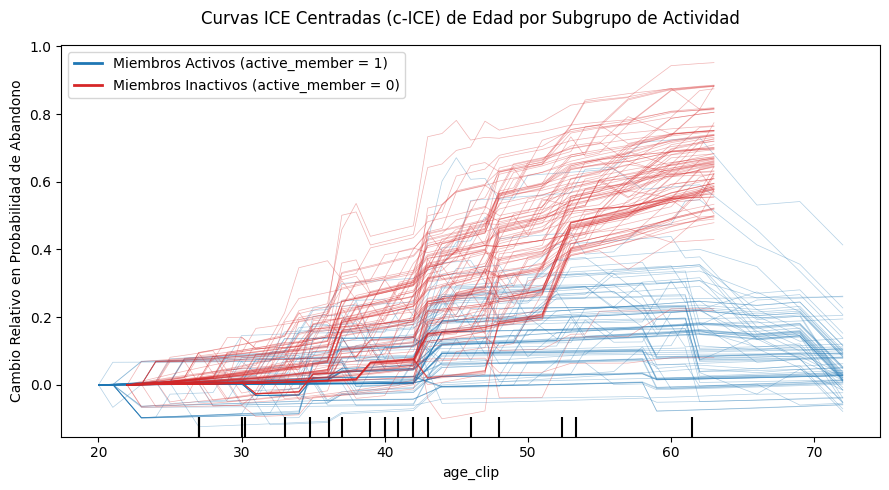

In [64]:
# 1. Muestra aleatoria convertida a FLOAT
X_muestra_ens = (
    X_test_orig[cols_originales]
    .sample(n=200, random_state=42)
    .astype(float)
    .copy()
)
columna = "age_clip"

# 2. Subgrupos por estado de actividad
grupo_activo = X_muestra_ens["active_member"] == 1

# 3. Rejilla explícita mediante custom_values (percentil 5% a 95%)
rejilla_edad = {
    columna: np.linspace(
        X_muestra_ens[columna].quantile(0.05),
        X_muestra_ens[columna].quantile(0.95),
        50,
    )
}

# 4. Crear figura y eje único
fig, ax = plt.subplots(figsize=(9, 5))

# 5. Trazado 1: Activos en azul (centrado en 0)
PartialDependenceDisplay.from_estimator(
    estimator=clasificador_ensamble,
    X=X_muestra_ens[grupo_activo],
    features=[columna],
    kind="individual",
    centered=True,  # Centra cada curva restándole su primer valor (c-ICE)
    custom_values=rejilla_edad,
    response_method="predict_proba",
    ax=[ax],
    ice_lines_kw={"color": "tab:blue", "alpha": 0.35},
)

# 6. Trazado 2: Inactivos en rojo sobre el mismo eje (centrado en 0)
PartialDependenceDisplay.from_estimator(
    estimator=clasificador_ensamble,
    X=X_muestra_ens[~grupo_activo],
    features=[columna],
    kind="individual",
    centered=True,  # Centra cada curva restándole su primer valor (c-ICE)
    custom_values=rejilla_edad,
    response_method="predict_proba",
    ax=[ax],
    ice_lines_kw={"color": "tab:red", "alpha": 0.35},
)

# 7. Formato, etiquetas y leyenda
ax.legend(
    handles=[
        Line2D(
            [],
            [],
            color="tab:blue",
            linewidth=2,
            label="Miembros Activos (active_member = 1)",
        ),
        Line2D(
            [],
            [],
            color="tab:red",
            linewidth=2,
            label="Miembros Inactivos (active_member = 0)",
        ),
    ],
    loc="upper left",
)

ax.set_title(
    "Curvas ICE Centradas (c-ICE) de Edad por Subgrupo de Actividad",
    fontsize=12,
    pad=15,
)
ax.set_ylabel("Cambio Relativo en Probabilidad de Abandono")
plt.tight_layout()
plt.show()

Al centrar las curvas para que todas partan de cero, se ve solo cuánto cambia el riesgo de cada cliente al envejecer, sin importar su nivel inicial. Las curvas de los inactivos se abren mucho más que las de los activos, así que la inactividad no solo parte de un riesgo más alto, sino que hace que el riesgo crezca más rápido con la edad.

## LIME

Probabilidad Real del Modelo (Clase 1): 0.2530
Predicción del Modelo Sustituto (local_pred): 0.2518
Fidelidad Local (R² score): 0.1137


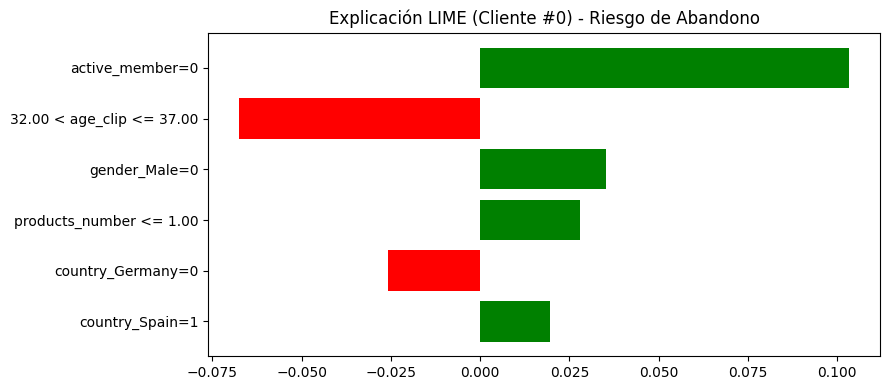

In [65]:
# 1. Posiciones de variables categóricas/binarias
indices_categoricos = [
    cols_originales.index("credit_card"),
    cols_originales.index("active_member"),
    cols_originales.index("country_Germany"),
    cols_originales.index("country_Spain"),
    cols_originales.index("gender_Male")
]

# 2. Crear el explicador
explicador_lime = LimeTabularExplainer(
    training_data=X_train_orig_imp[cols_originales].to_numpy(),
    feature_names=cols_originales,
    class_names=["No Abandono", "Abandono"],
    mode="classification",
    categorical_features=indices_categoricos,
    random_state=42
)

# 3. Seleccionar el cliente
cliente_idx = 0
cliente_x = X_test_orig_imp[cols_originales].iloc[cliente_idx].to_numpy()

# 4. Generar la explicación forzando el cálculo de la Clase 1 (Abandono)
explicacion = explicador_lime.explain_instance(
    data_row=cliente_x,
    predict_fn=clasificador_ensamble.predict_proba,
    num_features=6,
    labels=(1,),  # Cambiado de top_labels=1 a labels=(1,)
    num_samples=5000
)

# 5. Métricas de fidelidad
prob_real = clasificador_ensamble.predict_proba(cliente_x.reshape(1, -1))[0, 1]
print(f"Probabilidad Real del Modelo (Clase 1): {prob_real:.4f}")
print(f"Predicción del Modelo Sustituto (local_pred): {explicacion.local_pred[0]:.4f}")
print(f"Fidelidad Local (R² score): {explicacion.score:.4f}")

# 6. Gráfico explicativo para la Clase 1
fig = explicacion.as_pyplot_figure(label=1)
fig.set_size_inches(9, 4)
plt.title(f"Explicación LIME (Cliente #{cliente_idx}) - Riesgo de Abandono", fontsize=12)
plt.tight_layout()
plt.show()


=== Verdadero Positivo (Abandono bien detectado) (Cliente index #10) ===
Probabilidad Real del Modelo: 0.6464
Fidelidad Local (R²): 0.2908


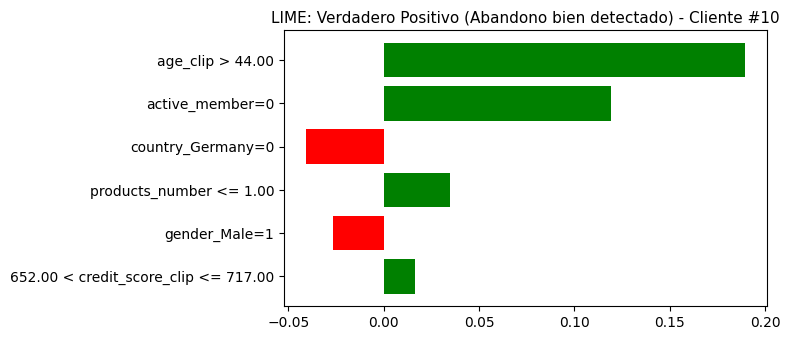


=== Falso Negativo (Abandono NO detectado) (Cliente index #18) ===
Probabilidad Real del Modelo: 0.3553
Fidelidad Local (R²): 0.1121


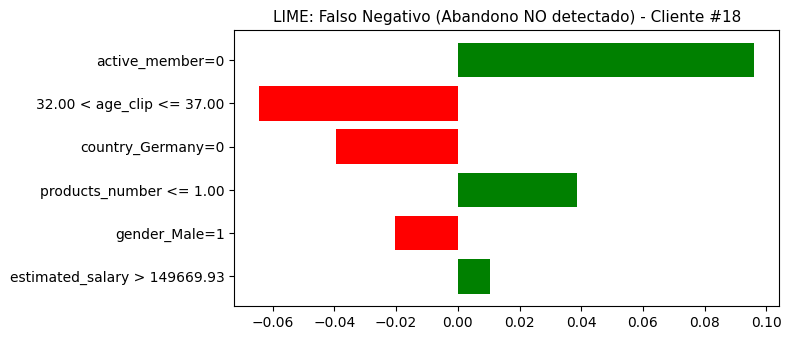


=== Falso Positivo (Falsa alarma) (Cliente index #7) ===
Probabilidad Real del Modelo: 0.5413
Fidelidad Local (R²): 0.1078


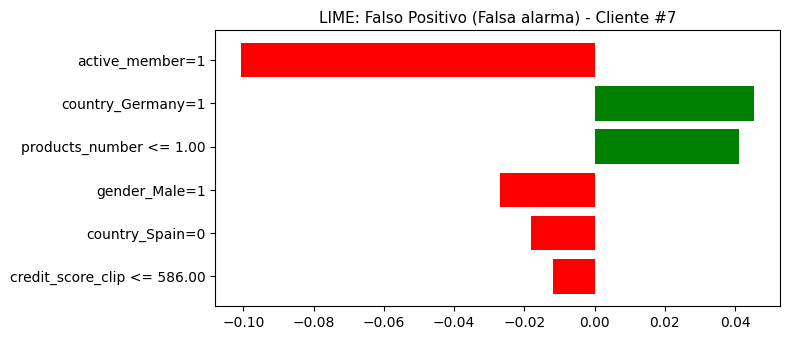

In [66]:
# 1. Obtener predicciones duras y probabilidades del ensamble sobre el test set
y_prob = clasificador_ensamble.predict_proba(X_test_orig_imp[cols_originales])[:, 1]
y_pred = (y_prob >= 0.5).astype(int)
y_real = y_test.values

# 2. Identificar índices de cada caso
idx_vp = np.where((y_real == 1) & (y_pred == 1))[0][0]  # Verdadero Positivo
idx_fn = np.where((y_real == 1) & (y_pred == 0))[0][0]  # Falso Negativo
idx_fp = np.where((y_real == 0) & (y_pred == 1))[0][0]  # Falso Positivo

casos = [
    ("Verdadero Positivo (Abandono bien detectado)", idx_vp),
    ("Falso Negativo (Abandono NO detectado)", idx_fn),
    ("Falso Positivo (Falsa alarma)", idx_fp)
]

# 3. Generar gráficos LIME para los 3 casos
for titulo, idx in casos:
    cliente_x = X_test_orig_imp[cols_originales].iloc[idx].to_numpy()
    
    exp = explicador_lime.explain_instance(
        data_row=cliente_x,
        predict_fn=clasificador_ensamble.predict_proba,
        num_features=6,
        labels=(1,),
        num_samples=5000
    )
    
    print(f"\n=== {titulo} (Cliente index #{idx}) ===")
    print(f"Probabilidad Real del Modelo: {y_prob[idx]:.4f}")
    print(f"Fidelidad Local (R²): {exp.score:.4f}")
    
    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(8, 3.5)
    plt.title(f"LIME: {titulo} - Cliente #{idx}", fontsize=11)
    plt.tight_layout()
    plt.show()

En el verdadero positivo (cliente 10, probabilidad de 64,6%), LIME atribuye el riesgo sobre todo a la edad mayor de 44 años y a la inactividad, con un aporte menor de tener un solo producto. En el falso negativo (cliente 18, 35,5%), el cliente es inactivo y tiene un solo producto, lo que empuja hacia el abandono, pero su edad entre 32 y 37 años y no vivir en Alemania pesan en sentido contrario y dejan la probabilidad por debajo de 0,5; es un cliente con un riesgo real que el modelo subestima por su edad. En el falso positivo (cliente 7, 54,1%), vivir en Alemania y tener un solo producto empujan la predicción hacia el abandono, aunque ser cliente activo la reduce. Esto no es un sesgo del modelo contra Alemania: en la base, los clientes alemanes abandonan el 32,4% de las veces, el doble que en los otros países, y el modelo refleja ese patrón; el error aparece porque este cliente es activo y no se comporta como el promedio de su país. En los tres casos la fidelidad local es baja (R² entre 0,11 y 0,29), así que estas explicaciones muestran tendencias y no el peso exacto de cada variable.


=== Cliente A (Index #10) ===
Probabilidad Real del Modelo: 0.6464
Fidelidad Local (R²): 0.3324


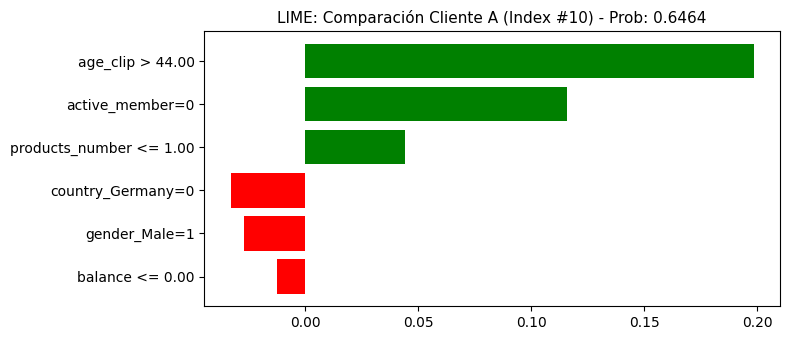


=== Cliente B (Index #23) ===
Probabilidad Real del Modelo: 0.6096
Fidelidad Local (R²): 0.2921


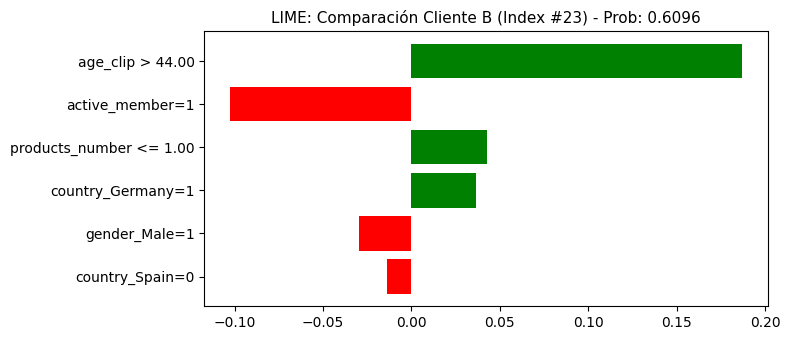

In [67]:
# 1. Encontrar dos clientes con probabilidad de abandono similar (ej. entre 0.55 y 0.65)
indices_riesgo = np.where((y_prob >= 0.55) & (y_prob <= 0.65))[0]

# Tomar los dos primeros clientes encontrados en ese rango
idx_a = indices_riesgo[0]
idx_b = indices_riesgo[1]

casos_p6 = [
    (f"Cliente A (Index #{idx_a})", idx_a),
    (f"Cliente B (Index #{idx_b})", idx_b)
]

# 2. Generar explicaciones LIME comparativas
for etiqueta, idx in casos_p6:
    cliente_x = X_test_orig_imp[cols_originales].iloc[idx].to_numpy()
    
    exp = explicador_lime.explain_instance(
        data_row=cliente_x,
        predict_fn=clasificador_ensamble.predict_proba,
        num_features=6,
        labels=(1,),
        num_samples=5000
    )
    
    print(f"\n=== {etiqueta} ===")
    print(f"Probabilidad Real del Modelo: {y_prob[idx]:.4f}")
    print(f"Fidelidad Local (R²): {exp.score:.4f}")
    
    fig = exp.as_pyplot_figure(label=1)
    fig.set_size_inches(8, 3.5)
    plt.title(f"LIME: Comparación {etiqueta} - Prob: {y_prob[idx]:.4f}", fontsize=11)
    plt.tight_layout()
    plt.show()

Los clientes 10 y 23 tienen probabilidades parecidas (64,6% y 61,0%), pero llegan a ellas por caminos distintos. El cliente 10 es un hombre de 47 años, inactivo, de Francia, con un solo producto y saldo en cero, y su riesgo viene de la combinación de edad e inactividad. El cliente 23 tiene 55 años, es activo y vive en Alemania, con un solo producto; su actividad le resta riesgo, pero la edad y el país lo compensan. Para el banco esto significa que dos clientes con la misma probabilidad pueden necesitar ofertas distintas: al primero le sirve una campaña de reactivación, mientras que en el segundo la actividad ya existe y el foco debería estar en profundizar la relación con un segundo producto.

### Conclusion LIME

Para el asesor comercial, las explicaciones de LIME se traducen en el tipo de oferta, no en un mensaje sobre el modelo. Si el riesgo viene de la inactividad y de tener un solo producto, tiene sentido una oferta de reactivación o de un segundo producto con beneficios, porque dos productos es el punto de menor abandono. Si el riesgo viene de la edad o del país, la oferta debería enfocarse en servicio y acompañamiento, sin mencionarle al cliente esas características. Estas explicaciones se deben usar con cuidado: la fidelidad local es baja (R² entre 0,11 y 0,33), así que muestran tendencias y no certezas; describen lo que el modelo aprendió y no la razón real por la que un cliente se va; y como LIME genera muestras al azar, el peso de cada barra puede variar un poco entre ejecuciones.

## SHAP

In [68]:
# 1. Definir muestra de fondo (100) y muestra de prueba (300) con las 11 variables originales
X_fondo = X_train_orig_imp[cols_originales].sample(100, random_state=42)
X_muestra = X_test_orig_imp[cols_originales].sample(300, random_state=42)

# 2. Explicador Agnóstico sobre la función de predicción del ensamble
explicador_ensamble = shap.Explainer(predecir_abandono, X_fondo, seed=42)
valores_ensamble = explicador_ensamble(X_muestra)

# 3. Comprobación de Aditividad y Predicción Real de clasificador_ensamble
i = 0
base_val = valores_ensamble.base_values[i]
suma_shap = base_val + valores_ensamble.values[i].sum()
pred_real = clasificador_ensamble.predict_proba(X_muestra.iloc[[i]])[0, 1]

print(f"Valor Base del Ensamble: {base_val:.4f}")
print(f"Suma SHAP (Base + Atribuciones): {suma_shap:.4f}")
print(f"Predicción Real (clasificador_ensamble): {pred_real:.4f}")
print(f"¿Aditividad exactamenete igual?: {np.isclose(suma_shap, pred_real)}")

PermutationExplainer explainer: 301it [03:09,  1.51it/s]                         

Valor Base del Ensamble: 0.2199
Suma SHAP (Base + Atribuciones): 0.8500
Predicción Real (clasificador_ensamble): 0.8500
¿Aditividad exactamenete igual?: True


El valor base es la probabilidad de abandono promedio que el ensamble asigna a la muestra de referencia de 100 clientes de entrenamiento: 0,2199, es decir, 22%. Es el punto de partida de cada explicación y queda cerca de la tasa real de abandono de la base (20,4%). Cada valor SHAP indica cuánto mueve una característica del cliente la probabilidad respecto a ese promedio: un valor positivo la sube y es un factor de riesgo, y uno negativo la baja y es un factor de permanencia. Como el modelo explicado devuelve probabilidades, los valores SHAP están en puntos de probabilidad, y el valor base más todos los aportes da exactamente la predicción del cliente, como se comprueba en la celda.


=== SHAP Waterfall: Verdadero Positivo (Abandono bien detectado) (Cliente #10) ===
Valor Base (E[f(X)]): 0.2199
Suma (Base + SHAP):   0.6464
Predicción Real:      0.6464
¿Aditividad exacta?:  True


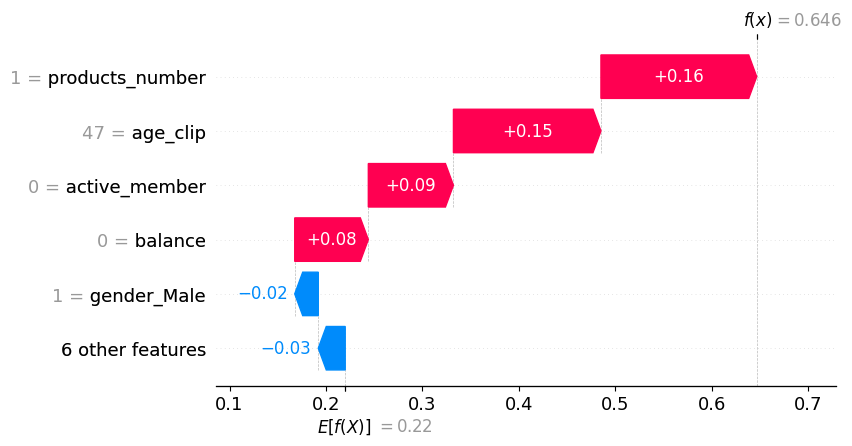


=== SHAP Waterfall: Falso Negativo (Abandono NO detectado) (Cliente #18) ===
Valor Base (E[f(X)]): 0.2199
Suma (Base + SHAP):   0.3553
Predicción Real:      0.3553
¿Aditividad exacta?:  True


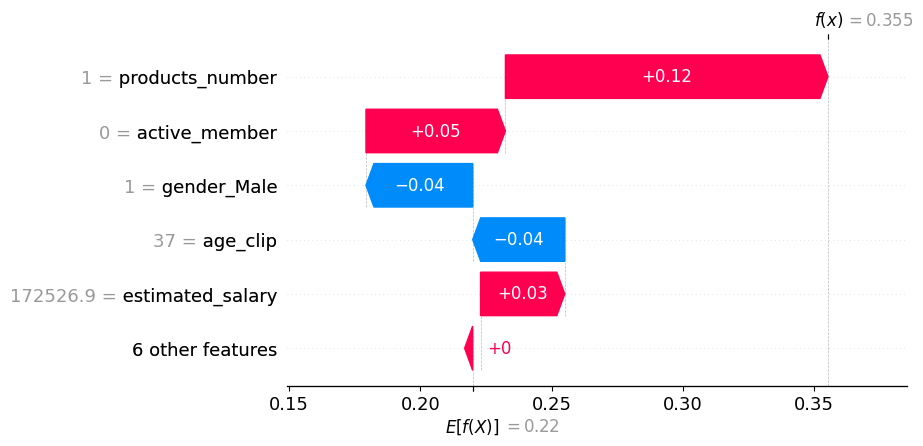


=== SHAP Waterfall: Falso Positivo (Falsa alarma) (Cliente #7) ===
Valor Base (E[f(X)]): 0.2199
Suma (Base + SHAP):   0.5413
Predicción Real:      0.5413
¿Aditividad exacta?:  True


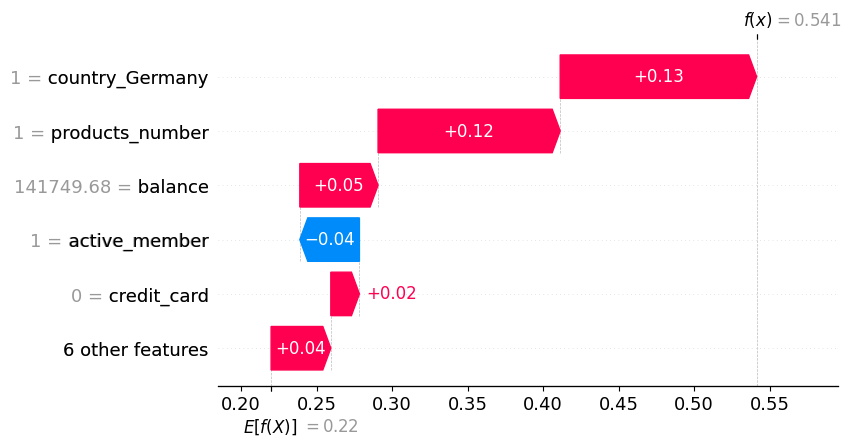

In [69]:
# 1. Definir los clientes auditados en LIME
casos_lime = [
    ("Verdadero Positivo (Abandono bien detectado)", idx_vp),
    ("Falso Negativo (Abandono NO detectado)", idx_fn),
    ("Falso Positivo (Falsa alarma)", idx_fp)
]

# 2. Extraer los datos de los 3 clientes específicos
X_casos_3 = X_test_orig_imp[cols_originales].iloc[[idx_vp, idx_fn, idx_fp]]

# 3. Calcular los valores SHAP exactos para los 3 casos
valores_casos_3 = explicador_ensamble(X_casos_3)

# 4. Generar el gráfico de cascada y comprobar aditividad para cada cliente
for i, (titulo, idx) in enumerate(casos_lime):
    base_v = valores_casos_3.base_values[i]
    suma_v = base_v + valores_casos_3.values[i].sum()
    pred_v = predecir_abandono(X_casos_3.iloc[[i]])[0]
    
    print(f"\n=== SHAP Waterfall: {titulo} (Cliente #{idx}) ===")
    print(f"Valor Base (E[f(X)]): {base_v:.4f}")
    print(f"Suma (Base + SHAP):   {suma_v:.4f}")
    print(f"Predicción Real:      {pred_v:.4f}")
    print(f"¿Aditividad exacta?:  {np.isclose(suma_v, pred_v)}")
    
    # Renderizar gráfico de cascada
    shap.plots.waterfall(valores_casos_3[i], max_display=6)

En los tres clientes, el valor base más la suma de los aportes reproduce exactamente la predicción. En el verdadero positivo (cliente 10, 64,6%), los mayores aportes al riesgo vienen de tener un solo producto (+0,161), la edad de 47 años (+0,153), la inactividad (+0,088) y el saldo en cero (+0,076). En el falso negativo (cliente 18, 35,5%), tener un solo producto (+0,123) y la inactividad (+0,053) suben el riesgo, pero ser hombre (−0,041) y tener 37 años (−0,035) lo bajan y lo dejan por debajo de 0,5. En el falso positivo (cliente 7, 54,1%), vivir en Alemania (+0,130) y tener un solo producto (+0,121) pesan más que la protección de ser cliente activo (−0,039). SHAP y LIME coinciden en las variables que importan: número de productos, edad, actividad y país. Difieren en el orden y el peso: en el cliente 10, LIME pone primero la edad y SHAP el número de productos, y en el cliente 7 LIME le da a la actividad un peso protector de −0,101, mientras SHAP le da −0,039. La diferencia se explica por el método: LIME aproxima el modelo con una regresión lineal sobre rangos de las variables y con baja fidelidad, mientras que SHAP reparte la predicción exacta entre las variables a partir de su valor real. Un punto a revisar desde el negocio es el saldo en cero del cliente 10, que según SHAP suma riesgo, cuando en la base los clientes de Francia con saldo en cero abandonan menos que los que tienen saldo (14,0% frente a 18,1%); es un efecto que el modelo aprende en combinación con otras variables y no debería usarse como regla comercial.

=== Diagrama de fuerza: Verdadero Positivo (Abandono bien detectado) (Cliente #10) ===


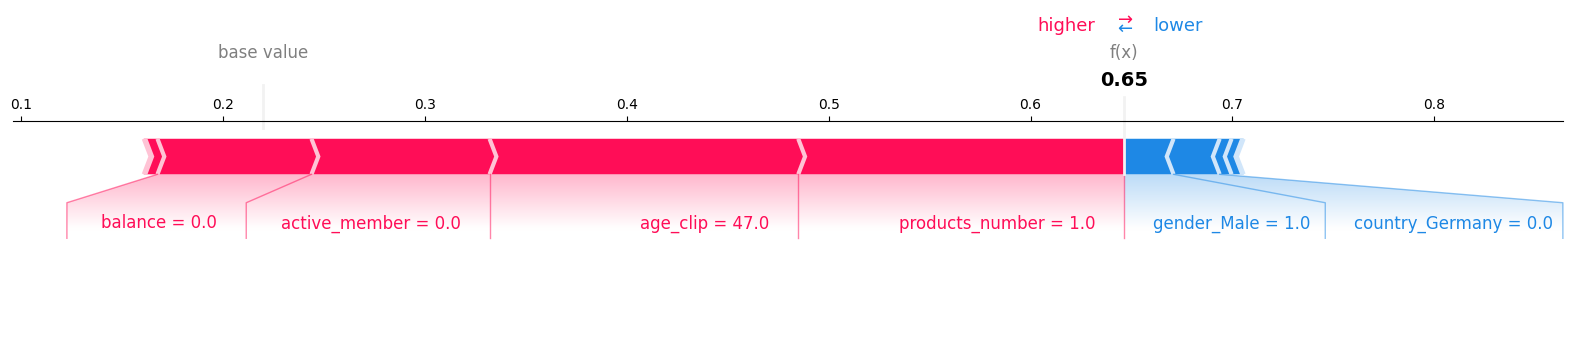

=== Diagrama de fuerza: Falso Negativo (Abandono NO detectado) (Cliente #18) ===


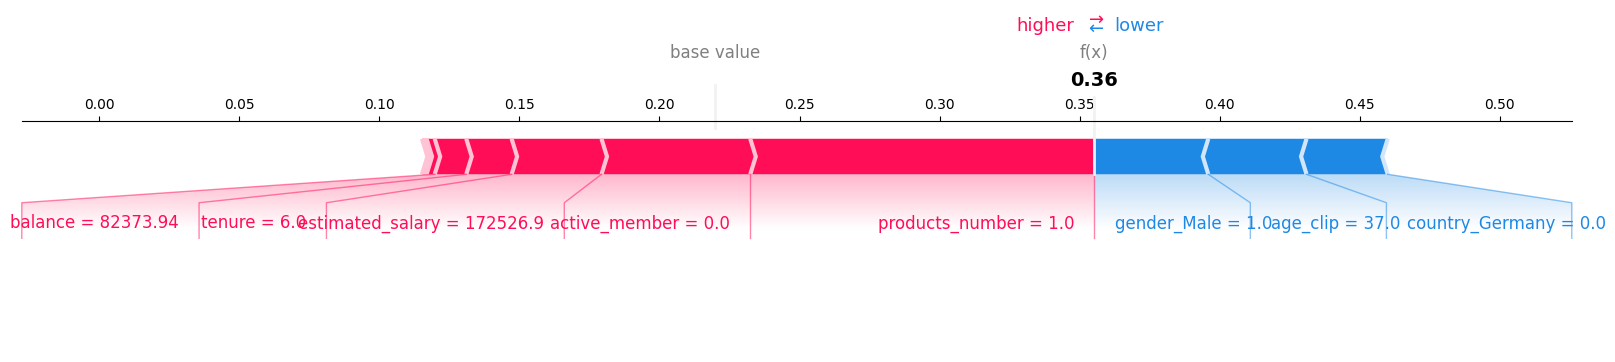

=== Diagrama de fuerza: Falso Positivo (Falsa alarma) (Cliente #7) ===


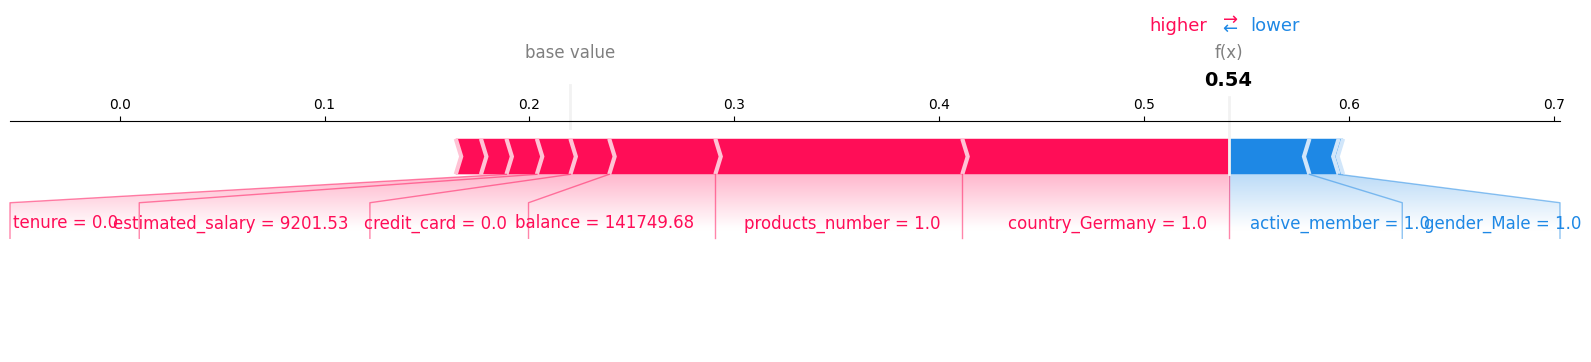

In [70]:
for i, (titulo, idx) in enumerate(casos_lime):
    print(f"=== Diagrama de fuerza: {titulo} (Cliente #{idx}) ===")
    shap.force_plot(
        base_value=valores_casos_3.base_values[i],
        shap_values=valores_casos_3.values[i],
        features=X_casos_3.iloc[i].round(2),
        feature_names=cols_originales,
        matplotlib=True,
        show=False)
    plt.show()

Los diagramas de fuerza muestran lo mismo que las cascadas en una sola barra: en rojo las características que empujan la probabilidad hacia el abandono y en azul las que la alejan, partiendo del valor base del modelo.

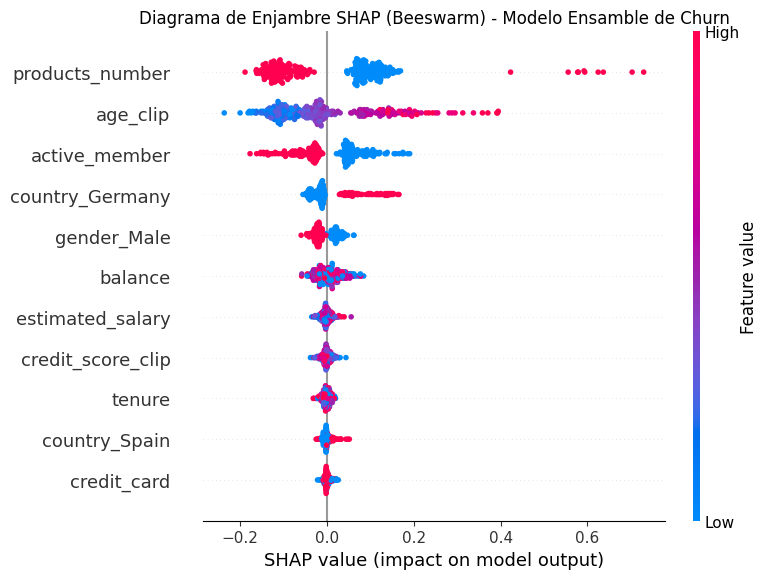

In [71]:
# Graficar el diagrama de enjambre (Beeswarm Plot) para los 300 clientes del ensamble
plt.figure(figsize=(10, 6))
shap.plots.beeswarm(valores_ensamble, max_display=11, show=False)
plt.title(
    "Diagrama de Enjambre SHAP (Beeswarm) - Modelo Ensamble de Churn",
    fontsize=12,
)
plt.tight_layout()
plt.show()

En los 300 clientes de la muestra, las variables con mayor impacto promedio son el número de productos (0,119 puntos de probabilidad), la edad (0,096), la actividad (0,061) y vivir en Alemania (0,038), seguidas de lejos por el género y el saldo (0,022 cada una); el resto aporta menos de 0,01. La edad alta y vivir en Alemania suben el riesgo, y ser cliente activo lo baja. El número de productos tiene el mismo comportamiento no lineal del gráfico ICE: dos productos bajan el riesgo, uno lo sube y tres o cuatro lo suben con mucha fuerza. Que el género aparezca entre las variables relevantes merece atención: aunque en la base las mujeres abandonan más (25,1% frente a 16,5%), usar el género para decidir a quién se le hace una oferta puede ser discriminatorio, así que el banco no debería diferenciar sus campañas por esa variable.

In [72]:
# 1. Definir los datos de comparación entre las tres técnicas
datos_comparacion = {
    "Técnica": [
        "ICE (Individual Conditional Expectation)",
        "LIME (Local Interpretable Model-agnostic Explanations)",
        "SHAP (SHapley Additive exPlanations)",
    ],
    "Alcance": [
        "Local (Acumulable a Global vía PDP)",
        "Local",
        "Local y Global",
    ],
    "Pregunta que responde": [
        (
            "¿Cómo cambia la predicción de un cliente si modificamos una sola"
            " variable dejando las demás constantes?"
        ),
        (
            "¿Qué variables y en qué rangos influyen en la decisión del modelo"
            " en la vecindad inmediata de un cliente?"
        ),
        (
            "¿Cuánto aporta cada variable para alejar la predicción individual"
            " respecto al promedio base del modelo?"
        ),
    ],
    "Costo de Cálculo": [
        "Moderado",
        "Moderado",
        "Alto (Explicador Agnóstico) / Bajo (TreeExplainer)",
    ],
    "Estabilidad": [
        "Alta (Determinística para la muestra evaluada)",
        (
            "Baja - Moderada (Sensible al muestreo estocástico de"
            " perturbaciones)"
        ),
        (
            "Muy Alta (Fundamentada en teoría de juegos y propiedad aditiva"
            " exacta)"
        ),
    ],
    "Limitaciones": [
        (
            "Asume independencia entre variables; genera combinaciones no"
            " realistas si existen características correlacionadas."
        ),
        (
            "Fidelidad local reducida (R² bajo entre 0.11 y 0.33 en bordes no"
            " lineales); la discretización oculta efectos continuos."
        ),
        (
            "Computacionalmente costoso en explicadores agnósticos sobre"
            " muestras masivas; sensible a la muestra de fondo elegida."
        ),
    ],
}

# 2. Crear el DataFrame
df_comparacion = pd.DataFrame(datos_comparacion)

# 3. Formatear y mostrar la tabla de forma estética en Jupyter Notebook / Google Colab
html_tabla = df_comparacion.to_html(index=False).replace(
    "<th>",
    '<th style="text-align: center; background-color: #1f77b4; color:'
    ' white;">',
)
display(HTML(html_tabla))

Técnica,Alcance,Pregunta que responde,Costo de Cálculo,Estabilidad,Limitaciones
ICE (Individual Conditional Expectation),Local (Acumulable a Global vía PDP),¿Cómo cambia la predicción de un cliente si modificamos una sola variable dejando las demás constantes?,Moderado,Alta (Determinística para la muestra evaluada),Asume independencia entre variables; genera combinaciones no realistas si existen características correlacionadas.
LIME (Local Interpretable Model-agnostic Explanations),Local,¿Qué variables y en qué rangos influyen en la decisión del modelo en la vecindad inmediata de un cliente?,Moderado,Baja - Moderada (Sensible al muestreo estocástico de perturbaciones),Fidelidad local reducida (R² bajo entre 0.11 y 0.33 en bordes no lineales); la discretización oculta efectos continuos.
SHAP (SHapley Additive exPlanations),Local y Global,¿Cuánto aporta cada variable para alejar la predicción individual respecto al promedio base del modelo?,Alto (Explicador Agnóstico) / Bajo (TreeExplainer),Muy Alta (Fundamentada en teoría de juegos y propiedad aditiva exacta),Computacionalmente costoso en explicadores agnósticos sobre muestras masivas; sensible a la muestra de fondo elegida.


## Conclusion interpretabilidad

Las tres técnicas coinciden en que el número de productos, la edad, la actividad y el país son las variables que más pesan en el riesgo de abandono. Lo que cambia es la pregunta que responde cada una: ICE muestra cómo cambia la predicción al mover una sola variable, LIME explica un cliente con una aproximación lineal local de baja fidelidad, y SHAP reparte de forma exacta la predicción de cada cliente entre sus características. Para explicarle al banco el riesgo de un cliente, la mejor opción es la cascada de SHAP, porque parte del promedio (22%) y muestra con cifras qué características suben o bajan el riesgo de esa persona. Ninguna de las tres técnicas demuestra causalidad: todas describen asociaciones que el modelo aprendió de los datos. Que tener un solo producto o vivir en Alemania aumente el riesgo estimado no significa que cambiar esas condiciones vaya a retener al cliente; para saberlo habría que probarlo, por ejemplo con una campaña piloto que compare clientes con y sin oferta.

# Generación de Valor y Caso de Negocio
(5)

## Supuestos del caso de negocio

El caso es un banco colombiano con 20.000 clientes, una tasa de abandono anual del 15% y una oferta que retiene al 30% de los clientes que iban a irse, pagada a todos los contactados. El ingreso anual por cliente se fija en COP 700.000, punto medio del rango del enunciado. La oferta cuesta el 21,5% de ese ingreso, la misma proporción entre costo y valor anual del cliente de la práctica de clase (222,73 € sobre 1.038,15 €), más un SMS de US$0,0592 (tarifa de Twilio para Colombia) convertido con la TRM de 3.237,83 del 7 de noviembre de 2026 (Banco de la República). La inversión sigue la fórmula del curso, recursos por costo: un científico y un ingeniero de datos durante 3 meses, con salarios de COP 11 y 13 millones (Guía Salarial de Tecnología Colombia 2025, Michael Page); como no incluye prestaciones ni infraestructura, los COP 72 millones son un piso.

El beneficio de retener a un cliente se mide como su ingreso de un año. La oferta es un pago único y lo que se puede sostener con los datos es que evita la salida de ese año, así que todo el análisis queda en términos anuales. Es un supuesto conservador: con un abandono constante de 15%, un cliente que se queda permanece en promedio 6,7 años, y ese riesgo no cambia con la antigüedad (el abandono por años de antigüedad se mantiene entre 17% y 23% sin tendencia y la antigüedad es de las variables con menor efecto en el análisis SHAP del ensamble). Sin embargo, un cliente que estaba por irse puede volver a intentarlo pronto y no hay datos de cuánto se queda después de una oferta, por lo que ese valor futuro no se cuenta.

Los escenarios varían el ingreso anual dentro del rango del enunciado (COP 500.000, 700.000 y 900.000) y mantienen fija la oferta de COP 150.500, porque la oferta la define el banco y lo incierto es el ingreso de los clientes que se retienen.

In [73]:
CLIENTES_BANCO = 20_000
TASA_ABANDONO = 0.15
EFECTIVIDAD = 0.30
INGRESO_ANUAL = 700_000
ESCENARIOS_INGRESO = {"Pesimista": 500_000, "Base": 700_000, "Optimista": 900_000}
COSTO_OFERTA_PCT = 0.215
TRM = 3_237.83
COSTO_SMS = 0.0592 * TRM
SALARIOS_EQUIPO = 11_000_000 + 13_000_000
MESES_PROYECTO = 3
INVERSION = SALARIOS_EQUIPO * MESES_PROYECTO

costo_contacto = COSTO_OFERTA_PCT * INGRESO_ANUAL + COSTO_SMS
valor_base = INGRESO_ANUAL

print(f"Costo por cliente contactado: {costo_contacto:,.0f} COP (oferta {COSTO_OFERTA_PCT * INGRESO_ANUAL:,.0f} + SMS {COSTO_SMS:,.0f})")
print(f"Inversión en el modelo: {INVERSION:,.0f} COP")
pd.DataFrame({
    "Ingreso anual del cliente retenido (COP)": list(ESCENARIOS_INGRESO.values()),
    "Ingreso recuperado por retención (COP)": [EFECTIVIDAD * v for v in ESCENARIOS_INGRESO.values()],
    "Precisión de equilibrio": [costo_contacto / (EFECTIVIDAD * v) for v in ESCENARIOS_INGRESO.values()]},
    index=list(ESCENARIOS_INGRESO.keys())).round(4)

Costo por cliente contactado: 150,692 COP (oferta 150,500 + SMS 192)
Inversión en el modelo: 72,000,000 COP


,Ingreso anual del cliente retenido (COP),Ingreso recuperado por retención (COP),Precisión de equilibrio
Pesimista,500000,150000.0,1.0046
Base,700000,210000.0,0.7176
Optimista,900000,270000.0,0.5581


Retener a un cliente que se iba recupera el 30% de su ingreso anual, COP 210.000 en el escenario base, y cada contacto cuesta COP 150.692. Para no perder dinero, el 71,8% de los contactados tendría que estar realmente por irse. En el escenario optimista esa precisión mínima baja a 55,8%, y en el pesimista sube a 100,5%: con clientes de COP 500.000 de ingreso, ni un modelo perfecto cubriría el costo de la oferta.

## Matriz de costo-beneficio y valor esperado (Provost)

La matriz compara contra no usar el modelo. Un acierto vale el 30% del valor del cliente menos el costo del contacto, una falsa alarma cuesta el contacto y los clientes no contactados valen cero. Como el banco pierde el 15% de sus clientes y la base de entrenamiento el 20,4%, el valor esperado separa la tasa de abandono de la capacidad del modelo (fórmula de Provost), para que el resultado corresponda al banco del caso.

In [74]:
def evaluar_campania(y, prob, umbral, valor_cliente, costo):
    pred = prob >= umbral
    tpr = pred[y == 1].mean()
    fpr = pred[y == 0].mean()
    contactados = TASA_ABANDONO * tpr + (1 - TASA_ABANDONO) * fpr
    return {"Umbral": umbral, "Recall": tpr, "Tasa de falsas alarmas": fpr,
            "Precisión en el banco": TASA_ABANDONO * tpr / contactados if contactados > 0 else np.nan,
            "Ganancia por predicción": TASA_ABANDONO * tpr * (EFECTIVIDAD * valor_cliente - costo) - (1 - TASA_ABANDONO) * fpr * costo}

prob_val = {"Modelo 1A (Red Original)": modelo_1A.predict(X_val_orig_esc, verbose=0).ravel(),
            "Modelo 2B (Ensamble)": modelo_2B.predict_proba(X_val_amp_esc)[:, 1]}
prob_test = {nombre: probabilidades_test[nombre] for nombre in prob_val}

print(f"Valor de un verdadero positivo: {EFECTIVIDAD * valor_base - costo_contacto:,.0f} COP")
print(f"Valor de un falso positivo: {-costo_contacto:,.0f} COP")
print(f"Valor de un falso negativo y de un verdadero negativo: 0 COP")

pd.DataFrame([evaluar_campania(y_test.values, prob, 0.5, valor_base, costo_contacto) | {"Modelo": nombre}
              for nombre, prob in prob_test.items()]).set_index("Modelo").round(4)

Valor de un verdadero positivo: 59,308 COP
Valor de un falso positivo: -150,692 COP
Valor de un falso negativo y de un verdadero negativo: 0 COP


,Umbral,Recall,Tasa de falsas alarmas,Precisión en el banco,Ganancia por predicción
Modelo,,,,,
Modelo 1A (Red Original),0.5,0.4054,0.0282,0.7169,-11.7160
Modelo 2B (Ensamble),0.5,0.5160,0.0578,0.6119,-2807.2178


Cada acierto deja apenas COP 59.308 y cada falsa alarma cuesta COP 150.692, dos veces y media más. Con el umbral de 0,5 y la tasa de abandono del banco, la precisión es 71,7% en la red y 61,2% en el ensamble (78,6% y 69,5% en la base europea). La red queda prácticamente en el punto de equilibrio, con una pérdida de COP 12 por cliente evaluado, y el ensamble pierde COP 2.807 porque detecta más clientes que se van (51,6% frente a 40,5%) a costa de más falsas alarmas.

## Fórmula simplificada y precisión de equilibrio

La fórmula simplificada del curso aplica la misma lógica a cada cliente contactado: lo que se gana al acertar (el 30% del valor menos el contacto) menos la proporción de errores por lo que se deja de ganar al fallar (el 30% del valor). La exactitud de la fórmula es aquí la precisión entre los contactados, y de ella sale la precisión de equilibrio: uno menos la ganancia de acertar sobre el costo del error.

In [75]:
a = EFECTIVIDAD * valor_base - costo_contacto
e = EFECTIVIDAD * valor_base
print(f"Ganancia si el contacto acierta (a): {a:,.0f} COP")
print(f"Costo de un error frente a acertar (e): {e:,.0f} COP")
print(f"Precisión de equilibrio Pe = 1 - a / e: {1 - a / e:.2%}")

simplificada = []
for nombre, prob in prob_test.items():
    r = evaluar_campania(y_test.values, prob, 0.5, valor_base, costo_contacto)
    precision = r["Precisión en el banco"]
    simplificada.append({"Modelo": nombre, "Precisión en el banco": precision,
                         "Ganancia por contacto (COP)": a - (1 - precision) * e,
                         "Supera la precisión de equilibrio": "Sí" if precision > 1 - a / e else "No"})
pd.DataFrame(simplificada).set_index("Modelo").round(4)

Ganancia si el contacto acierta (a): 59,308 COP
Costo de un error frente a acertar (e): 210,000 COP
Precisión de equilibrio Pe = 1 - a / e: 71.76%


,Precisión en el banco,Ganancia por contacto (COP),Supera la precisión de equilibrio
Modelo,,,
Modelo 1A (Red Original),0.7169,-138.1242,No
Modelo 2B (Ensamble),0.6119,-22194.0165,No


Con el umbral de 0,5 ninguno de los dos modelos supera la precisión de equilibrio de 71,76%: cada contacto pierde COP 138 con la red y COP 22.194 con el ensamble. La lógica se invierte frente a un caso con márgenes amplios: como un error cuesta más de lo que deja un acierto, conviene contactar a menos clientes y solo a los de mayor riesgo, y eso se logra subiendo el umbral.

## Umbral de decisión

El umbral de 0,5 no responde al negocio. Como una falsa alarma cuesta dos veces y media lo que deja una retención, solo conviene contactar a clientes con una probabilidad de irse muy alta. El umbral se elige en validación, incluyendo la opción de no contactar a nadie (umbral de 1,0), y el resultado se reporta en prueba.

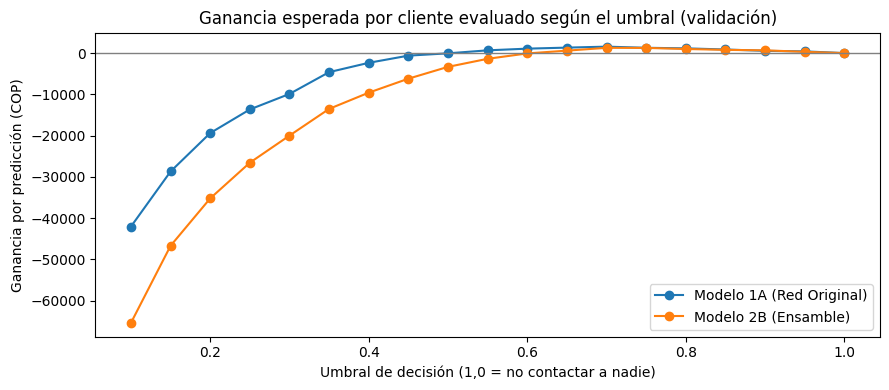

,Umbral,Recall,Tasa de falsas alarmas,Precisión en el banco,Ganancia por predicción
Modelo,,,,,
Modelo 1A (Red Original),0.7,0.2482,0.0050,0.8971,1564.4146
Modelo 2B (Ensamble),0.7,0.2973,0.0107,0.8310,1277.9160


In [76]:
umbrales = np.append(np.round(np.arange(0.10, 0.96, 0.05), 2), 1.0)
barrido = pd.concat([
    pd.DataFrame([evaluar_campania(y_val.values, prob, u, valor_base, costo_contacto) for u in umbrales]).assign(Modelo=nombre)
    for nombre, prob in prob_val.items()], ignore_index=True)
mejor_umbral = barrido.loc[barrido.groupby("Modelo")["Ganancia por predicción"].idxmax()].set_index("Modelo")

fig, ax = plt.subplots(figsize=(9, 4))
for nombre, grupo in barrido.groupby("Modelo"):
    ax.plot(grupo["Umbral"], grupo["Ganancia por predicción"], marker="o", label=nombre)
ax.axhline(0, color="gray", linewidth=1)
ax.set_xlabel("Umbral de decisión (1,0 = no contactar a nadie)")
ax.set_ylabel("Ganancia por predicción (COP)")
ax.set_title("Ganancia esperada por cliente evaluado según el umbral (validación)")
ax.legend()
plt.tight_layout()
plt.show()

mejor_umbral.round(4)

Los dos modelos alcanzan su máxima ganancia con un umbral de 0,70. La precisión en el banco sube a 89,7% en la red y 83,1% en el ensamble, por encima del 71,8% de equilibrio, a cambio de un recall bajo: 24,8% y 29,7%. La red gana en validación (COP 1.564 frente a 1.278 por cliente evaluado) y se elige, también por ser el modelo más simple. Con márgenes tan estrechos pesa más equivocarse poco que detectar mucho, y por eso la red, más precisa, supera al ensamble aunque este tuviera mejor F1 con el umbral de 0,5.

## Resultado esperado para el banco

In [77]:
alternativas = {nombre: (prob_test[nombre], fila["Umbral"]) for nombre, fila in mejor_umbral.iterrows()}
alternativas["Sin modelo: contactar a todos"] = (prob_test["Modelo 2B (Ensamble)"], 0.0)

filas = []
for nombre, (prob, umbral) in alternativas.items():
    r = evaluar_campania(y_test.values, prob, umbral, valor_base, costo_contacto)
    contactados = CLIENTES_BANCO * (TASA_ABANDONO * r["Recall"] + (1 - TASA_ABANDONO) * r["Tasa de falsas alarmas"])
    retenidos = CLIENTES_BANCO * TASA_ABANDONO * r["Recall"] * EFECTIVIDAD
    beneficio = CLIENTES_BANCO * r["Ganancia por predicción"]
    filas.append({"Alternativa": nombre, "Umbral": umbral, "Precisión en el banco (%)": 100 * r["Precisión en el banco"],
                  "Recall (%)": 100 * r["Recall"], "Ganancia por predicción (COP)": r["Ganancia por predicción"],
                  "Clientes contactados al año": contactados, "Clientes retenidos al año": retenidos,
                  "Costo de la campaña (millones COP)": contactados * costo_contacto / 1e6,
                  "Valor retenido (millones COP)": retenidos * valor_base / 1e6,
                  "Beneficio neto anual (millones COP)": beneficio / 1e6,
                  "Meses para recuperar la inversión": INVERSION / (beneficio / 12) if beneficio > 0 else np.nan,
                  "ROI a 12 meses (%)": 100 * (beneficio - INVERSION) / INVERSION})
resultado_base = pd.DataFrame(filas).set_index("Alternativa")
resultado_base.T.round(2)

Alternativa,Modelo 1A (Red Original),Modelo 2B (Ensamble),Sin modelo: contactar a todos
Umbral,0.70,0.70,0.00
Precisión en el banco (%),88.37,82.28,15.00
Recall (%),24.32,29.73,100.00
Ganancia por predicción (COP),1440.29,1197.51,-119191.68
Clientes contactados al año,825.77,1083.98,20000.00
Clientes retenidos al año,218.92,267.57,900.00
Costo de la campaña (millones COP),124.44,163.35,3013.83
Valor retenido (millones COP),153.24,187.30,630.00
Beneficio neto anual (millones COP),28.81,23.95,-2383.83
Meses para recuperar la inversión,29.99,36.07,NaN


En prueba, la red genera COP 1.440 por cliente evaluado. En los 20.000 clientes del banco contactaría a unos 826 al año (4% de la cartera), retendría a unos 219 y dejaría un beneficio neto de COP 28,8 millones (153 millones en ingreso retenido menos 124 en ofertas). Con ese beneficio la inversión de COP 72 millones se recupera en unos 30 meses y el ROI a 12 meses es de −60%: el modelo genera valor, pero no se paga en el primer año. El ensamble deja COP 24,0 millones y tardaría 36 meses. Contactar a todos retendría a 900 clientes, pero costaría COP 3.014 millones para recuperar 630, una pérdida de COP 2.384 millones al año. Como el cliente se valora por ingreso y no por margen, el beneficio real sería menor; como solo se cuenta un año, sería mayor si los clientes retenidos se quedan más tiempo.

## Análisis de sensibilidad

El costo de la oferta y el ingreso de los clientes retenidos son los supuestos que más mueven el resultado. El mapa recorre ofertas entre COP 35.000 y 210.000 (del 5% al 30% del ingreso base) en los tres escenarios de ingreso. En cada caso el umbral se vuelve a elegir en validación, como haría el banco, y el beneficio se mide en prueba; un beneficio de cero significa que lo mejor es no contactar a nadie.

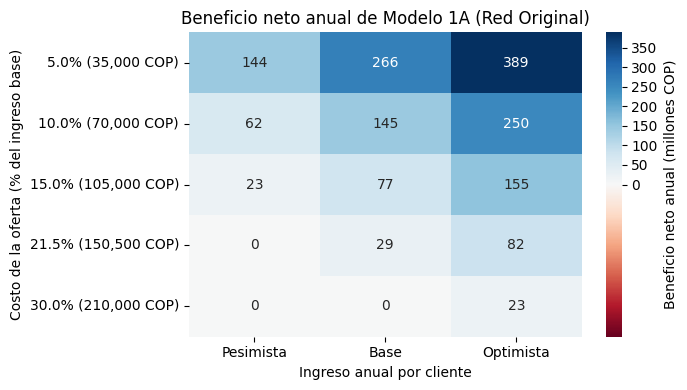

,Pesimista,Base,Optimista
"5.0% (35,000 COP)",0.25,0.25,0.25
"10.0% (70,000 COP)",0.45,0.45,0.35
"15.0% (105,000 COP)",0.70,0.50,0.45
"21.5% (150,500 COP)",1.00,0.70,0.60
"30.0% (210,000 COP)",1.00,1.00,0.70


In [78]:
modelo_elegido = mejor_umbral["Ganancia por predicción"].idxmax()
costos_pct = [0.05, 0.10, 0.15, 0.215, 0.30]

beneficio_sens = pd.DataFrame(index=[f"{c:.1%} ({c * INGRESO_ANUAL:,.0f} COP)" for c in costos_pct], columns=list(ESCENARIOS_INGRESO.keys()), dtype=float)
umbral_sens = beneficio_sens.copy()
for c_pct, fila in zip(costos_pct, beneficio_sens.index):
    costo = c_pct * INGRESO_ANUAL + COSTO_SMS
    for escenario, ingreso in ESCENARIOS_INGRESO.items():
        val = pd.DataFrame([evaluar_campania(y_val.values, prob_val[modelo_elegido], u, ingreso, costo) for u in umbrales])
        u_opt = val.loc[val["Ganancia por predicción"].idxmax(), "Umbral"]
        beneficio_sens.loc[fila, escenario] = CLIENTES_BANCO * evaluar_campania(y_test.values, prob_test[modelo_elegido], u_opt, ingreso, costo)["Ganancia por predicción"] / 1e6
        umbral_sens.loc[fila, escenario] = u_opt

beneficio_sens = beneficio_sens + 0.0

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(beneficio_sens, annot=True, fmt=".0f", cmap="RdBu", norm=TwoSlopeNorm(vmin=min(beneficio_sens.values.min(), -1), vcenter=0, vmax=max(beneficio_sens.values.max(), 1)), cbar_kws={"label": "Beneficio neto anual (millones COP)"}, ax=ax)
ax.set_xlabel("Ingreso anual por cliente")
ax.set_ylabel("Costo de la oferta (% del ingreso base)")
ax.set_title(f"Beneficio neto anual de {modelo_elegido}")
plt.tight_layout()
plt.show()

umbral_sens

El costo de la oferta es la palanca principal del caso. Con la oferta actual el beneficio va de cero en el escenario pesimista, donde no conviene contactar a nadie, a COP 82 millones en el optimista. Si la oferta baja al 10% del ingreso base (COP 70.000), el beneficio del escenario base sube a COP 145 millones al año y sigue siendo positivo en el pesimista (COP 62 millones); con una oferta de COP 35.000 llega a 266 millones. La tabla de umbrales muestra la otra cara de la decisión: con ofertas baratas conviene contactar a más clientes (umbral de 0,25) y con ofertas caras solo a los de riesgo muy alto, o a ninguno.

In [79]:
equilibrio = pd.DataFrame(index=[f"{m} meses" for m in (2, 3, 4)], columns=list(ESCENARIOS_INGRESO.keys()), dtype=float)
for escenario, ingreso in ESCENARIOS_INGRESO.items():
    val = pd.DataFrame([evaluar_campania(y_val.values, prob_val[modelo_elegido], u, ingreso, costo_contacto) for u in umbrales])
    u_opt = val.loc[val["Ganancia por predicción"].idxmax(), "Umbral"]
    beneficio = CLIENTES_BANCO * evaluar_campania(y_test.values, prob_test[modelo_elegido], u_opt, ingreso, costo_contacto)["Ganancia por predicción"]
    for meses in (2, 3, 4):
        equilibrio.loc[f"{meses} meses", escenario] = SALARIOS_EQUIPO * meses / (beneficio / 12) if beneficio > 0 else np.nan
equilibrio.columns.name = "Escenario de ingreso"
equilibrio.index.name = "Duración del proyecto"
equilibrio.round(1)

Escenario de ingreso,Pesimista,Base,Optimista
Duración del proyecto,,,
2 meses,NaN,20.0,7.0
3 meses,NaN,30.0,10.5
4 meses,NaN,40.0,14.0


Con la oferta actual, la inversión se recupera en 20 a 40 meses en el escenario base, según el proyecto dure de 2 a 4 meses, en 7 a 14 meses en el optimista y nunca en el pesimista. La duración del proyecto mueve poco la decisión: el riesgo del caso está en pagar una oferta cara frente a lo que deja un año de ingreso.

## Limitaciones

Construcción del modelo. Se entrenó con 10.000 clientes de un banco europeo y se aplica a uno colombiano, suponiendo que su capacidad para separar a quienes se van se mantiene. Ajustar la tasa de abandono al 15% corrige la proporción de clientes que se van, no su comportamiento. El país de residencia, una de las cuatro variables más influyentes, no existe en Colombia, y el número de productos o el saldo pueden significar otra cosa en un mercado con muchos depósitos digitales de bajo monto. Es una prueba de concepto: para usarlo hay que reentrenarlo con clientes colombianos.

Datos. La base es una fotografía sin tiempo, así que el modelo dice quién tiene más riesgo, no cuándo se irá. Algunos patrones descansan en grupos pequeños (326 clientes con tres o más productos), la limpieza diluyó señales en los extremos, el umbral se eligió con 2.000 clientes de validación y las probabilidades del ensamble no están calibradas.

Desempeño. Con el umbral elegido, el modelo solo llega a cerca de una cuarta parte de los clientes que se van; a cambio, casi 9 de cada 10 ofertas llegan a clientes que sí se iban. El resto del abandono no se atiende con esta campaña.

Supuestos económicos. La efectividad del 30% no está medida en el banco. El valor del cliente usa ingreso y no margen, lo que sobrestima el beneficio, pero solo cuenta un año, lo que lo subestima si el cliente retenido se queda más tiempo. El costo de la oferta viene de la práctica y no de una cotización, y la inversión no incluye prestaciones, infraestructura ni mantenimiento.

Causalidad y uso responsable. El modelo predice quién se va, no quién cambia de decisión por la oferta; medir ese efecto exige un experimento con grupo de control. Además, el género está entre las variables relevantes y no debería usarse para decidir a quién ofrecer un beneficio.

## Conclusiones para el negocio

Usar el modelo es mejor que no usarlo, pero con la oferta actual el beneficio es modesto. Contactar a todos perdería COP 2.384 millones al año; con la red y un umbral de 0,70 el banco contacta solo al 4% de la cartera, casi 9 de cada 10 contactados realmente se iban y la campaña deja COP 28,8 millones al año. La inversión se recupera en unos 30 meses, así que el modelo no se paga en el primer año.

El problema no es el modelo sino la oferta. Cuesta el 21,5% del ingreso anual y, cuando acierta, solo recupera el 30% de ese ingreso, de modo que un error cuesta más de lo que deja un acierto. Bajar la oferta a cerca del 10% del ingreso (COP 70.000) multiplica por cinco el beneficio del escenario base, hasta COP 145 millones, y lo mantiene positivo con clientes de menor ingreso. Por eso se recomienda rediseñar la oferta antes de lanzar la campaña y usar el umbral como regla de operación: más bajo con ofertas baratas y más alto con ofertas caras.

Medir un solo año es conservador. Si los clientes retenidos se quedan más tiempo, el valor de retenerlos crece y el caso mejora, pero eso hay que medirlo. El siguiente paso es un piloto con grupo de control para medir la efectividad, la permanencia y el margen reales, y reentrenar el modelo con clientes colombianos.

## Anexo: caso de la práctica (banco europeo)

Este anexo conserva el cálculo de la práctica de clase que guió el taller: banco europeo, valores y costos por país en euros, efectividad del 50%, inversión de 79.750 € y el ensamble con umbral de 0,5.

In [80]:
PRACTICA = {"Francia": (900, 220), "Alemania": (1_500, 300), "España": (850, 150)}
EFECTIVIDAD_PRACTICA = 0.50
INVERSION_PRACTICA = 79_750

pais_cartera = np.select([df_P4["country_Germany"] == 1, df_P4["country_Spain"] == 1], ["Alemania", "España"], "Francia")
pais_test = np.select([X_test_orig["country_Germany"] == 1, X_test_orig["country_Spain"] == 1], ["Alemania", "España"], "Francia")
pred_practica = prob_test["Modelo 2B (Ensamble)"] >= 0.5

anexo = []
for pais, (valor, costo) in PRACTICA.items():
    en_pais = pais_test == pais
    tp = (pred_practica & (y_test.values == 1) & en_pais).sum()
    fp = (pred_practica & (y_test.values == 0) & en_pais).sum()
    ganancia_cliente = (tp * (EFECTIVIDAD_PRACTICA * valor - costo) - fp * costo) / en_pais.sum()
    anexo.append({"País": pais, "Clientes en cartera": (pais_cartera == pais).sum(),
                  "Precisión de equilibrio": costo / (EFECTIVIDAD_PRACTICA * valor),
                  "Precisión en prueba": tp / (tp + fp),
                  "Beneficio mensual (€)": ganancia_cliente * (pais_cartera == pais).sum() / 12})
anexo = pd.DataFrame(anexo).set_index("País")
print(f"Beneficio mensual total: {anexo['Beneficio mensual (€)'].sum():,.0f} € | Meses para recuperar {INVERSION_PRACTICA:,} €: {INVERSION_PRACTICA / anexo['Beneficio mensual (€)'].sum():.2f}")
anexo.round(4)

Beneficio mensual total: 20,893 € | Meses para recuperar 79,750 €: 3.82


,Clientes en cartera,Precisión de equilibrio,Precisión en prueba,Beneficio mensual (€)
País,,,,
Francia,5014,0.4889,0.6847,4053.9782
Alemania,2509,0.4000,0.7181,14631.7175
España,2477,0.3529,0.6429,2207.0377


El caso europeo genera unos 20.893 € al mes y recupera la inversión en 3,82 meses, por encima de la meta de tres meses de la práctica. Alemania aporta el 70% del beneficio (14.632 €) con el 25% de los clientes, por su mayor valor por cliente y mayor abandono, y los tres países superan su precisión de equilibrio. La diferencia con el caso colombiano está en la efectividad: con 50% de clientes convencidos, en la práctica basta con precisiones de 35% a 49%, mientras que aquí, con 30% y un año de ingreso, se necesita 71,8%.

# Declaracion de uso de IA Generativa

La declaración de uso de IA generativa, con los modelos usados, el porcentaje de ayuda y los prompts, está en el README.md del repositorio.